# Run 15 physical CO₂ collection — final 18.0 m³ RQ3 AD evaluation

This notebook evaluates three Run 15 collections using the **AD room volume of 18.0 m³**. Every no-ventilation counterfactual also uses 18.0 m³. The earlier 18.5 m³ evaluation is retained only as legacy detector-development evidence. The fan map, ventilation factor, residual thresholds, and persistence settings are inherited from that earlier development chain and are not refitted on Run 15; consequently, this is a final-configuration transfer evaluation rather than a claim that every operating parameter was newly calibrated at 18.0 m³.

The evaluation has three layers, kept in separate tables:

1. **Physical transfer check.** Rule baseline, fan residual, and mass-balance CO₂ residual on the command windows and on the full record. Every physical label is normal, so physical recall and F1 are not applicable.
2. **Command-window alterations.** The alterations are S05 and S12 at every command; S06 at a measured exhaust speed reduced by 30%; S07 at blend fractions 0.50 and 0.75, for 21:56 at 80% (blend fraction 0.75) and 100% (blend fractions 0.50 and 0.75), 12:39 at 80% and 100% (blend fractions 0.50 and 0.75), and 14:12 at 100% (blend fractions 0.50 and 0.75); S08 at 300, 1,000, and 2,000 RPM; S09 at every command except 14:12 60%; and S11 at +500 ppm.
3. **Full-record replay.** S07, S09, and S12 are written onto the whole record. Those cases are then scored by any flag in the labelled interval, by command window, by new flags after 40 seconds of phase time, and by the flat overlap score of Tatbul et al. (2018).

Evaluated records in `datasets/`:

| Collection | Run 15 campaign | Source record |
| --- | --- | --- |
| 8 October 2026, 21:56 | `EXP_RQ3_CO2_RUN15_PHYS_20261008_215609` | `EXP_RQ2_MATCHED_20261008_215609` |
| 9 October 2026, 12:39 | `EXP_RQ3_CO2_RUN15_PHYS_20261009_123920` | `EXP_RQ2_MATCHED_20261009_123921` |
| 10 October 2026, 14:12 | `EXP_RQ3_CO2_RUN15_PHYS_20261010_141227` | `EXP_RQ2_MATCHED_20261010_141227` |

All campaign manifests label these repetitions `HELD_OUT_TEST` under profile `RUN15_OPENING_RECOVERY`, and no AD threshold or fan map is fitted on them. However, the 8 October 21:56 record was used separately to select simulation ventilation factors, so it is calibration-linked simulation evidence rather than independent simulation validation. For AD transfer it remains out-of-fit because the detector parameters were frozen elsewhere. The 9 October 12:39 and 10 October 14:12 records are the primary held-out records. The extracted series keeps the 10-minute command windows at 100%, 80%, and 60%. The full record also keeps the fan-off qualification intervals, including the opening CO₂ rise before the first command window.


Saved results and plots are included below; no rerun is needed to inspect them. Regeneration is optional.

Scope: the three evaluated Run 15 records. Historical detector-development datasets are not distributed; inherited frozen numerical parameters remain explicit in this notebook.

## What this evaluation holds fixed—and what it changes

The AD room volume is **18.0 m³**. The fan-speed map, ventilation factor, residual thresholds, persistence rule, and narrow rule baseline were inherited from the earlier physical fan-residual and physical CO₂ residual development collections and are not refitted on Run 15. The legacy development evaluation used 18.5 m³. Consequently, `refit_on_run15 = false` means that no parameter was estimated from these Run 15 outcomes; the final 18.0 m³ configuration is evaluated as a transfer of those previously fixed operating parameters.

| Quantity | Value used here |
| --- | --- |
| Room volume | 18.0 m³ |
| Occupied CO₂ generation | 4.2 × 10⁻⁶ m³/s |
| Ventilation factor ηᵥ | 0.400 |
| Nominal fan flow scale | 339.582 m³/h at 2860 RPM |
| CO₂ residual threshold | 3.580455 ppm |
| CO₂ persistence | 2 consecutive exceedances |
| Fan residual threshold | 220.600 RPM |
| Rule baseline | command ≥ 1% and measured exhaust RPM < 300 |

The first sample after each new fan command is still accelerating. Fan-residual alarm counts exclude that sample. The sample remains visible on the fan chart.

Physical rows in these records are labelled normal. Physical anomaly recall and F1 are therefore not applicable. Recall is estimated only on S07 replay cases built from the same command windows. These cases alter a copy of the measured series. They are not additional physical faults.

Event detection follows the project rule already used for S07: a case is detected when at least one detector flag falls inside the labelled interval. That asks only whether any flag falls in the labelled interval. It is not the full range-overlap score of Tatbul et al. (2018). The generation term follows the occupied CO₂-generation basis discussed by Persily and de Jonge (2017) and Persily and Polidoro (2022), at the project value 4.2 × 10⁻⁶ m³/s.

- Persily, A. K., & de Jonge, L. (2017). Carbon dioxide generation rates for building occupants. *Indoor Air, 27*(5), 868–879. [doi:10.1111/ina.12383](https://doi.org/10.1111/ina.12383)
- Persily, A., & Polidoro, B. (2022). *Indoor carbon dioxide metric analysis tool* (NIST Technical Note 2213). [doi:10.6028/NIST.TN.2213](https://doi.org/10.6028/NIST.TN.2213)
- Tatbul, N., Lee, T. J., Zdonik, S., Alam, M., & Gottschlich, J. (2018). Precision and recall for time series. *Advances in Neural Information Processing Systems, 31*.


## Detector equations

**Rule baseline.** Flag the sample when the exhaust command is at least 1% and the measured exhaust speed is below 300 RPM.

**Fan residual.** Expected exhaust speed is the piecewise-linear map fixed on the physical fan-residual parameterisation repetition:

| Command (%) | Expected RPM |
| --- | ---: |
| 0 | 0.0 |
| 30 | 1135.9 |
| 50 | 1491.1 |
| 60 | 1852.9 |
| 70 | 2093.0 |
| 80 | 2257.4 |
| 100 | 2812.5 |

Outside the table, the nearest endpoint is used. The residual is

$$r = \mathrm{RPM}_{observed} - \mathrm{RPM}_{expected}(\mathrm{PWM}).$$

A sample after that first sample is flagged when \(|r| > 220.600\) RPM.

**Mass-balance CO₂ residual.** Let \(V = 18\) m³, \(G\) be 4.2 × 10⁻⁶ m³/s when occupancy is present and 0 otherwise, and \(\overline{\mathrm{RPM}}\) be the mean of the available fan speeds. Nominal flow and the one-step prediction are

$$Q_{nom} = 339.58222809255017 \times \frac{\overline{\mathrm{RPM}}}{2860}, \qquad q = \frac{0.400 \, Q_{nom}}{3600}.$$

When \(q > 0\),

$$k = q / V, \qquad C_{ss} = C_{out} + (G / q) \times 10^6, \qquad \hat C_{t+1} = C_{ss} + (C_t - C_{ss}) e^{-k \Delta t}.$$

When \(q = 0\),

$$\hat C_{t+1} = C_t + (G / V) \times 10^6 \, \Delta t.$$

The score is the one-sided residual \(\max(0, C_{t+1} - \hat C_{t+1})\). A flag requires two consecutive residuals above 3.580455 ppm. The counter resets when the residual is missing, \(\Delta t \le 0\), \(\Delta t > 15\) s, or no fan speed is available. A missing outdoor concentration falls back to 420 ppm.

**S07 replay.** For each command window, the first 60 s stay equal to the physical CO₂ series. After onset,

$$C_{\mathrm{altered}} = C_{physical} + s \left(C_{no\ ventilation} - C_{physical}\right),$$

$$C_{no\ ventilation} = C_{onset} + (G / V) \times 10^6 \, \Delta t,$$

with \(V = 18\) m³ and blend fraction \(s \in \{0.50, 0.75\}\). The cases are 21:56 at 80% with blend fraction 0.75 and at 100% with blend fraction 0.50 and blend fraction 0.75, 12:39 at 80% and 100% for blend fractions 0.50 and 0.75, and 14:12 at 100% for blend fractions 0.50 and 0.75. Commands, fan speeds, occupancy, openings, outdoor CO₂, and timestamps stay on the physical values.


In [1]:
from __future__ import annotations

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "notebooks").is_dir() and (p / "src" / "indoortwin" / "paths.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT / "src"))
PACKAGE_DIR = REPO_ROOT
RECORD_DIR = REPO_ROOT / "data/rq3"
OUT = REPO_ROOT / "results/rq3_anomaly"
TABLES, FIGURES, TEXT = OUT / "tables", OUT / "figures", OUT / "text"
for folder in (TABLES, FIGURES, TEXT):
    folder.mkdir(parents=True, exist_ok=True)
ROOM_VOLUME_M3 = 18.0
ETA_V = 0.400
CO2_GENERATION_M3_S = 4.2e-6
CO2_THRESHOLD_PPM = 3.58045452396334
CO2_PERSISTENCE = 2
FAN_THRESHOLD_RPM = 220.6
RULE_RPM_LIMIT = 300.0
Q_NOM_AT_REFERENCE_M3H = 339.58222809255017
REFERENCE_RPM = 2860.0
OUTDOOR_FALLBACK_PPM = 420.0
MAX_STEP_S = 15.0
ANOMALY_ONSET_S = 60.0
DUTIES = (60, 80, 100)
SEVERITIES = (("0.50", 0.50), ("0.75", 0.75))
FAN_MAP = (
    (0.0, 0.0),
    (30.0, 1135.9),
    (50.0, 1491.1),
    (60.0, 1852.9),
    (70.0, 2093.0),
    (80.0, 2257.4),
    (100.0, 2812.5),
)
RECORDS = [
    {
        "experiment_id": "EXP_RQ3_CO2_RUN15_PHYS_20261008_215609",
        "collection": "8 October 2026, 21:56",
        "short": "8 Oct 2026 21:56",
        "matched_start_id": "EXP_RQ2_MATCHED_20261008_215609",
    },
    {
        "experiment_id": "EXP_RQ3_CO2_RUN15_PHYS_20261009_123920",
        "collection": "9 October 2026, 12:39",
        "short": "9 Oct 2026 12:39",
        "matched_start_id": "EXP_RQ2_MATCHED_20261009_123921",
    },
    {
        "experiment_id": "EXP_RQ3_CO2_RUN15_PHYS_20261010_141227",
        "collection": "10 October 2026, 14:12",
        "short": "10 Oct 2026 14:12",
        "matched_start_id": "EXP_RQ2_MATCHED_20261010_141227",
    },
]

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def expected_rpm(pwm: float) -> float:
    if pwm <= FAN_MAP[0][0]:
        return FAN_MAP[0][1]
    if pwm >= FAN_MAP[-1][0]:
        return FAN_MAP[-1][1]
    for (x0, y0), (x1, y1) in zip(FAN_MAP, FAN_MAP[1:]):
        if x0 <= pwm <= x1:
            weight = (pwm - x0) / (x1 - x0)
            return y0 + weight * (y1 - y0)
    return FAN_MAP[-1][1]


def generation_m3_s(occupancy: str) -> float:
    return CO2_GENERATION_M3_S if str(occupancy).upper() == "PRESENT" else 0.0


def nominal_flow_m3h(mean_rpm: float) -> float:
    return Q_NOM_AT_REFERENCE_M3H * (mean_rpm / REFERENCE_RPM)


def predict_co2(current_ppm: float, outdoor_ppm: float, generated_m3_s: float, flow_m3h: float, dt_s: float) -> float:
    flow_m3s = flow_m3h / 3600.0
    if flow_m3s <= 1e-12:
        return current_ppm + (generated_m3_s / ROOM_VOLUME_M3) * 1e6 * dt_s
    rate = flow_m3s / ROOM_VOLUME_M3
    steady = outdoor_ppm + (generated_m3_s / flow_m3s) * 1e6
    return steady + (current_ppm - steady) * math.exp(-rate * dt_s)


def episode_count(flags: list[bool]) -> int:
    count = 0
    previous = False
    for flag in flags:
        current = bool(flag)
        if current and not previous:
            count += 1
        previous = current
    return count


def section_name(phase: str, trial: int) -> str:
    phase_text = str(phase)
    if phase_text.startswith("duty"):
        return "duty_window"
    if int(trial) == 1:
        return "opening_fan_off"
    return "between_duty_fan_off"


def load_labels(path: Path) -> pd.DataFrame:
    rows = [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]
    return pd.DataFrame(rows)


def load_canonical(record: dict) -> pd.DataFrame:
    folder = RECORD_DIR / record["experiment_id"]
    frame = pd.read_csv(folder / "rq3_physical_trace.csv", parse_dates=["timestamp"])
    frame = frame.drop(columns=["scenario_id"], errors="ignore")
    frame = frame.sort_values("timestamp").reset_index(drop=True)
    frame["collection"] = record["collection"]
    frame["short"] = record["short"]
    frame["experiment_id"] = record["experiment_id"]
    frame["scope"] = "command_windows"
    frame["phase"] = frame["fan_exh_pwm_percent"].map(lambda value: f"duty_{int(round(value))}_percent")
    frame["trial"] = frame["phase"].ne(frame["phase"].shift()).cumsum()
    frame["section"] = "duty_window"
    return frame


def load_matched(record: dict) -> pd.DataFrame:
    folder = RECORD_DIR / record["experiment_id"]
    matches = sorted(folder.glob("raw_runs/rep_1/rq2/EXP_RQ2_MATCHED_*/rq2_matched_start.csv"))
    if len(matches) != 1:
        raise FileNotFoundError(f"{record['experiment_id']} record files: {matches}")
    raw = pd.read_csv(matches[0], parse_dates=["sample_time"]).sort_values("sample_time")
    frame = pd.DataFrame({
        "timestamp": raw["sample_time"],
        "elapsed_s": raw["elapsed_seconds"],
        "phase": raw["phase"],
        "trial": raw["trial"],
        "co2_indoor_ppm": raw["co2_indoor_ppm"],
        "co2_outdoor_ppm": raw["co2_outdoor_ppm"],
        "occupancy": raw["occupancy"],
        "fan_exh_pwm_percent": raw["fan_exh_pwm_setpoint"],
        "fan_exh_rpm": raw["fan_exh_rpm"],
        "fan_in_01_rpm": raw["fan_in1_rpm"],
        "fan_in_02_rpm": raw["fan_in2_rpm"],
        "door_state": raw["door_state"],
        "window_state": raw["window_state"],
    })
    frame["collection"] = record["collection"]
    frame["short"] = record["short"]
    frame["experiment_id"] = record["experiment_id"]
    frame["scope"] = "full_record"
    frame["section"] = [section_name(phase, trial) for phase, trial in zip(frame["phase"], frame["trial"])]
    return frame.reset_index(drop=True)


def score_frame(frame: pd.DataFrame) -> pd.DataFrame:
    scored = frame.copy().reset_index(drop=True)
    segment = scored["phase"].ne(scored["phase"].shift()) | scored["trial"].ne(scored["trial"].shift())
    scored["segment_id"] = segment.cumsum()
    scored["sample_in_segment"] = scored.groupby("segment_id").cumcount()
    scored["settling_sample"] = (scored["sample_in_segment"] == 0) & (scored["fan_exh_pwm_percent"] >= 1)
    n = len(scored)
    expected = np.full(n, np.nan)
    fan_residual = np.full(n, np.nan)
    rule_flag = np.zeros(n, dtype=bool)
    fan_flag = np.zeros(n, dtype=bool)
    prediction = np.full(n, np.nan)
    positive_residual = np.full(n, np.nan)
    co2_flag = np.zeros(n, dtype=bool)
    valid_step = np.zeros(n, dtype=bool)
    persistence = 0
    for index in range(n):
        pwm = float(scored.at[index, "fan_exh_pwm_percent"])
        rpm = scored.at[index, "fan_exh_rpm"]
        expected[index] = expected_rpm(pwm)
        if pd.notna(rpm):
            fan_residual[index] = float(rpm) - expected[index]
            rule_flag[index] = pwm >= 1.0 and float(rpm) < RULE_RPM_LIMIT
            fan_flag[index] = abs(fan_residual[index]) > FAN_THRESHOLD_RPM
        if index == 0:
            continue
        dt = (scored.at[index, "timestamp"] - scored.at[index - 1, "timestamp"]).total_seconds()
        previous = scored.iloc[index - 1]
        rpms = [float(previous[name]) for name in ("fan_exh_rpm", "fan_in_01_rpm", "fan_in_02_rpm") if pd.notna(previous[name])]
        current_co2 = previous["co2_indoor_ppm"]
        observed = scored.at[index, "co2_indoor_ppm"]
        if pd.isna(current_co2) or pd.isna(observed) or dt <= 0 or dt > MAX_STEP_S or not rpms:
            persistence = 0
            continue
        outdoor = previous["co2_outdoor_ppm"] if pd.notna(previous["co2_outdoor_ppm"]) else OUTDOOR_FALLBACK_PPM
        flow = ETA_V * max(0.0, nominal_flow_m3h(sum(rpms) / len(rpms)))
        predicted = predict_co2(float(current_co2), float(outdoor), generation_m3_s(previous["occupancy"]), flow, dt)
        residual = max(0.0, float(observed) - predicted)
        prediction[index] = predicted
        positive_residual[index] = residual
        valid_step[index] = True
        persistence = persistence + 1 if residual > CO2_THRESHOLD_PPM else 0
        co2_flag[index] = persistence >= CO2_PERSISTENCE
    scored["expected_rpm"] = expected
    scored["fan_residual_rpm"] = fan_residual
    scored["rule_flag"] = rule_flag
    scored["fan_flag_raw"] = fan_flag
    scored["fan_flag"] = fan_flag & ~scored["settling_sample"].to_numpy()
    scored["co2_prediction_ppm"] = prediction
    scored["co2_positive_residual_ppm"] = positive_residual
    scored["co2_flag"] = co2_flag
    scored["valid_co2_step"] = valid_step
    return scored


def summarise_scope(scored: pd.DataFrame, section: str | None = None) -> dict:
    part = scored if section is None else scored.loc[scored["section"] == section]
    valid_dt = []
    timestamps = part["timestamp"].tolist()
    for left, right in zip(timestamps, timestamps[1:]):
        dt = (right - left).total_seconds()
        if 0 < dt <= MAX_STEP_S:
            valid_dt.append(dt)
    hours = sum(valid_dt) / 3600.0
    steady = part.loc[~part["settling_sample"]]
    co2_flags = int(part["co2_flag"].sum())
    scored_steps = int(part["valid_co2_step"].sum())
    return {
        "samples": int(len(part)),
        "scored_co2_steps": scored_steps,
        "exposure_h": hours,
        "rule_flags": int(part["rule_flag"].sum()),
        "rule_episodes": episode_count(part["rule_flag"].tolist()),
        "fan_settling_flags": int((part["fan_flag_raw"] & part["settling_sample"]).sum()),
        "fan_steady_flags": int(part["fan_flag"].sum()),
        "fan_steady_episodes": episode_count(part["fan_flag"].tolist()),
        "fan_steady_max_abs_rpm": float(steady["fan_residual_rpm"].abs().max()) if len(steady) else math.nan,
        "co2_flags": co2_flags,
        "co2_flagged_percent": (100.0 * co2_flags / scored_steps) if scored_steps else math.nan,
        "co2_episodes": episode_count(part["co2_flag"].tolist()),
        "co2_episodes_per_h": (episode_count(part["co2_flag"].tolist()) / hours) if hours else math.nan,
    }


def duty_transfer(scored: pd.DataFrame) -> pd.DataFrame:
    duty = scored.loc[scored["section"] == "duty_window"].copy()
    duty = duty.loc[~duty["settling_sample"]]
    rows = []
    for (experiment_id, collection), group in duty.groupby(["experiment_id", "collection"], sort=False):
        for pwm, pwm_group in group.groupby(group["fan_exh_pwm_percent"].round().astype(int)):
            rows.append({
                "experiment_id": experiment_id,
                "collection": collection,
                "duty_percent": int(pwm),
                "samples": int(len(pwm_group)),
                "mean_rpm": float(pwm_group["fan_exh_rpm"].mean()),
                "expected_rpm": float(expected_rpm(float(pwm))),
                "mean_residual_rpm": float(pwm_group["fan_residual_rpm"].mean()),
                "max_abs_residual_rpm": float(pwm_group["fan_residual_rpm"].abs().max()),
                "steady_flags": int(pwm_group["fan_flag"].sum()),
            })
    return pd.DataFrame(rows)


FINAL_S07_CASES = {
    ("EXP_RQ3_CO2_RUN15_PHYS_20261008_215609", 80, "0.75"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261008_215609", 100, "0.50"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261008_215609", 100, "0.75"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261009_123920", 80, "0.50"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261009_123920", 80, "0.75"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261009_123920", 100, "0.50"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261009_123920", 100, "0.75"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261010_141227", 100, "0.50"),
    ("EXP_RQ3_CO2_RUN15_PHYS_20261010_141227", 100, "0.75"),
}
FINAL_S09_DUTIES = {
    "EXP_RQ3_CO2_RUN15_PHYS_20261008_215609": (100, 80, 60),
    "EXP_RQ3_CO2_RUN15_PHYS_20261009_123920": (100, 80, 60),
    "EXP_RQ3_CO2_RUN15_PHYS_20261010_141227": (100, 80),
}
SELECTED_SCENARIOS = ("S05", "S06", "S07", "S08", "S09", "S11", "S12")


def selected_duty(experiment_id, scenario, duty, severity) -> bool:
    duty = int(duty)
    if scenario == "S07":
        return (experiment_id, duty, severity) in FINAL_S07_CASES
    if scenario == "S09":
        return duty in FINAL_S09_DUTIES[experiment_id]
    return scenario in SELECTED_SCENARIOS


def inject_cases(canonical: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    cases = []
    index_rows = []
    for duty in DUTIES:
        duty_rows = canonical.loc[canonical["fan_exh_pwm_percent"].round() == duty].sort_values("timestamp")
        if duty_rows.empty:
            raise RuntimeError(f"missing duty {duty}")
        start = float(duty_rows["elapsed_s"].iloc[0])
        relative = duty_rows["elapsed_s"].to_numpy(dtype=float) - start
        onset_positions = np.flatnonzero(relative >= ANOMALY_ONSET_S)
        if len(onset_positions) == 0:
            raise RuntimeError(f"duty {duty} has no sample at the replay onset")
        onset_index = int(onset_positions[0])
        onset_s = float(relative[onset_index])
        onset_co2 = float(duty_rows["co2_indoor_ppm"].iloc[onset_index])
        for severity_name, severity in SEVERITIES:
            if (canonical["experiment_id"].iloc[0], duty, severity_name) not in FINAL_S07_CASES:
                continue
            case_id = f"{canonical['experiment_id'].iloc[0]}_D{duty}_{severity_name.upper()}"
            injected = duty_rows.copy().reset_index(drop=True)
            injected_co2 = []
            for row_index, source in injected.iterrows():
                physical = float(source["co2_indoor_ppm"])
                if row_index < onset_index:
                    injected_co2.append(physical)
                    continue
                dt = float(relative[row_index] - onset_s)
                generated = generation_m3_s(source["occupancy"])
                no_vent = onset_co2 + (generated / ROOM_VOLUME_M3) * 1e6 * dt
                injected_co2.append(physical + severity * (no_vent - physical))
            injected["co2_physical_ppm"] = injected["co2_indoor_ppm"]
            injected["co2_indoor_ppm"] = injected_co2
            injected["elapsed_s"] = relative
            injected["timestamp"] = pd.to_datetime(injected["timestamp"].iloc[0]) + pd.to_timedelta(relative, unit="s")
            injected["case_id"] = case_id
            injected["duty_percent"] = duty
            injected["severity_name"] = severity_name
            injected["severity_fraction"] = severity
            injected["onset_s"] = onset_s
            injected["label_anomaly"] = injected["elapsed_s"] >= onset_s
            injected["data_origin"] = "REPLAY"
            cases.append(injected)
            index_rows.append({
                "experiment_id": canonical["experiment_id"].iloc[0],
                "collection": canonical["collection"].iloc[0],
                "case_id": case_id,
                "duty_percent": duty,
                "severity_name": severity_name,
                "severity_fraction": severity,
                "rows": int(len(injected)),
                "onset_s": onset_s,
                "end_s": float(relative[-1]),
            })
    return pd.concat(cases, ignore_index=True), pd.DataFrame(index_rows)


def score_replay_case(case: pd.DataFrame) -> dict:
    scored = score_frame(case)
    anomaly = scored["label_anomaly"].to_numpy()
    normal = ~anomaly
    detected = bool(scored.loc[anomaly, "co2_flag"].any())
    prefix_flag = bool(scored.loc[normal, "co2_flag"].any())
    delay = math.nan
    if detected:
        first = scored.loc[anomaly & scored["co2_flag"], "elapsed_s"].iloc[0]
        delay = float(first - scored["onset_s"].iloc[0])
    return {
        "experiment_id": scored["experiment_id"].iloc[0],
        "collection": scored["collection"].iloc[0],
        "short": scored["short"].iloc[0],
        "case_id": scored["case_id"].iloc[0],
        "duty_percent": int(scored["duty_percent"].iloc[0]),
        "severity_name": scored["severity_name"].iloc[0],
        "severity_fraction": float(scored["severity_fraction"].iloc[0]),
        "detected": detected,
        "prefix_false_positive": prefix_flag,
        "delay_s": delay,
        "anomaly_flags": int(scored.loc[anomaly, "co2_flag"].sum()),
        "normal_flags": int(scored.loc[normal, "co2_flag"].sum()),
        "max_positive_residual_ppm": float(scored["co2_positive_residual_ppm"].max()),
    }


def binary_metrics(case_results: pd.DataFrame) -> dict:
    tp = int(case_results["detected"].sum())
    fp = int(case_results["prefix_false_positive"].sum())
    fn = int((~case_results["detected"]).sum())
    precision = tp / (tp + fp) if (tp + fp) else math.nan
    recall = tp / (tp + fn) if (tp + fn) else math.nan
    if pd.notna(precision) and pd.notna(recall) and (precision + recall) > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = math.nan
    delays = case_results.loc[case_results["detected"], "delay_s"]
    return {
        "cases": int(len(case_results)),
        "detected": tp,
        "prefix_false_positives": fp,
        "missed": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "median_delay_s": float(delays.median()) if len(delays) else math.nan,
        "max_delay_s": float(delays.max()) if len(delays) else math.nan,
    }


def save_figure(figure: plt.Figure, stem: str) -> None:
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight")
    figure.savefig(FIGURES / f"{stem}.svg", bbox_inches="tight")
    plt.close("all")
    plt.close(figure)


print(f"Room volume {ROOM_VOLUME_M3:.1f} m³")
print(f"Records directory {RECORD_DIR}")


Room volume 18.0 m³
Records directory C:\Users\AMN\Downloads\~COMP971~\tmp\Examiner evidence verification\data\rq3


In [2]:
canonical_frames = []
matched_frames = []
provenance = []
for record in RECORDS:
    folder = RECORD_DIR / record["experiment_id"]
    summary = json.loads((folder / "rq3_co2_collection_summary.json").read_text(encoding="utf-8"))
    labels = load_labels(folder / "rq3_labels.jsonl")
    canonical = load_canonical(record)
    matched = load_matched(record)
    run = summary["run_index"][0]
    if run["source_stop_reason"] != "COMPLETE" or run["split_role"] != "HELD_OUT_TEST":
        raise RuntimeError(f"{record['experiment_id']} is not a complete held-out collection")
    if int((labels["label_anomaly"] != 0).sum()) != 0:
        raise RuntimeError(f"{record['experiment_id']} contains a physical anomaly label")
    canonical_frames.append(canonical)
    matched_frames.append(matched)
    provenance.append({
        "collection": record["collection"],
        "experiment_id": record["experiment_id"],
        "matched_start_id": record["matched_start_id"],
        "split_role": run["split_role"],
        "stop_reason": run["source_stop_reason"],
        "duty_order": "-".join(str(item) for item in run["observed_duty_order"]),
        "command_window_rows": int(len(canonical)),
        "matched_rows": int(len(matched)),
        "physical_anomaly_labels": int((labels["label_anomaly"] != 0).sum()),
        "start_co2_ppm": run["observed_start_co2_ppm"],
        "source_rows": run["source_rows"],
    })

provenance_table = pd.DataFrame(provenance)
canonical_all = pd.concat(canonical_frames, ignore_index=True)
matched_all = pd.concat(matched_frames, ignore_index=True)
provenance_table.to_csv(TABLES / "run15_record_provenance.csv", index=False)
provenance_table


,collection,experiment_id,matched_start_id,split_role,stop_reason,duty_order,command_window_rows,matched_rows,physical_anomaly_labels,start_co2_ppm,source_rows
0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,EXP_RQ2_MATCHED_20261008_215609,HELD_OUT_TEST,COMPLETE,100-80-60,360,1591,0,921.0,1591
1,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,EXP_RQ2_MATCHED_20261009_123921,HELD_OUT_TEST,COMPLETE,100-80-60,360,1449,0,925.0,1449
2,"10 October 2026, 14:12",EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,EXP_RQ2_MATCHED_20261010_141227,HELD_OUT_TEST,COMPLETE,100-80-60,360,1370,0,921.0,1370


In [3]:
canonical_scored = pd.concat([score_frame(frame) for frame in canonical_frames], ignore_index=True)
matched_scored = pd.concat([score_frame(frame) for frame in matched_frames], ignore_index=True)

physical_rows = []
for experiment_id, group in matched_scored.groupby("experiment_id", sort=False):
    collection = group["collection"].iloc[0]
    for section in ("opening_fan_off", "between_duty_fan_off", "duty_window"):
        item = summarise_scope(group, section)
        item.update({"collection": collection, "experiment_id": experiment_id, "scope": "full_record", "section": section})
        physical_rows.append(item)
    duty_only = canonical_scored.loc[canonical_scored["experiment_id"] == experiment_id]
    item = summarise_scope(duty_only)
    item.update({"collection": collection, "experiment_id": experiment_id, "scope": "command_windows", "section": "duty_window"})
    physical_rows.append(item)

physical_summary = pd.DataFrame(physical_rows)
column_order = [
    "collection", "experiment_id", "scope", "section", "samples", "scored_co2_steps", "exposure_h",
    "rule_flags", "rule_episodes", "fan_settling_flags", "fan_steady_flags", "fan_steady_episodes",
    "fan_steady_max_abs_rpm", "co2_flags", "co2_flagged_percent", "co2_episodes", "co2_episodes_per_h",
]
physical_summary = physical_summary[column_order]
fan_by_duty = duty_transfer(canonical_scored)
physical_summary.to_csv(TABLES / "run15_physical_false_alarm_summary.csv", index=False)
fan_by_duty.to_csv(TABLES / "run15_fan_transfer_by_duty.csv", index=False)
canonical_scored.to_csv(TABLES / "run15_command_window_detector_scores.csv", index=False)
matched_scored.to_csv(TABLES / "run15_matched_detector_scores.csv", index=False)

display_summary = physical_summary.loc[physical_summary["scope"] == "command_windows", [
    "collection", "rule_flags", "fan_settling_flags", "fan_steady_flags", "fan_steady_max_abs_rpm",
    "co2_flags", "co2_flagged_percent", "co2_episodes", "co2_episodes_per_h",
]].copy()
display_summary.round({"fan_steady_max_abs_rpm": 1, "co2_flagged_percent": 2, "co2_episodes_per_h": 2})


,collection,rule_flags,fan_settling_flags,fan_steady_flags,fan_steady_max_abs_rpm,co2_flags,co2_flagged_percent,co2_episodes,co2_episodes_per_h
3,"8 October 2026, 21:56",0,3,0,213.2,9,2.52,2,4.03
7,"9 October 2026, 12:39",0,3,0,217.7,9,2.52,5,10.08
11,"10 October 2026, 14:12",0,3,0,220.2,4,1.12,3,6.05


In [4]:
fan_by_duty.round({"mean_rpm": 1, "expected_rpm": 1, "mean_residual_rpm": 1, "max_abs_residual_rpm": 1})


,experiment_id,collection,duty_percent,samples,mean_rpm,expected_rpm,mean_residual_rpm,max_abs_residual_rpm,steady_flags
0,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,"8 October 2026, 21:56",60,119,1931.4,1852.9,78.5,111.4,0
1,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,"8 October 2026, 21:56",80,119,2438.9,2257.4,181.5,213.2,0
2,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,"8 October 2026, 21:56",100,119,2899.0,2812.5,86.5,128.7,0
3,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,"9 October 2026, 12:39",60,119,1939.2,1852.9,86.3,111.9,0
4,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,"9 October 2026, 12:39",80,119,2441.7,2257.4,184.3,217.7,0
5,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,"9 October 2026, 12:39",100,119,2888.6,2812.5,76.1,115.8,0
6,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,"10 October 2026, 14:12",60,119,1932.0,1852.9,79.1,116.9,0
7,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,"10 October 2026, 14:12",80,119,2437.4,2257.4,180.0,220.2,0
8,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,"10 October 2026, 14:12",100,119,2888.9,2812.5,76.4,111.5,0


In [5]:
colors = {"measured": "#1f4e79", "predicted": "#c47b2b", "flag": "#b23a48", "guide": "#6b7280"}

figure, axes = plt.subplots(3, 1, figsize=(11.2, 8.4), sharex=False)
for axis, record in zip(axes, RECORDS):
    part = canonical_scored.loc[canonical_scored["experiment_id"] == record["experiment_id"]].copy()
    minutes = (part["timestamp"] - part["timestamp"].iloc[0]).dt.total_seconds() / 60.0
    axis.plot(minutes, part["co2_indoor_ppm"], color=colors["measured"], lw=1.6, label="Measured")
    axis.plot(minutes, part["co2_prediction_ppm"], color=colors["predicted"], lw=1.3, label="Mass-balance prediction (18 m³)")
    flagged = part["co2_flag"]
    axis.scatter(minutes[flagged], part.loc[flagged, "co2_indoor_ppm"], s=18, color=colors["flag"], zorder=3, label="CO₂ flag")
    for stamp, pwm in part.loc[part["sample_in_segment"] == 0, ["timestamp", "fan_exh_pwm_percent"]].itertuples(index=False):
        minute = (stamp - part["timestamp"].iloc[0]).total_seconds() / 60.0
        axis.axvline(minute, color=colors["guide"], lw=0.6, ls="--")
        axis.text(minute + 0.15, part["co2_indoor_ppm"].max() + 8, f"{int(pwm)}%", color=colors["guide"], fontsize=8)
    axis.set_title(record["collection"])
    axis.set_ylabel("Indoor CO₂ (ppm)")
    axis.legend(loc="upper right", frameon=False, ncol=3)
axes[-1].set_xlabel("Minutes from the command-window start")
figure.suptitle("Command windows: measured CO₂ and the 18 m³ mass-balance prediction", y=1.01)
figure.tight_layout()
save_figure(figure, "figure_command_window_co2")


In [6]:
figure, axes = plt.subplots(3, 1, figsize=(11.2, 8.4), sharex=False)
for axis, record in zip(axes, RECORDS):
    part = canonical_scored.loc[canonical_scored["experiment_id"] == record["experiment_id"]].copy()
    minutes = (part["timestamp"] - part["timestamp"].iloc[0]).dt.total_seconds() / 60.0
    axis.axhline(FAN_THRESHOLD_RPM, color=colors["guide"], lw=0.8, ls="--")
    axis.axhline(-FAN_THRESHOLD_RPM, color=colors["guide"], lw=0.8, ls="--", label="±220.6 RPM")
    axis.plot(minutes, part["fan_residual_rpm"], color=colors["measured"], lw=1.4, label="Fan residual")
    settling = part["settling_sample"]
    steady_flag = part["fan_flag"]
    axis.scatter(minutes[settling], part.loc[settling, "fan_residual_rpm"], s=28, color="#d97706", zorder=3, label="First sample after the command")
    axis.scatter(minutes[steady_flag], part.loc[steady_flag, "fan_residual_rpm"], s=22, color=colors["flag"], zorder=4, label="Flag after that sample")
    axis.set_title(record["collection"])
    axis.set_ylabel("Residual (RPM)")
    axis.legend(loc="upper right", frameon=False, ncol=3)
axes[-1].set_xlabel("Minutes from the command-window start")
figure.suptitle("Fan residual on the command windows", y=1.01)
figure.tight_layout()
save_figure(figure, "figure_command_window_fan_residual")


In [7]:
section_bands = (
    ("opening_fan_off", "#dbe7f3", "Opening fan-off interval"),
    ("between_duty_fan_off", "#f3eadb", "Fan-off interval between commands"),
    ("duty_window", "#e5f0e6", "Command window"),
)
figure, axes = plt.subplots(3, 1, figsize=(11.2, 9.2), sharex=False)
for axis, record in zip(axes, RECORDS):
    part = matched_scored.loc[matched_scored["experiment_id"] == record["experiment_id"]].copy()
    hours = (part["timestamp"] - part["timestamp"].iloc[0]).dt.total_seconds() / 3600.0
    hour_values = hours.to_numpy()
    for section, color, name in section_bands:
        mask = (part["section"] == section).to_numpy()
        if mask.any():
            axis.fill_between(
                hour_values, 400, 1600, where=mask, color=color, step=None, label=name if axis is axes[0] else None
            )
    axis.plot(hours, part["co2_indoor_ppm"], color=colors["measured"], lw=1.2, label="Measured" if axis is axes[0] else None)
    flagged = part["co2_flag"]
    axis.scatter(
        hours[flagged],
        part.loc[flagged, "co2_indoor_ppm"],
        s=12,
        color=colors["flag"],
        zorder=3,
        label="CO₂ flag" if axis is axes[0] else None,
    )
    axis.set_ylim(part["co2_indoor_ppm"].min() - 40, max(1500, part["co2_indoor_ppm"].max() + 40))
    axis.set_title(record["collection"])
    axis.set_ylabel("Indoor CO₂ (ppm)")
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="upper center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.01))
axes[-1].set_xlabel("Hours from the start of the record")
figure.suptitle("Full collection record: fan-off intervals and command windows", y=1.08)
figure.tight_layout()
save_figure(figure, "figure_full_record_co2")


## S07 alteration on the three command windows

Each command window supplies one physical CO₂ trajectory. The S07 cases are three from 21:56, four from 12:39, and two from 14:12, using blend fractions 0.50 and 0.75 at the commands named above. The opening part of the window stays on the measured CO₂. The later part is the labelled alteration. Detector parameters stay at the values in the table above, including the 18 m³ volume in both the no-ventilation counterfactual and the detector.


In [8]:
replay_cases = []
replay_index = []
replay_results = []
replay_scored_cases = []
for frame in canonical_frames:
    cases, index = inject_cases(frame)
    replay_cases.append(cases)
    replay_index.append(index)
    for case_id, case in cases.groupby("case_id", sort=False):
        scored_case = score_frame(case)
        replay_scored_cases.append(scored_case)
        replay_results.append(score_replay_case(case))

replay_case_table = pd.DataFrame(replay_results)
replay_index_table = pd.concat(replay_index, ignore_index=True)
metric_rows = []
for experiment_id, group in replay_case_table.groupby("experiment_id", sort=False):
    metrics = binary_metrics(group)
    metrics.update({
        "collection": group["collection"].iloc[0],
        "experiment_id": experiment_id,
    })
    metric_rows.append(metrics)
replay_metrics = pd.DataFrame(metric_rows)

duty_rows = []
for (experiment_id, duty, severity), group in replay_case_table.groupby(["experiment_id", "duty_percent", "severity_name"], sort=False):
    duty_rows.append({
        "collection": group["collection"].iloc[0],
        "experiment_id": experiment_id,
        "duty_percent": int(duty),
        "severity_name": severity,
        "detected": int(group["detected"].sum()),
        "cases": int(len(group)),
        "delay_s": float(group["delay_s"].iloc[0]) if bool(group["detected"].iloc[0]) else math.nan,
        "prefix_false_positive": bool(group["prefix_false_positive"].iloc[0]),
    })
replay_by_duty = pd.DataFrame(duty_rows)

replay_case_table.to_csv(TABLES / "run15_s07_case_results.csv", index=False)
replay_metrics.to_csv(TABLES / "run15_s07_record_metrics.csv", index=False)
replay_by_duty.to_csv(TABLES / "run15_s07_duty_severity.csv", index=False)
pd.concat(replay_scored_cases, ignore_index=True).to_csv(TABLES / "run15_s07_detector_scores.csv", index=False)

replay_metrics[["collection", "cases", "detected", "missed", "prefix_false_positives", "precision", "recall", "f1", "median_delay_s", "max_delay_s"]].round({
    "precision": 3, "recall": 3, "f1": 3, "median_delay_s": 1, "max_delay_s": 1,
})


,collection,cases,detected,missed,prefix_false_positives,precision,recall,f1,median_delay_s,max_delay_s
0,"8 October 2026, 21:56",3,3,0,3,0.5,1.0,0.667,10.0,15.0
1,"9 October 2026, 12:39",4,4,0,4,0.5,1.0,0.667,10.0,15.0
2,"10 October 2026, 14:12",2,2,0,2,0.5,1.0,0.667,15.0,20.0


In [9]:
order = ["0.50", "0.75"]
figure, axes = plt.subplots(1, 3, figsize=(11.4, 3.8), sharey=True)
for axis, record in zip(axes, RECORDS):
    part = replay_by_duty.loc[replay_by_duty["experiment_id"] == record["experiment_id"]]
    present = [duty for duty in (80, 100) if duty in set(part["duty_percent"].astype(int))]
    pivot = part.pivot(index="duty_percent", columns="severity_name", values="detected").reindex(index=present, columns=order)
    positions = np.arange(len(pivot.index))
    width = 0.34
    for offset, severity, color in zip((-width / 2, width / 2), order, ("#d97706", "#1f4e79")):
        axis.bar(positions + offset, pivot[severity], width=width, color=color, label=severity)
    axis.set_xticks(positions, [f"{duty}%" for duty in pivot.index])
    axis.set_ylim(0, 1.25)
    axis.set_title(record["short"])
    axis.set_xlabel("Command")
axes[0].set_ylabel("Detected (0 or 1)")
axes[-1].legend(title="Blend fraction", frameon=False, loc="upper left")
figure.suptitle("S07 detection by command and blend fraction", y=1.04)
figure.tight_layout()
save_figure(figure, "figure_s07_detection_by_command")


In [10]:
example_id = RECORDS[1]["experiment_id"]
example_cases = pd.concat(replay_scored_cases, ignore_index=True)
example_cases = example_cases.loc[example_cases["experiment_id"] == example_id]
selected = [
    (80, "0.50", "80% command, blend fraction 0.50"),
    (100, "0.75", "100% command, blend fraction 0.75"),
]
figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.0), sharey=True)
for axis, (duty, severity, title) in zip(axes, selected):
    case = example_cases.loc[
        (example_cases["duty_percent"] == duty) & (example_cases["severity_name"] == severity)
    ].copy()
    axis.plot(case["elapsed_s"], case["co2_physical_ppm"], color=colors["guide"], lw=1.3, label="Physical")
    axis.plot(case["elapsed_s"], case["co2_indoor_ppm"], color=colors["measured"], lw=1.6, label="Replayed trace")
    axis.plot(case["elapsed_s"], case["co2_prediction_ppm"], color=colors["predicted"], lw=1.3, label="Mass-balance prediction (18 m³)")
    onset = float(case["onset_s"].iloc[0])
    axis.axvline(onset, color=colors["guide"], lw=0.7, ls="--")
    flagged = case["co2_flag"]
    axis.scatter(case.loc[flagged, "elapsed_s"], case.loc[flagged, "co2_indoor_ppm"], s=16, color=colors["flag"], zorder=3, label="CO₂ flag")
    axis.set_title(f"{example_cases['short'].iloc[0]}: {title}")
    axis.set_xlabel("Seconds from the command-window start")
axes[0].set_ylabel("Indoor CO₂ (ppm)")
axes[-1].legend(frameon=False, loc="upper left")
figure.suptitle(f"Replay examples from {example_cases['short'].iloc[0]}", y=1.03)
figure.tight_layout()
save_figure(figure, "figure_s07_replay_examples")


In [11]:
def criterion_row(metrics: pd.Series, duty_part: pd.DataFrame) -> dict:
    by_severity = duty_part.groupby("severity_name")["detected"].sum().reindex(["0.50", "0.75"])
    nondecreasing = bool(by_severity.dropna().is_monotonic_increasing)
    both_where_retained = True
    for _, duty_group in duty_part.groupby("duty_percent"):
        present = set(duty_group["severity_name"])
        if {"0.50", "0.75"} <= present and int(duty_group["detected"].sum()) < 2:
            both_where_retained = False
    checks = {
        "recall_at_least_0.80": bool(metrics["recall"] >= 0.80),
        "precision_at_least_0.80": bool(metrics["precision"] >= 0.80),
        "f1_at_least_0.80": bool(metrics["f1"] >= 0.80),
        "median_delay_at_most_30s": bool(pd.notna(metrics["median_delay_s"]) and metrics["median_delay_s"] <= 30),
        "max_delay_at_most_60s": bool(pd.notna(metrics["max_delay_s"]) and metrics["max_delay_s"] <= 60),
        "all_retained_cases_detected": bool(int(metrics["missed"]) == 0 and int(metrics["cases"]) > 0),
        "both_severities_where_both_retained": both_where_retained,
        "detection_nondecreasing_with_severity": nondecreasing,
    }
    checks["meets_s07_adequacy"] = all(checks.values())
    checks["collection"] = metrics["collection"]
    return checks

criteria = pd.DataFrame([
    criterion_row(replay_metrics.loc[replay_metrics["experiment_id"] == record["experiment_id"]].iloc[0],
                  replay_by_duty.loc[replay_by_duty["experiment_id"] == record["experiment_id"]])
    for record in RECORDS
])
criteria.to_csv(TABLES / "run15_s07_reporting_checks.csv", index=False)
criteria


,recall_at_least_0.80,precision_at_least_0.80,f1_at_least_0.80,median_delay_at_most_30s,max_delay_at_most_60s,all_retained_cases_detected,both_severities_where_both_retained,detection_nondecreasing_with_severity,meets_s07_adequacy,collection
0,True,False,False,True,True,True,True,True,False,"8 October 2026, 21:56"
1,True,False,False,True,True,True,True,True,False,"9 October 2026, 12:39"
2,True,False,False,True,True,True,True,True,False,"10 October 2026, 14:12"


In [12]:
canonical_view = physical_summary.loc[physical_summary["scope"] == "command_windows"].set_index("experiment_id")
full_view = physical_summary.loc[physical_summary["scope"] == "full_record"]

lines = [
    "# Run 15 RQ3 anomaly-detection result",
    "",
    "The CO₂ mass-balance step in this evaluation uses a room volume of 18.0 m³. The ventilation factor 0.400, the fan-speed map, the fan threshold 220.600 RPM, the CO₂ threshold 3.580455 ppm, the two-sample persistence rule, and the 300 RPM rule baseline remain the values fixed before these collections. No parameter was refit on Run 15.",
    "",
    "All three records are complete physical collections whose manifests say HELD_OUT_TEST, and no AD parameter was fitted on them. The 8 October 21:56 record is nevertheless calibration-linked for the separate simulation factor search; only 9 October 12:39 and 10 October 14:12 are independent simulation hold-outs. Every physical label on the command windows is normal, so physical anomaly recall and F1 are not applicable. S07 figures below are replay results.",
    "",
    "## Physical false alarms on the command windows",
    "",
]
for record in RECORDS:
    row = canonical_view.loc[record["experiment_id"]]
    lines.append(
        f"- {record['collection']}: rule flags {int(row.rule_flags)}; fan-residual flags after the first sample {int(row.fan_steady_flags)} "
        f"(first samples after the command excluded: {int(row.fan_settling_flags)}); maximum absolute fan residual after the first sample {row.fan_steady_max_abs_rpm:.1f} RPM; "
        f"CO₂ flags {int(row.co2_flags)} of {int(row.scored_co2_steps)} scored steps ({row.co2_flagged_percent:.2f}%), "
        f"{int(row.co2_episodes)} episode(s), {row.co2_episodes_per_h:.2f} episodes/h."
    )
    rule_rows = canonical_scored.loc[
        (canonical_scored["experiment_id"] == record["experiment_id"]) & canonical_scored["rule_flag"]
    ]
    if len(rule_rows) and bool(rule_rows["settling_sample"].all()):
        detail = "; ".join(
            f"{int(round(item.fan_exh_pwm_percent))}% command, {item.fan_exh_rpm:.1f} RPM"
            for item in rule_rows.itertuples()
        )
        lines.append(f"  The rule flag is the first sample after the command: {detail}.")

lines.extend(["", "On the command windows, a physical false-alarm classification uses two reporting limits: flagged CO₂ steps at or below 1% of scored steps, and at most 1 CO₂ false-alarm episode per hour.", ""])
for record in RECORDS:
    row = canonical_view.loc[record["experiment_id"]]
    sample_ok = row.co2_flagged_percent <= 1.0
    rate_ok = row.co2_episodes_per_h <= 1.0
    lines.append(
        f"- {record['collection']}: flagged-step limit {'met' if sample_ok else 'not met'}; "
        f"episode-rate limit {'met' if rate_ok else 'not met'}."
    )
lines.extend(["", "## Physical false alarms on the full record", ""])
for record in RECORDS:
    part = full_view.loc[full_view["experiment_id"] == record["experiment_id"]]
    bits = []
    for _, row in part.iterrows():
        section_label = {"duty_window": "command window", "opening_fan_off": "opening fan-off interval", "between_duty_fan_off": "fan-off interval"}.get(row.section, row.section)
        bits.append(f"{section_label} {int(row.co2_flags)} CO₂ flags / {int(row.co2_episodes)} episodes")
    lines.append(f"- {record['collection']}: " + "; ".join(bits) + ".")

def fmt(value, digits):
    return "n/a" if pd.isna(value) else f"{value:.{digits}f}"

lines.extend(["", "## S07 replay", ""])
for _, metrics in replay_metrics.iterrows():
    passed = criteria.loc[criteria["collection"] == metrics["collection"], "meets_s07_adequacy"].iloc[0]
    lines.append(
        f"- {metrics['collection']}: detected {int(metrics['detected'])} of {int(metrics['cases'])}; "
        f"precision {fmt(metrics['precision'], 3)}; recall {fmt(metrics['recall'], 3)}; F1 {fmt(metrics['f1'], 3)}; "
        f"flags in the unaltered start {int(metrics['prefix_false_positives'])}; "
        f"median delay {fmt(metrics['median_delay_s'], 1)} s; maximum delay {fmt(metrics['max_delay_s'], 1)} s. "
        f"S07 reporting checks: {'met' if passed else 'not met'}."
    )

lines.extend([
    "",
    "A flag in the unaltered start occurs during the first 60 s, before the alteration. The same physical flag is copied into every blend fraction of that command, so those counts repeat the physical CO₂ flags rather than counting new events.",
    "",
    "The S07 reporting checks ask for recall, precision, and F1 of at least 0.80, median delay of at most 30 s, maximum delay of at most 60 s, detection of every selected case, detection of both severities where a command contains both, and detection that does not fall from blend fraction 0.50 to blend fraction 0.75. These checks were applied after the results were known. They were not a pass rule fixed before the test.",
    "",
    "The first sample after each new fan command is reported separately and is excluded from the fan-alarm count.",
    "",
])
result_text = "\n".join(lines)
(TEXT / "RQ3_Run15_AD_Volume18_Result.md").write_text(result_text, encoding="utf-8")

manifest = {
    "room_volume_m3": ROOM_VOLUME_M3,
    "final_selected_room_volume_m3": 18.0,
    "legacy_development_room_volume_m3": 18.5,
    "configuration_status": "FINAL_18M3_WITH_INHERITED_NON_VOLUME_PARAMETERS",
    "claim_status": "FINAL_CONFIGURATION_RETROSPECTIVE_TRANSFER_EVALUATION",
    "eta_v": ETA_V,
    "co2_threshold_ppm": CO2_THRESHOLD_PPM,
    "co2_persistence": CO2_PERSISTENCE,
    "fan_threshold_rpm": FAN_THRESHOLD_RPM,
    "rule_rpm_limit": RULE_RPM_LIMIT,
    "generation_present_m3_s": CO2_GENERATION_M3_S,
    "records": [record["experiment_id"] for record in RECORDS],
    "matched_start_records": [record["matched_start_id"] for record in RECORDS],
    "record_roles": {
        RECORDS[0]["experiment_id"]: "AD_OUT_OF_FIT_BUT_SIMULATION_CALIBRATION_LINKED",
        RECORDS[1]["experiment_id"]: "PRIMARY_HELD_OUT",
        RECORDS[2]["experiment_id"]: "PRIMARY_HELD_OUT",
    },
    "refit_on_run15": False,
    "physical_recall": "not_applicable",
    "replay_detection_rule": "flag_exists_inside_labelled_interval",
}
(OUT / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(result_text)


# Run 15 RQ3 anomaly-detection result

The CO₂ mass-balance step in this evaluation uses a room volume of 18.0 m³. The ventilation factor 0.400, the fan-speed map, the fan threshold 220.600 RPM, the CO₂ threshold 3.580455 ppm, the two-sample persistence rule, and the 300 RPM rule baseline remain the values fixed before these collections. No parameter was refit on Run 15.

All three records are complete physical collections whose manifests say HELD_OUT_TEST, and no AD parameter was fitted on them. The 8 October 21:56 record is nevertheless calibration-linked for the separate simulation factor search; only 9 October 12:39 and 10 October 14:12 are independent simulation hold-outs. Every physical label on the command windows is normal, so physical anomaly recall and F1 are not applicable. S07 figures below are replay results.

## Physical false alarms on the command windows

- 8 October 2026, 21:56: rule flags 0; fan-residual flags after the first sample 0 (first samples after the command 

## Command-window S05, S09, and S12

These cases are separate from the S07 layer. Each one is built on a copy of a command window. The physical file is unchanged, and these cases are not pooled with S07 or with the physical false-alarm counts.

S05 sets the exhaust speed to 0 from the first sample at or after 15% of the command window. The command and both intake speeds stay as recorded. The applicable detectors are the rule baseline and the fan residual. This notebook reports the fan residual twice: once with the first sample after the command excluded, which is the decision used in the physical section, and once with that sample retained.

S09 replaces indoor CO₂, from the first sample at or after 20% of the command window, with the occupied CO₂ path with the fans off at 18 m³. The retained commands are 100%, 80%, and 60% for 21:56 and 12:39, and 100% and 80% for 14:12. Fan speeds stay as recorded. The applicable detector is the CO₂ residual.

S12 removes indoor CO₂ from 30% of the command window for the following 40% of the command window, then restores the measured values. The applicable detector is a quality flag on a missing indoor-CO₂ sample. The CO₂ residual is a negative check, because a missing sample resets that detector.


In [13]:
DUTY_ORDER = (100, 80, 60)
SEVERITY_ORDER = ("0.50", "0.75")
SEVERITY_COLOURS = {"0.50": "#d97706", "0.75": "#b91c1c"}


def first_at_or_after(seconds, target_s):
    hits = np.flatnonzero(np.asarray(seconds, dtype=float) >= float(target_s) - 1e-9)
    if len(hits) == 0:
        raise RuntimeError(f"no sample at or after {target_s:.3f} s")
    return int(hits[0])


def duty_window(frame, duty):
    part = frame.loc[frame["fan_exh_pwm_percent"].round() == duty].sort_values("timestamp").reset_index(drop=True).copy()
    if part.empty:
        raise RuntimeError(f"missing {duty}% duty")
    part["duty_elapsed_s"] = part["elapsed_s"].astype(float) - float(part["elapsed_s"].iloc[0])
    return part


def prf_table(frame):
    truth = frame["truth_anomaly"].astype(int)
    pred = frame["predicted_anomaly"].astype(int)
    tp = int(((truth == 1) & (pred == 1)).sum())
    tn = int(((truth == 0) & (pred == 0)).sum())
    fp = int(((truth == 0) & (pred == 1)).sum())
    fn = int(((truth == 1) & (pred == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    if np.isnan(precision) or np.isnan(recall):
        f1 = np.nan
    elif precision + recall == 0:
        f1 = 0.0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    delays = frame.loc[truth == 1, "detection_delay_s"].dropna()
    return {
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        "precision": precision, "recall": recall, "f1": f1,
        "detected_events": int(delays.shape[0]),
        "median_delay_s": float(delays.median()) if len(delays) else np.nan,
        "max_delay_s": float(delays.max()) if len(delays) else np.nan,
    }


def clock_intervals(scored, flag_col, clock_col, bounds, meta):
    clock = scored[clock_col].astype(float)
    flag = scored[flag_col].astype(bool)
    rows = []
    onset = float(meta["onset_s"])
    for event_name, truth, start_s, end_s in bounds:
        mask = (clock >= start_s - 1e-9) & (clock <= end_s + 1e-9)
        hit_clock = clock[mask & flag]
        first = float(hit_clock.iloc[0]) if len(hit_clock) else np.nan
        rows.append({
            **meta,
            "event": event_name,
            "truth_anomaly": int(truth),
            "interval_start_s": start_s,
            "interval_end_s": end_s,
            "predicted_anomaly": int(len(hit_clock) > 0),
            "first_flag_s": first,
            "detection_delay_s": (max(0.0, first - onset) if truth == 1 and len(hit_clock) else np.nan),
            "flagged_samples": int((mask & flag).sum()),
            "interval_samples": int(mask.sum()),
        })
    return rows


def two_bounds(onset, end):
    return (("normal_prefix", 0, 0.0, onset - 1e-6), ("anomaly", 1, onset, end))


def three_bounds(onset, end):
    return (
        ("normal_before", 0, 0.0, onset - 1e-6),
        ("anomaly", 1, onset, end),
        ("normal_after", 0, end + 1e-6, float("inf")),
    )


s07_interval_rows = []
for case in replay_scored_cases:
    onset = float(case["onset_s"].iloc[0])
    end = float(case["elapsed_s"].iloc[-1])
    meta = {
        "collection": case["collection"].iloc[0],
        "experiment_id": case["experiment_id"].iloc[0],
        "short": case["short"].iloc[0],
        "scenario": "S07",
        "detector": "mass_balance_co2_residual",
        "duty_percent": int(case["duty_percent"].iloc[0]),
        "severity": case["severity_name"].iloc[0],
        "onset_s": onset,
    }
    s07_interval_rows.extend(clock_intervals(case, "co2_flag", "elapsed_s", two_bounds(onset, end), meta))
s07_intervals = pd.DataFrame(s07_interval_rows)
s07_metric_rows = []
for experiment_id, group in s07_intervals.groupby("experiment_id", sort=False):
    item = prf_table(group)
    item.update({"collection": group["collection"].iloc[0], "experiment_id": experiment_id, "scenario": "S07", "detector": "mass_balance_co2_residual"})
    s07_metric_rows.append(item)
s07_interval_metrics = pd.DataFrame(s07_metric_rows)
for record in RECORDS:
    left = replay_metrics.loc[replay_metrics["experiment_id"] == record["experiment_id"]].iloc[0]
    right = s07_interval_metrics.loc[s07_interval_metrics["experiment_id"] == record["experiment_id"]].iloc[0]
    if int(left["detected"]) != int(right["tp"]) or int(left["prefix_false_positives"]) != int(right["fp"]) or int(left["missed"]) != int(right["fn"]):
        raise RuntimeError(f"S07 interval metrics do not match the case table for {record['experiment_id']}")
s07_intervals.to_csv(TABLES / "run15_s07_interval_results.csv", index=False)
s07_interval_metrics.to_csv(TABLES / "run15_s07_interval_metrics.csv", index=False)


def inject_s05(part):
    case = part.copy()
    elapsed = case["duty_elapsed_s"].astype(float)
    onset_index = first_at_or_after(elapsed, 0.15 * float(elapsed.iloc[-1]))
    case["physical_exh_rpm"] = case["fan_exh_rpm"].astype(float)
    case.loc[onset_index:, "fan_exh_rpm"] = 0.0
    case["onset_s"] = float(elapsed.iloc[onset_index])
    case["anomaly_end_s"] = float(elapsed.iloc[-1])
    case["scenario"] = "S05"
    return case


def inject_s09_duty(part):
    case = part.copy()
    elapsed = case["duty_elapsed_s"].astype(float)
    onset_index = first_at_or_after(elapsed, 0.20 * float(elapsed.iloc[-1]))
    onset_s = float(elapsed.iloc[onset_index])
    physical = case["co2_indoor_ppm"].astype(float).copy()
    onset_co2 = float(physical.iloc[onset_index])
    injected = physical.copy()
    for idx in range(onset_index, len(case)):
        dt = float(elapsed.iloc[idx] - onset_s)
        injected.iloc[idx] = round(onset_co2 + (generation_m3_s(case["occupancy"].iloc[idx]) / ROOM_VOLUME_M3) * 1e6 * dt, 6)
    case["physical_co2_ppm"] = physical
    case["co2_indoor_ppm"] = injected
    case["onset_s"] = onset_s
    case["anomaly_end_s"] = float(elapsed.iloc[-1])
    case["scenario"] = "S09"
    return case


def inject_s12_duty(part):
    case = part.copy()
    elapsed = case["duty_elapsed_s"].astype(float)
    horizon = float(elapsed.iloc[-1])
    start_s = 0.30 * horizon
    end_s = start_s + 0.40 * horizon
    physical = case["co2_indoor_ppm"].astype(float).copy()
    masked = (elapsed >= start_s - 1e-9) & (elapsed < end_s - 1e-9)
    if int(masked.sum()) < 2:
        raise RuntimeError("S12 command window is empty")
    case["physical_co2_ppm"] = physical
    case.loc[masked, "co2_indoor_ppm"] = np.nan
    case["onset_s"] = float(elapsed[masked].iloc[0])
    case["anomaly_end_s"] = float(elapsed[masked].iloc[-1])
    case["scenario"] = "S12"
    return case


extra_interval_rows = []
s05_side_rows = []
for frame in canonical_frames:
    for duty in DUTY_ORDER:
        physical = duty_window(frame, duty)
        built = {"S05": inject_s05(physical), "S12": inject_s12_duty(physical)}
        if duty in FINAL_S09_DUTIES[frame["experiment_id"].iloc[0]]:
            built["S09"] = inject_s09_duty(physical)
        for scenario, case in built.items():
            scored = score_frame(case)
            scored["duty_elapsed_s"] = case["duty_elapsed_s"].to_numpy()
            scored["quality_flag"] = scored["co2_indoor_ppm"].isna()
            scored["scenario"] = scenario
            onset = float(case["onset_s"].iloc[0])
            end = float(case["anomaly_end_s"].iloc[0])
            meta = {
                "collection": frame["collection"].iloc[0],
                "experiment_id": frame["experiment_id"].iloc[0],
                "short": frame["short"].iloc[0],
                "scenario": scenario,
                "duty_percent": duty,
                "onset_s": onset,
            }
            if scenario == "S05":
                for detector, column in (
                    ("rule_baseline", "rule_flag"),
                    ("fan_residual_settled", "fan_flag"),
                    ("fan_residual_including_spinup", "fan_flag_raw"),
                ):
                    extra_interval_rows.extend(clock_intervals(
                        scored, column, "duty_elapsed_s", two_bounds(onset, end), {**meta, "detector": detector}
                    ))
                anomaly = scored["duty_elapsed_s"] >= onset
                s05_side_rows.append({
                    "collection": meta["collection"],
                    "duty_percent": duty,
                    "co2_flags_inside_s05": int(scored.loc[anomaly, "co2_flag"].sum()),
                    "max_positive_co2_residual_ppm": float(scored.loc[anomaly, "co2_positive_residual_ppm"].max()),
                })
            elif scenario == "S09":
                extra_interval_rows.extend(clock_intervals(
                    scored, "co2_flag", "duty_elapsed_s", two_bounds(onset, end),
                    {**meta, "detector": "mass_balance_co2_residual"},
                ))
            else:
                extra_interval_rows.extend(clock_intervals(
                    scored, "quality_flag", "duty_elapsed_s", three_bounds(onset, end),
                    {**meta, "detector": "quality_flag"},
                ))
                extra_interval_rows.extend(clock_intervals(
                    scored, "co2_flag", "duty_elapsed_s", three_bounds(onset, end),
                    {**meta, "detector": "mass_balance_co2_residual_negative_check"},
                ))

extra_intervals = pd.DataFrame(extra_interval_rows)
extra_metric_rows = []
for keys, group in extra_intervals.groupby(["experiment_id", "scenario", "detector"], sort=False):
    item = prf_table(group)
    item.update({
        "collection": group["collection"].iloc[0],
        "experiment_id": keys[0],
        "scenario": keys[1],
        "detector": keys[2],
    })
    extra_metric_rows.append(item)
extra_metrics = pd.DataFrame(extra_metric_rows)
s05_side = pd.DataFrame(s05_side_rows)
extra_intervals.to_csv(TABLES / "run15_s05_s09_s12_interval_results.csv", index=False)
extra_metrics.to_csv(TABLES / "run15_s05_s09_s12_metrics.csv", index=False)
s05_side.to_csv(TABLES / "run15_s05_co2_side_effect.csv", index=False)
extra_metrics.round({"precision": 3, "recall": 3, "f1": 3, "median_delay_s": 1, "max_delay_s": 1})


,tp,tn,fp,fn,precision,recall,f1,detected_events,median_delay_s,max_delay_s,collection,experiment_id,scenario,detector
0,3,3,0,0,1.0,1.0,1.000,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S05,rule_baseline
1,3,3,0,0,1.0,1.0,1.000,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S05,fan_residual_settled
2,3,0,3,0,0.5,1.0,0.667,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S05,fan_residual_including_spinup
3,3,6,0,0,1.0,1.0,1.000,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S12,quality_flag
4,0,4,2,3,0.0,0.0,0.000,0,NaN,NaN,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S12,mass_balance_co2_residual_negative_check
5,3,1,2,0,0.6,1.0,0.750,3,10.0,425.1,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S09,mass_balance_co2_residual
6,3,3,0,0,1.0,1.0,1.000,3,0.0,0.0,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S05,rule_baseline
7,3,3,0,0,1.0,1.0,1.000,3,0.0,0.0,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S05,fan_residual_settled
8,3,0,3,0,0.5,1.0,0.667,3,0.0,0.0,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S05,fan_residual_including_spinup
9,3,6,0,0,1.0,1.0,1.000,3,0.0,0.0,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S12,quality_flag


In [14]:
figure, axes = plt.subplots(3, 2, figsize=(10.4, 8.2), sharex=True)
for row, record in enumerate(RECORDS):
    record_cases = [case for case in replay_scored_cases if case["experiment_id"].iloc[0] == record["experiment_id"]]
    for column, duty in enumerate((100, 80)):
        axis = axes[row, column]
        duty_cases = [case for case in record_cases if int(case["duty_percent"].iloc[0]) == duty]
        if not duty_cases:
            axis.set_visible(False)
            continue
        base = duty_cases[0]
        elapsed = base["elapsed_s"].astype(float)
        onset = float(base["onset_s"].iloc[0])
        onset_co2 = float(base.loc[elapsed >= onset, "co2_physical_ppm"].iloc[0])
        no_vent = base["co2_physical_ppm"].astype(float).copy()
        for idx in range(len(base)):
            if float(elapsed.iloc[idx]) < onset:
                continue
            dt = float(elapsed.iloc[idx] - onset)
            no_vent.iloc[idx] = onset_co2 + (generation_m3_s(base["occupancy"].iloc[idx]) / ROOM_VOLUME_M3) * 1e6 * dt
        axis.plot(elapsed, base["co2_physical_ppm"], color="#111827", lw=1.3, label="Physical")
        axis.plot(elapsed, no_vent, color="#9ca3af", lw=1.0, ls="--", label="No-ventilation CO₂")
        for case in duty_cases:
            axis.plot(case["elapsed_s"], case["co2_indoor_ppm"], color=SEVERITY_COLOURS[case["severity_name"].iloc[0]], lw=1.2, label=f"Blend fraction {case['severity_name'].iloc[0]}")
        axis.axvline(onset, color="#6b7280", lw=0.7, ls=":")
        if row == 0:
            axis.set_title(f"{duty}% command")
        if column == 0:
            axis.set_ylabel(record["short"])
axes[-1, 0].set_xlabel("Seconds from the command-window start")
axes[-1, 1].set_xlabel("Seconds from the command-window start")
figure.legend(
    handles=[
        plt.Line2D([0], [0], color="#111827", lw=1.3, label="Physical"),
        plt.Line2D([0], [0], color="#9ca3af", lw=1.0, ls="--", label="No-ventilation CO₂"),
        plt.Line2D([0], [0], color=SEVERITY_COLOURS["0.50"], lw=1.2, label="Blend fraction 0.50"),
        plt.Line2D([0], [0], color=SEVERITY_COLOURS["0.75"], lw=1.2, label="Blend fraction 0.75"),
    ],
    loc="upper center",
    ncol=4,
    frameon=False,
    fontsize=8,
    bbox_to_anchor=(0.5, 1.01),
)
figure.suptitle("S07 alteration on the command windows at 18 m³", y=1.08)
figure.tight_layout()
save_figure(figure, "figure_s07_blend_fraction_curves")

figure, axes = plt.subplots(3, 2, figsize=(11.4, 8.4), sharex=True)
for row, record in enumerate(RECORDS):
    record_cases = [case for case in replay_scored_cases if case["experiment_id"].iloc[0] == record["experiment_id"]]
    for column, (duty, severity) in enumerate(((100, "0.75"), (100, "0.50"))):
        axis = axes[row, column]
        case = next(item for item in record_cases if int(item["duty_percent"].iloc[0]) == duty and item["severity_name"].iloc[0] == severity)
        detected = bool(case.loc[case["label_anomaly"], "co2_flag"].any())
        axis.plot(case["elapsed_s"], case["co2_physical_ppm"], color="#6b7280", lw=1.2, label="Physical")
        axis.plot(case["elapsed_s"], case["co2_indoor_ppm"], color=colors["measured"], lw=1.5, label="Replayed trace")
        axis.plot(case["elapsed_s"], case["co2_prediction_ppm"], color=colors["predicted"], lw=1.2, label="Mass-balance prediction (18 m³)")
        flagged = case["co2_flag"].astype(bool)
        axis.scatter(case.loc[flagged, "elapsed_s"], case.loc[flagged, "co2_indoor_ppm"], s=14, color=colors["flag"], zorder=3, label="CO₂ flag")
        axis.axvline(float(case["onset_s"].iloc[0]), color="#6b7280", lw=0.7, ls="--")
        axis.set_title(f"{record['short']}: {duty}% command, blend fraction {severity}, {'detected' if detected else 'missed'}")
        if column == 0:
            axis.set_ylabel("Indoor CO₂ (ppm)")
axes[0, 1].legend(frameon=False, fontsize=8, loc="upper left")
axes[-1, 0].set_xlabel("Seconds from the command-window start")
axes[-1, 1].set_xlabel("Seconds from the command-window start")
figure.suptitle("Command-window replay, 18 m³ prediction and CO₂ flags", y=1.02)
figure.tight_layout()
save_figure(figure, "figure_s07_evidence_chain")


## Full-record CO₂ alteration

The command-window cases cut each 10-minute command window out of the record. This section keeps every sample in the full record: the opening fan-off rise, the three command windows, and the fan-off rises between command windows.

The alteration uses the sample clock, measured from the first sample. The detector uses that same clock. A gap of about 7–8 s at a phase boundary stays inside the 15 s validity limit, so persistence is not reset only because `elapsed_s` restarts.

S07 blends toward no ventilation from the first sample at or after 60 seconds, at blend fractions 0.50 and 0.75. One blend fraction is one case for the whole record. S09 starts at 20% of the record and replaces indoor CO₂ with the CO₂ path with the fans off. S12 removes indoor CO₂ from 30% of the record for the following 40% of the record. The labelled ranges below say which of these formulas is being scored. They alter the recorded series. They are not additional physical faults.


In [15]:
def range_labels(frame):
    labels = []
    for phase, section in zip(frame["phase"].astype(str), frame["section"].astype(str)):
        if phase.startswith("duty"):
            labels.append("duty_" + "".join(character for character in phase if character.isdigit()))
        else:
            labels.append(section)
    return labels


def prepare_record(frame):
    case = frame.sort_values("timestamp").reset_index(drop=True).copy()
    case["record_seconds"] = (case["timestamp"] - case["timestamp"].iloc[0]).dt.total_seconds()
    case["elapsed_seconds"] = case["elapsed_s"].astype(float)
    case["sample_time"] = case["timestamp"]
    case["range_section"] = range_labels(case)
    return case


def inject_s07_record(frame, severity):
    case = prepare_record(frame)
    seconds = case["record_seconds"].astype(float)
    onset_index = first_at_or_after(seconds, 60.0)
    onset_s = float(seconds.iloc[onset_index])
    physical = case["co2_indoor_ppm"].astype(float).copy()
    onset_co2 = float(physical.iloc[onset_index])
    no_vent = physical.copy()
    injected = physical.copy()
    for idx in range(onset_index, len(case)):
        dt = float(seconds.iloc[idx] - onset_s)
        generated = onset_co2 + (generation_m3_s(case["occupancy"].iloc[idx]) / ROOM_VOLUME_M3) * 1e6 * dt
        no_vent.iloc[idx] = generated
        injected.iloc[idx] = round(float(physical.iloc[idx]) + severity * (generated - float(physical.iloc[idx])), 6)
    case["physical_co2_ppm"] = physical
    case["no_vent_co2_ppm"] = no_vent
    case["co2_indoor_ppm"] = injected
    case["anomaly_onset_s"] = onset_s
    case["anomaly_end_s"] = float(seconds.iloc[-1])
    case["scenario"] = "S07"
    expected = physical.where(seconds < onset_s, physical + severity * (no_vent - physical))
    case["reconstruction_error_ppm"] = (injected - expected).abs()
    if float(case["reconstruction_error_ppm"].max()) >= 1e-4:
        raise RuntimeError("full-record S07 did not match the alteration formula")
    return case


def inject_s09_record(frame):
    case = prepare_record(frame)
    seconds = case["record_seconds"].astype(float)
    onset_index = first_at_or_after(seconds, 0.20 * float(seconds.iloc[-1]))
    onset_s = float(seconds.iloc[onset_index])
    physical = case["co2_indoor_ppm"].astype(float).copy()
    onset_co2 = float(physical.iloc[onset_index])
    injected = physical.copy()
    for idx in range(onset_index, len(case)):
        dt = float(seconds.iloc[idx] - onset_s)
        injected.iloc[idx] = round(onset_co2 + (generation_m3_s(case["occupancy"].iloc[idx]) / ROOM_VOLUME_M3) * 1e6 * dt, 6)
    case["physical_co2_ppm"] = physical
    case["co2_indoor_ppm"] = injected
    case["anomaly_onset_s"] = onset_s
    case["anomaly_end_s"] = float(seconds.iloc[-1])
    case["scenario"] = "S09"
    if abs(float(case["co2_indoor_ppm"].iloc[onset_index]) - onset_co2) > 1e-4:
        raise RuntimeError("S09 changed CO₂ at the onset sample")
    return case


def inject_s12_record(frame):
    case = prepare_record(frame)
    seconds = case["record_seconds"].astype(float)
    horizon = float(seconds.iloc[-1])
    start_s = 0.30 * horizon
    end_s = start_s + 0.40 * horizon
    physical = case["co2_indoor_ppm"].astype(float).copy()
    masked = (seconds >= start_s - 1e-9) & (seconds < end_s - 1e-9)
    if int(masked.sum()) < 2:
        raise RuntimeError("full-record S12 window is empty")
    case["physical_co2_ppm"] = physical
    case.loc[masked, "co2_indoor_ppm"] = np.nan
    case["anomaly_onset_s"] = float(seconds[masked].iloc[0])
    case["anomaly_end_s"] = float(seconds[masked].iloc[-1])
    case["scenario"] = "S12"
    return case


def finish_record_case(case, severity_name, severity):
    scored = score_frame(case)
    scored["record_seconds"] = (scored["timestamp"] - scored["timestamp"].iloc[0]).dt.total_seconds()
    scored["elapsed_seconds"] = scored["elapsed_s"].astype(float)
    scored["sample_time"] = scored["timestamp"]
    scored["range_section"] = range_labels(scored)
    scored["co2_residual_flag"] = scored["co2_flag"].astype(int)
    scored["quality_dropout_flag"] = scored["co2_indoor_ppm"].isna().astype(int)
    scored["record_name"] = scored["short"].iloc[0]
    scored["campaign"] = scored["experiment_id"].iloc[0]
    scored["severity"] = severity_name
    scored["severity_fraction"] = severity
    scored["scenario"] = case["scenario"].iloc[0]
    scored["anomaly_onset_s"] = float(case["anomaly_onset_s"].iloc[0])
    scored["anomaly_end_s"] = float(case["anomaly_end_s"].iloc[0])
    scored["physical_co2_ppm"] = case["physical_co2_ppm"].to_numpy()
    if "no_vent_co2_ppm" in case.columns:
        scored["no_vent_co2_ppm"] = case["no_vent_co2_ppm"].to_numpy()
    if "reconstruction_error_ppm" in case.columns:
        scored["reconstruction_error_ppm"] = case["reconstruction_error_ppm"].to_numpy()
    onset_rows = scored[scored["record_seconds"] >= scored["anomaly_onset_s"] - 1e-9]
    scored["onset_section"] = str(onset_rows["section"].iloc[0])
    return scored


full_cases = []
full_interval_rows = []
for frame in matched_frames:
    record_name = frame["short"].iloc[0]
    campaign = frame["experiment_id"].iloc[0]
    for severity_name, severity in SEVERITIES:
        case = inject_s07_record(frame, severity)
        detected = finish_record_case(case, severity_name, severity)
        full_cases.append(detected)
        full_interval_rows.extend(clock_intervals(
            detected, "co2_residual_flag", "record_seconds",
            two_bounds(float(detected["anomaly_onset_s"].iloc[0]), float(detected["anomaly_end_s"].iloc[0])),
            {"collection": frame["collection"].iloc[0], "experiment_id": campaign, "short": record_name,
             "scenario": "S07", "detector": "mass_balance_co2_residual", "severity": severity_name,
             "duty_percent": np.nan, "onset_s": float(detected["anomaly_onset_s"].iloc[0])},
        ))
    detected = finish_record_case(inject_s09_record(frame), "full", 1.0)
    full_cases.append(detected)
    full_interval_rows.extend(clock_intervals(
        detected, "co2_residual_flag", "record_seconds",
        two_bounds(float(detected["anomaly_onset_s"].iloc[0]), float(detected["anomaly_end_s"].iloc[0])),
        {"collection": frame["collection"].iloc[0], "experiment_id": campaign, "short": record_name,
         "scenario": "S09", "detector": "mass_balance_co2_residual", "severity": "full",
         "duty_percent": np.nan, "onset_s": float(detected["anomaly_onset_s"].iloc[0])},
    ))
    detected = finish_record_case(inject_s12_record(frame), "dropout", 1.0)
    full_cases.append(detected)
    for detector, column in (
        ("quality_flag", "quality_dropout_flag"),
        ("mass_balance_co2_residual_negative_check", "co2_residual_flag"),
    ):
        full_interval_rows.extend(clock_intervals(
            detected, column, "record_seconds",
            three_bounds(float(detected["anomaly_onset_s"].iloc[0]), float(detected["anomaly_end_s"].iloc[0])),
            {"collection": frame["collection"].iloc[0], "experiment_id": campaign, "short": record_name,
             "scenario": "S12", "detector": detector, "severity": "dropout",
             "duty_percent": np.nan, "onset_s": float(detected["anomaly_onset_s"].iloc[0])},
        ))

full_intervals = pd.DataFrame(full_interval_rows)
full_metric_rows = []
for keys, group in full_intervals.groupby(["experiment_id", "scenario", "detector", "severity"], sort=False):
    item = prf_table(group)
    item.update({
        "collection": group["collection"].iloc[0],
        "short": group["short"].iloc[0],
        "experiment_id": keys[0],
        "scenario": keys[1],
        "detector": keys[2],
        "severity": keys[3],
        "onset_section": next(case["onset_section"].iloc[0] for case in full_cases if case["experiment_id"].iloc[0] == keys[0] and case["scenario"].iloc[0] == keys[1] and case["severity"].iloc[0] == keys[3]),
    })
    full_metric_rows.append(item)
full_metrics = pd.DataFrame(full_metric_rows)
full_intervals.to_csv(TABLES / "run15_full_record_interval_results.csv", index=False)
full_metrics.to_csv(TABLES / "run15_full_record_interval_metrics.csv", index=False)
print("Full-record cases:", len(full_cases))
print("Maximum S07 reconstruction error (ppm):", float(max(case["reconstruction_error_ppm"].max() for case in full_cases if case["scenario"].iloc[0] == "S07")))
full_metrics.round({"precision": 3, "recall": 3, "f1": 3, "median_delay_s": 1, "max_delay_s": 1})


Full-record cases: 12
Maximum S07 reconstruction error (ppm): 5.000000555810402e-07


,tp,tn,fp,fn,precision,recall,f1,detected_events,median_delay_s,max_delay_s,collection,short,experiment_id,scenario,detector,severity,onset_section
0,1,1,0,0,1.0,1.0,1.0,1,2092.6,2092.6,"8 October 2026, 21:56",8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S07,mass_balance_co2_residual,0.50,opening_fan_off
1,1,1,0,0,1.0,1.0,1.0,1,2092.6,2092.6,"8 October 2026, 21:56",8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S07,mass_balance_co2_residual,0.75,opening_fan_off
2,1,1,0,0,1.0,1.0,1.0,1,557.2,557.2,"8 October 2026, 21:56",8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S09,mass_balance_co2_residual,full,opening_fan_off
3,1,2,0,0,1.0,1.0,1.0,1,0.0,0.0,"8 October 2026, 21:56",8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S12,quality_flag,dropout,duty_window
4,0,1,1,1,0.0,0.0,0.0,0,NaN,NaN,"8 October 2026, 21:56",8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S12,mass_balance_co2_residual_negative_check,dropout,duty_window
5,1,1,0,0,1.0,1.0,1.0,1,1677.5,1677.5,"9 October 2026, 12:39",9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S07,mass_balance_co2_residual,0.50,opening_fan_off
6,1,1,0,0,1.0,1.0,1.0,1,1677.5,1677.5,"9 October 2026, 12:39",9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S07,mass_balance_co2_residual,0.75,opening_fan_off
7,1,1,0,0,1.0,1.0,1.0,1,282.1,282.1,"9 October 2026, 12:39",9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S09,mass_balance_co2_residual,full,opening_fan_off
8,1,2,0,0,1.0,1.0,1.0,1,0.0,0.0,"9 October 2026, 12:39",9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S12,quality_flag,dropout,duty_window
9,0,1,1,1,0.0,0.0,0.0,0,NaN,NaN,"9 October 2026, 12:39",9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S12,mass_balance_co2_residual_negative_check,dropout,duty_window


In [16]:
figure, axes = plt.subplots(3, 3, figsize=(12.4, 8.6), sharex=False)
chosen = (("S07", "0.75", "S07, blend fraction 0.75"), ("S09", "full", "S09, fan-off counterfactual"), ("S12", "dropout", "S12, missing CO₂"))
for column, record in enumerate(RECORDS):
    for row, (scenario, severity, label) in enumerate(chosen):
        axis = axes[row, column]
        case = next(item for item in full_cases if item["experiment_id"].iloc[0] == record["experiment_id"] and item["scenario"].iloc[0] == scenario and item["severity"].iloc[0] == severity)
        hours = case["record_seconds"] / 3600.0
        onset = float(case["anomaly_onset_s"].iloc[0]) / 3600.0
        end = float(case["anomaly_end_s"].iloc[0]) / 3600.0
        axis.axvspan(onset, end, color="#f8d7da", alpha=0.45)
        axis.plot(hours, case["physical_co2_ppm"], color="#6b7280", lw=1.0, label="Physical")
        axis.plot(hours, case["co2_indoor_ppm"], color=colors["measured"], lw=1.2, label="Replayed trace")
        flagged = case["co2_residual_flag"].astype(bool) if scenario != "S12" else case["quality_dropout_flag"].astype(bool)
        marker_y = case["co2_indoor_ppm"].where(case["co2_indoor_ppm"].notna(), case["physical_co2_ppm"])
        axis.scatter(hours[flagged], marker_y[flagged], s=8, color=colors["flag"], zorder=3, label="Detector flag")
        if row == 0:
            axis.set_title(record["short"])
        if column == 0:
            axis.set_ylabel(f"{label}\nCO₂ (ppm)")
axes[0, 2].legend(frameon=False, fontsize=8, loc="upper right")
axes[-1, 1].set_xlabel("Hours from the start of the record")
figure.suptitle("Complete time-series replay with the labelled interval shaded", y=1.02)
figure.tight_layout()
save_figure(figure, "figure_full_record_alteration")


## Command-window score of the full-record alteration

One flag anywhere in a multi-hour altered span can be produced by one short cluster. This score splits the span. For S07 and S09, each retained command window inside the alteration is one anomaly event. Command windows outside that set are not scored. Each altered fan-off stretch is a negative control. A command window is detected when any CO₂-residual flag falls inside it. The flagged fraction is the share of that command window's samples that are flagged.

For S12, the quality flag is the decision. Each phase inside the dropout is one event. The CO₂ residual remains the negative check.


In [17]:
def section_runs(case):
    labels = case["range_section"].astype(str).to_numpy()
    bounds = [0]
    for index in range(1, len(case)):
        if labels[index] != labels[index - 1]:
            bounds.append(index)
    bounds.append(len(case))
    return [case.iloc[start:stop].copy() for start, stop in zip(bounds, bounds[1:])]


def event_row(case, part, role, truth, event_name, detector):
    onset = float(case["anomaly_onset_s"].iloc[0])
    hits = part[part[detector].astype(int) == 1]
    first = hits.iloc[0] if len(hits) else None
    first_s = float(first["record_seconds"]) if first is not None else np.nan
    origin = float(part["elapsed_seconds"].iloc[0])
    delay_from_duty = np.nan if first is None else max(0.0, float(first["elapsed_seconds"]) - origin)
    return {
        "record_name": case["record_name"].iloc[0],
        "experiment_id": case["experiment_id"].iloc[0],
        "scenario": case["scenario"].iloc[0],
        "severity": case["severity"].iloc[0],
        "detector": detector,
        "event": event_name,
        "event_role": role,
        "truth_anomaly": int(truth),
        "duty_percent": (int(event_name.split("_")[1]) if str(event_name).startswith("duty_") else np.nan),
        "predicted_anomaly": int(len(hits) > 0),
        "detection_delay_s": (delay_from_duty if truth == 1 else np.nan),
        "delay_from_onset_s": (max(0.0, first_s - onset) if first is not None and truth == 1 else np.nan),
        "flagged_samples": int(len(hits)),
        "interval_samples": int(len(part)),
        "flagged_fraction": float(len(hits) / len(part)) if len(part) else np.nan,
        "case_duration_h": float(case["sample_time"].diff().dt.total_seconds().clip(lower=0, upper=15).sum()) / 3600,
    }


def duty_events(case, detector):
    onset = float(case["anomaly_onset_s"].iloc[0])
    end = float(case["anomaly_end_s"].iloc[0])
    clock = case["record_seconds"]
    rows = []
    before = case[clock < onset - 1e-9]
    after = case[clock > end + 1e-9]
    if len(before):
        rows.append(event_row(case, before, "normal_prefix", 0, "normal_prefix", detector))
    if len(after):
        rows.append(event_row(case, after, "normal_after", 0, "normal_after", detector))
    fan_off_index = 0
    for run in section_runs(case):
        inside = run[(run["record_seconds"] >= onset - 1e-9) & (run["record_seconds"] <= end + 1e-9)]
        if inside.empty:
            continue
        section = str(run["range_section"].iloc[0])
        if section.startswith("duty_"):
            duty = int("".join(character for character in section if character.isdigit()))
            if not selected_duty(case["experiment_id"].iloc[0], case["scenario"].iloc[0], duty, case["severity"].iloc[0]):
                continue
            role = "dropout_segment" if case["scenario"].iloc[0] == "S12" else "duty_anomaly"
            rows.append(event_row(case, inside, role, 1, section, detector))
        elif "fan_off" in section:
            if case["scenario"].iloc[0] == "S12":
                rows.append(event_row(case, inside, "dropout_segment", 1, f"{section}_{fan_off_index}", detector))
            else:
                rows.append(event_row(case, inside, "negative_control", 0, f"{section}_{fan_off_index}", detector))
            fan_off_index += 1
    return rows


event_rows = []
for case in full_cases:
    if case["scenario"].iloc[0] in ("S07", "S09"):
        event_rows.extend(duty_events(case, "co2_residual_flag"))
    else:
        event_rows.extend(duty_events(case, "quality_dropout_flag"))
duty_event_intervals = pd.DataFrame(event_rows)
duty_metric_rows = []
for keys, frame in duty_event_intervals.groupby(["experiment_id", "scenario", "severity", "detector"], sort=False):
    item = prf_table(frame)
    duties = frame[frame["event_role"].isin(["duty_anomaly", "dropout_segment"])]
    controls = frame[frame["event_role"] == "negative_control"]
    item.update({
        "experiment_id": keys[0],
        "record_name": frame["record_name"].iloc[0],
        "scenario": keys[1],
        "severity": keys[2],
        "detector": keys[3],
        "negative_control_fp": int(controls["predicted_anomaly"].sum()) if len(controls) else 0,
        "mean_flagged_fraction": float(duties["flagged_fraction"].mean()) if len(duties) else np.nan,
        "min_flagged_fraction": float(duties["flagged_fraction"].min()) if len(duties) else np.nan,
    })
    duty_metric_rows.append(item)
duty_event_metrics = pd.DataFrame(duty_metric_rows)
duty_event_intervals.to_csv(TABLES / "run15_duty_event_intervals.csv", index=False)
duty_event_metrics.to_csv(TABLES / "run15_duty_event_metrics.csv", index=False)
coverage = duty_event_intervals[duty_event_intervals["event_role"] == "duty_anomaly"].copy()
coverage.to_csv(TABLES / "run15_duty_event_coverage.csv", index=False)
duty_event_metrics.round({"precision": 3, "recall": 3, "f1": 3, "mean_flagged_fraction": 3, "min_flagged_fraction": 3, "median_delay_s": 1, "max_delay_s": 1})


,tp,tn,fp,fn,precision,recall,f1,detected_events,median_delay_s,max_delay_s,experiment_id,record_name,scenario,severity,detector,negative_control_fp,mean_flagged_fraction,min_flagged_fraction
0,1,3,1,0,0.5,1.0,0.667,1,15.0,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,8 Oct 2026 21:56,S07,0.50,co2_residual_flag,1,0.167,0.167
1,2,2,2,0,0.5,1.0,0.667,2,12.5,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,8 Oct 2026 21:56,S07,0.75,co2_residual_flag,2,0.900,0.817
2,3,2,2,0,0.6,1.0,0.750,3,10.0,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,8 Oct 2026 21:56,S09,full,co2_residual_flag,2,0.981,0.975
3,4,2,0,0,1.0,1.0,1.000,4,0.0,0.0,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,8 Oct 2026 21:56,S12,dropout,quality_dropout_flag,0,1.000,1.000
4,2,2,2,0,0.5,1.0,0.667,2,15.0,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,9 Oct 2026 12:39,S07,0.50,co2_residual_flag,2,0.521,0.192
5,2,2,2,0,0.5,1.0,0.667,2,15.0,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,9 Oct 2026 12:39,S07,0.75,co2_residual_flag,2,0.954,0.933
6,3,2,2,0,0.6,1.0,0.750,3,15.0,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,9 Oct 2026 12:39,S09,full,co2_residual_flag,2,0.978,0.975
7,4,2,0,0,1.0,1.0,1.000,4,0.0,0.0,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,9 Oct 2026 12:39,S12,dropout,quality_dropout_flag,0,1.000,1.000
8,1,4,0,0,1.0,1.0,1.000,1,15.0,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,10 Oct 2026 14:12,S07,0.50,co2_residual_flag,0,0.133,0.133
9,1,3,1,0,0.5,1.0,0.667,1,15.0,15.0,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,10 Oct 2026 14:12,S07,0.75,co2_residual_flag,1,0.508,0.508


## Overlap after the first 40 seconds

A command-window detection is any CO₂ flag inside the command window. The physical records already flag a short cluster near the start of some command windows, so that rule can credit the opening cluster to the alteration.

Every retained command window is split at 40 seconds of phase time. A late flag that is already present on the physical trace at the same phase time is not new coverage. A command window is tracked when the alteration adds at least one CO₂ flag after 40 seconds. This split is a sensitivity check. It is not a new acceptance threshold, and the 3.580455 ppm operating threshold stays frozen.


In [18]:
SETTLING_S = 40.0


def annotate_physical(frame):
    out = frame.copy()
    out["co2_residual_flag"] = out["co2_flag"].astype(int)
    out["elapsed_seconds"] = out["elapsed_s"].astype(float)
    out["record_name"] = out["short"]
    out["range_section"] = range_labels(out)
    return out


physical_by_id = {
    experiment_id: annotate_physical(group)
    for experiment_id, group in matched_scored.groupby("experiment_id", sort=False)
}


def elapsed_flags(part, detector):
    flagged = part[part[detector].astype(int) == 1]
    if flagged.empty:
        return set()
    return set(np.round(flagged["elapsed_seconds"].to_numpy(dtype=float), 3))


def duty_overlap_row(case, physical, duty):
    section = f"duty_{duty}"
    injected = case[case["range_section"] == section]
    observed = physical[physical["range_section"] == section]
    early = injected[injected["elapsed_seconds"] <= SETTLING_S]
    late = injected[injected["elapsed_seconds"] > SETTLING_S]
    observed_early = observed[observed["elapsed_seconds"] <= SETTLING_S]
    observed_late = observed[observed["elapsed_seconds"] > SETTLING_S]
    injection_early = elapsed_flags(early, "co2_residual_flag")
    injection_late = elapsed_flags(late, "co2_residual_flag")
    physical_late = elapsed_flags(observed_late, "co2_residual_flag")
    physical_early = elapsed_flags(observed_early, "co2_residual_flag")
    late_new = injection_late - physical_late
    if late_new:
        coverage_name = "tracked"
    elif injection_early or injection_late:
        coverage_name = "early_only" if not injection_late else "physical_carry"
    else:
        coverage_name = "missed"
    return {
        "record_name": case["record_name"].iloc[0],
        "experiment_id": case["experiment_id"].iloc[0],
        "scenario": case["scenario"].iloc[0],
        "severity": case["severity"].iloc[0],
        "duty_percent": duty,
        "early_flags": int(len(injection_early)),
        "late_flags": int(len(injection_late)),
        "late_new_flags": int(len(late_new)),
        "late_shared_with_physical": int(len(injection_late & physical_late)),
        "physical_early_flags": int(len(physical_early)),
        "physical_late_flags": int(len(physical_late)),
        "late_new_fraction": float(len(late_new) / len(late)) if len(late) else np.nan,
        "existence": int(bool(injection_early or injection_late)),
        "tracked": int(bool(late_new)),
        "coverage": coverage_name,
    }


overlap_rows = []
for case in full_cases:
    if case["scenario"].iloc[0] not in ("S07", "S09"):
        continue
    physical = physical_by_id[case["experiment_id"].iloc[0]]
    for duty in DUTY_ORDER:
        if not selected_duty(case["experiment_id"].iloc[0], case["scenario"].iloc[0], duty, case["severity"].iloc[0]):
            continue
        overlap_rows.append(duty_overlap_row(case, physical, duty))
overlap = pd.DataFrame(overlap_rows)
summary_rows = []
for keys, frame in overlap.groupby(["experiment_id", "scenario", "severity"], sort=False):
    summary_rows.append({
        "experiment_id": keys[0],
        "record_name": frame["record_name"].iloc[0],
        "scenario": keys[1],
        "severity": keys[2],
        "existence_recall": float(frame["existence"].mean()),
        "tracked_recall": float(frame["tracked"].mean()),
        "mean_late_new_fraction": float(frame["late_new_fraction"].mean()),
        "missed": int((frame["coverage"] == "missed").sum()),
        "early_only": int((frame["coverage"] == "early_only").sum()),
        "physical_carry": int((frame["coverage"] == "physical_carry").sum()),
    })
overlap_summary = pd.DataFrame(summary_rows)
overlap.to_csv(TABLES / "run15_overlap_after_40s.csv", index=False)
overlap_summary.to_csv(TABLES / "run15_overlap_summary.csv", index=False)

record_names = [record["short"] for record in RECORDS]


def draw_s07_case_heatmap(frame, duty_column, value_of, text_of, colorbar_label, title, stem):
    cmap = plt.cm.Blues.copy()
    cmap.set_bad("#f3f4f6")
    figure, axes = plt.subplots(1, 3, figsize=(12.2, 3.8), constrained_layout=True)
    image = None
    for axis, record_name in zip(axes, record_names):
        part = frame[frame["record_name"] == record_name]
        if duty_column == "range_name":
            present = [duty for duty in reversed(DUTY_ORDER) if (part["range_name"] == f"duty_{duty}").any()]

            def matched(duty, severity, part=part):
                return part[(part["range_name"] == f"duty_{duty}") & (part["severity"] == severity)]
        else:
            present = [duty for duty in reversed(DUTY_ORDER) if (part["duty_percent"] == duty).any()]

            def matched(duty, severity, part=part):
                return part[(part["duty_percent"] == duty) & (part["severity"] == severity)]
        matrix = np.full((len(present), len(SEVERITY_ORDER)), np.nan)
        annotations = [["" for _ in SEVERITY_ORDER] for _ in present]
        for row, duty in enumerate(present):
            for column, severity_name in enumerate(SEVERITY_ORDER):
                items = matched(duty, severity_name)
                if items.empty:
                    continue
                item = items.iloc[0]
                matrix[row, column] = value_of(item)
                annotations[row][column] = text_of(item)
        image = axis.imshow(np.ma.masked_invalid(matrix), vmin=0, vmax=1, cmap=cmap, aspect="auto")
        axis.set_xticks(range(len(SEVERITY_ORDER)), list(SEVERITY_ORDER))
        axis.set_xlabel("Blend fraction")
        axis.set_yticks(range(len(present)), [f"{duty}%" for duty in present])
        axis.set_title(record_name)
        for row in range(matrix.shape[0]):
            for column in range(matrix.shape[1]):
                if annotations[row][column]:
                    axis.text(column, row, annotations[row][column], ha="center", va="center", fontsize=8)
    axes[0].set_ylabel("Command")
    figure.colorbar(image, ax=axes, fraction=0.046, pad=0.04, label=colorbar_label)
    figure.suptitle(title)
    save_figure(figure, stem)


s07_overlap = overlap[overlap["scenario"] == "S07"]
draw_s07_case_heatmap(
    s07_overlap,
    "duty_percent",
    lambda item: float(item["late_new_fraction"]),
    lambda item: {"early_only": "Before 40 s", "physical_carry": "No new flags", "missed": "Missed"}.get(item["coverage"], str(item["coverage"]).replace("_", " ")) if int(item["tracked"]) == 0 else f"{float(item['late_new_fraction']):.2f}\n{int(item['late_new_flags'])} flags",
    "Newly flagged fraction after 40 s",
    "S07 flags after the first 40 seconds",
    "figure_s07_tracked_after_40s",
)
overlap_summary.round({"existence_recall": 3, "tracked_recall": 3, "mean_late_new_fraction": 3})


,experiment_id,record_name,scenario,severity,existence_recall,tracked_recall,mean_late_new_fraction,missed,early_only,physical_carry
0,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,8 Oct 2026 21:56,S07,0.50,1.0,1.0,0.099,0,0,0
1,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,8 Oct 2026 21:56,S07,0.75,1.0,1.0,0.901,0,0,0
2,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,8 Oct 2026 21:56,S09,full,1.0,1.0,0.991,0,0,0
3,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,9 Oct 2026 12:39,S07,0.50,1.0,1.0,0.491,0,0,0
4,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,9 Oct 2026 12:39,S07,0.75,1.0,1.0,0.959,0,0,0
5,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,9 Oct 2026 12:39,S09,full,1.0,1.0,0.988,0,0,0
6,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,10 Oct 2026 14:12,S07,0.50,1.0,1.0,0.099,0,0,0
7,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,10 Oct 2026 14:12,S07,0.75,1.0,1.0,0.486,0,0,0
8,EXP_RQ3_CO2_RUN15_PHYS_20261010_141227,10 Oct 2026 14:12,S09,full,1.0,1.0,0.995,0,0,0


## Range-based score

Tatbul et al. (2018) score an anomaly range by its overlap with the prediction. The setting used here is the paper's experimental default: \(\alpha=0\), cardinality factor \(\gamma=1\), and a flat positional weight. Overlap recall is the share of each labelled duty that the flag covers. Overlap precision is the share of each predicted run that lies inside a labelled duty. A second recall uses \(\gamma=1/x\) when \(x>1\) predicted fragments overlap one duty.

The labelled ranges for S07 and S09 are the retained command windows. The same formula on the samples after 40 seconds is a sensitivity column, not an acceptance bar. S12 is scored with the quality flag on the dropout range. No overlap pass bar is fitted on these held-out records.


In [19]:
def contiguous_runs(mask):
    runs = []
    start = None
    flags = np.asarray(mask, dtype=bool)
    for index, flagged in enumerate(flags):
        if flagged and start is None:
            start = index
        elif not flagged and start is not None:
            runs.append((start, index - 1))
            start = None
    if start is not None:
        runs.append((start, len(flags) - 1))
    return runs


def overlap_count(real_idx, run):
    start, end = run
    return int(np.isin(np.arange(start, end + 1), real_idx).sum())


def range_recall(real_idx, pred_runs, gamma):
    hits = [count for count in (overlap_count(real_idx, run) for run in pred_runs) if count > 0]
    if not hits or len(real_idx) == 0:
        return 0.0, 0
    size = float(sum(hits) / len(real_idx))
    fragments = len(hits)
    factor = 1.0 if gamma == "one" or fragments <= 1 else 1.0 / fragments
    return factor * size, fragments


def range_precision_one(run, real_sets, gamma):
    start, end = run
    length = end - start + 1
    hits = [count for count in (overlap_count(real_idx, run) for real_idx in real_sets) if count > 0]
    if not hits:
        return 0.0
    size = float(sum(hits) / length)
    fragments = len(hits)
    factor = 1.0 if gamma == "one" or fragments <= 1 else 1.0 / fragments
    return factor * size


def f1_score(precision, recall):
    if precision is None or recall is None or np.isnan(precision) or np.isnan(recall):
        return np.nan
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)


check_real = np.arange(10)
check_recall, check_fragments = range_recall(check_real, [(0, 1)], "one")
check_precision = range_precision_one((0, 1), [check_real], "one")
split_recall, split_fragments = range_recall(check_real, [(0, 0), (5, 5)], "reciprocal")
if not (abs(check_recall - 0.2) < 1e-9 and abs(check_precision - 1) < 1e-9 and split_fragments == 2 and abs(split_recall - 0.1) < 1e-9):
    raise RuntimeError("range-score check failed")


def score_case_ranges(case, detector, real_sets, label):
    pred_runs = contiguous_runs(case[detector].to_numpy() == 1)
    precision_values = [range_precision_one(run, [idx for _, idx in real_sets], "one") for run in pred_runs]
    precision = float(np.mean(precision_values)) if precision_values else np.nan
    details = []
    recalls = []
    fragmented = []
    exists = []
    elapsed = case["elapsed_seconds"].to_numpy(dtype=float)
    for name, real_idx in real_sets:
        recall, fragments = range_recall(real_idx, pred_runs, "one")
        recall_fragmented, _ = range_recall(real_idx, pred_runs, "reciprocal")
        flagged = [index for index in real_idx if int(case[detector].iloc[index]) == 1]
        delay = np.nan if not flagged else max(0.0, float(elapsed[flagged[0]] - elapsed[real_idx[0]]))
        details.append({
            "record_name": case["record_name"].iloc[0],
            "experiment_id": case["experiment_id"].iloc[0],
            "scenario": case["scenario"].iloc[0],
            "severity": case["severity"].iloc[0],
            "detector": detector,
            "label": label,
            "range_name": name,
            "range_samples": int(len(real_idx)),
            "overlap_recall": recall,
            "fragmented_recall": recall_fragmented,
            "fragments": fragments,
            "existence": int(recall > 0),
            "delay_from_range_start_s": delay,
        })
        recalls.append(recall)
        fragmented.append(recall_fragmented)
        exists.append(int(recall > 0))
    summary = {
        "record_name": case["record_name"].iloc[0],
        "experiment_id": case["experiment_id"].iloc[0],
        "scenario": case["scenario"].iloc[0],
        "severity": case["severity"].iloc[0],
        "detector": detector,
        "label": label,
        "predicted_ranges": int(len(pred_runs)),
        "existence_recall": float(np.mean(exists)) if exists else np.nan,
        "overlap_recall": float(np.mean(recalls)) if recalls else np.nan,
        "fragmented_recall": float(np.mean(fragmented)) if fragmented else np.nan,
        "precision": precision,
        "overlap_f1": f1_score(precision, float(np.mean(recalls)) if recalls else np.nan),
    }
    return summary, details


range_summaries = []
range_details = []
for case in full_cases:
    scenario = case["scenario"].iloc[0]
    if scenario in ("S07", "S09"):
        section = case["range_section"].astype(str).to_numpy()
        elapsed = case["elapsed_seconds"].to_numpy(dtype=float)
        full_sets = []
        late_sets = []
        scored_case = case.copy()
        for duty in DUTY_ORDER:
            positions = np.flatnonzero(section == f"duty_{duty}")
            if not selected_duty(case["experiment_id"].iloc[0], scenario, duty, case["severity"].iloc[0]):
                scored_case.loc[positions, "co2_residual_flag"] = 0
                continue
            full_sets.append((f"duty_{duty}", positions))
            late_sets.append((f"duty_{duty}", positions[elapsed[positions] > SETTLING_S]))
        for sets, label in ((full_sets, "full_duty"), (late_sets, "after_40s")):
            summary, details = score_case_ranges(scored_case, "co2_residual_flag", sets, label)
            range_summaries.append(summary)
            range_details.extend(details)
    else:
        onset = float(case["anomaly_onset_s"].iloc[0])
        end = float(case["anomaly_end_s"].iloc[0])
        seconds = case["record_seconds"].to_numpy(dtype=float)
        dropout = np.flatnonzero((seconds >= onset - 1e-9) & (seconds <= end + 1e-9))
        for detector, label in (("quality_dropout_flag", "s12_quality"), ("co2_residual_flag", "s12_co2_negative_check")):
            summary, details = score_case_ranges(case, detector, [("dropout", dropout)], label)
            range_summaries.append(summary)
            range_details.extend(details)

range_summary = pd.DataFrame(range_summaries)
range_detail = pd.DataFrame(range_details)
range_summary.to_csv(TABLES / "run15_range_summary.csv", index=False)
range_detail.to_csv(TABLES / "run15_range_detail.csv", index=False)

part = range_detail[(range_detail["scenario"] == "S07") & (range_detail["label"] == "full_duty")]
draw_s07_case_heatmap(
    part,
    "range_name",
    lambda item: float(item["overlap_recall"]),
    lambda item: f"{float(item['overlap_recall']):.2f}" + (f"\n{int(item['fragments'])} flag intervals" if int(item["fragments"]) > 1 else ""),
    "Overlap recall",
    "S07 overlap recall at 18 m³",
    "figure_s07_overlap_recall",
)
primary = range_summary[range_summary["label"].isin(["full_duty", "s12_quality", "s12_co2_negative_check"])].copy()
primary.round({"existence_recall": 3, "overlap_recall": 3, "fragmented_recall": 3, "precision": 3, "overlap_f1": 3})


,record_name,experiment_id,scenario,severity,detector,label,predicted_ranges,existence_recall,overlap_recall,fragmented_recall,precision,overlap_f1
0,8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S07,0.50,co2_residual_flag,full_duty,5,1.0,0.167,0.042,0.800,0.276
2,8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S07,0.75,co2_residual_flag,full_duty,7,1.0,0.900,0.560,0.994,0.945
4,8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S09,full,co2_residual_flag,full_duty,3,1.0,0.981,0.981,0.994,0.987
6,8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S12,dropout,quality_dropout_flag,s12_quality,1,1.0,1.000,1.000,1.000,1.000
7,8 Oct 2026 21:56,EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S12,dropout,co2_residual_flag,s12_co2_negative_check,1,0.0,0.000,0.000,0.000,0.000
8,9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S07,0.50,co2_residual_flag,full_duty,14,1.0,0.521,0.072,0.923,0.666
10,9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S07,0.75,co2_residual_flag,full_duty,4,1.0,0.954,0.643,0.994,0.974
12,9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S09,full,co2_residual_flag,full_duty,3,1.0,0.978,0.978,0.994,0.986
14,9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S12,dropout,quality_dropout_flag,s12_quality,1,1.0,1.000,1.000,1.000,1.000
15,9 Oct 2026 12:39,EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S12,dropout,co2_residual_flag,s12_co2_negative_check,4,0.0,0.000,0.000,0.000,0.000


In [20]:
def fmt(value, digits):
    return "n/a" if pd.isna(value) else f"{value:.{digits}f}"


lines = [
    "# Final RQ3 anomaly-detection evaluation at 18 m³",
    "",
    "This file records the physical, command-window alterations, and full-record alterations layers for the 18.0 m³ AD configuration. The ventilation factor, fan map, and residual thresholds are inherited from earlier detector development and were not refitted on these Run 15 outcomes. The legacy 18.5 m³ result is retained only as provenance and historical comparison. Physical false alarms, replay sensitivity, and data-quality tests remain separate results.",
    "",
    "## Physical command windows",
    "",
]
for record in RECORDS:
    row = canonical_view.loc[record["experiment_id"]]
    lines.append(
        f"- {record['collection']}: rule flags {int(row.rule_flags)}; fan-residual flags after the first sample {int(row.fan_steady_flags)}; "
        f"CO₂ flags {int(row.co2_flags)} of {int(row.scored_co2_steps)} steps ({row.co2_flagged_percent:.2f}%), "
        f"{int(row.co2_episodes)} episodes, {row.co2_episodes_per_h:.2f}/h. Physical recall is not applicable."
    )
lines.extend(["", "## Command-window S07", ""])
for _, metrics in s07_interval_metrics.iterrows():
    lines.append(
        f"- {metrics['collection']}: TP {int(metrics['tp'])}, FP {int(metrics['fp'])}, FN {int(metrics['fn'])}, "
        f"precision {fmt(metrics['precision'], 3)}, recall {fmt(metrics['recall'], 3)}, F1 {fmt(metrics['f1'], 3)}, "
        f"median delay {fmt(metrics['median_delay_s'], 1)} s, maximum delay {fmt(metrics['max_delay_s'], 1)} s."
    )
lines.extend(["", "## Command-window S05, S09, and S12", ""])
for _, metrics in extra_metrics.iterrows():
    lines.append(
        f"- {metrics['collection']}, {metrics['scenario']}, {metrics['detector']}: "
        f"TP {int(metrics['tp'])}, FP {int(metrics['fp'])}, FN {int(metrics['fn'])}, "
        f"precision {fmt(metrics['precision'], 3)}, recall {fmt(metrics['recall'], 3)}, F1 {fmt(metrics['f1'], 3)}, "
        f"median delay {fmt(metrics['median_delay_s'], 1)} s."
    )
lines.extend([
    "",
    "## Full-record alteration, one labelled span per case",
    "",
    "A case counts as detected when any flag falls in the labelled span. One flag anywhere in that span makes the case a true positive. A perfect one-span F1 does not imply prompt or continuous detection; use the command-window, post-40-second, and range-overlap results to assess coverage.",
    "",
])
for _, metrics in full_metrics.iterrows():
    lines.append(
        f"- {metrics['short']}, {metrics['scenario']} {metrics['severity']}, {metrics['detector']}: "
        f"TP {int(metrics['tp'])}, FP {int(metrics['fp'])}, FN {int(metrics['fn'])}, "
        f"precision {fmt(metrics['precision'], 3)}, recall {fmt(metrics['recall'], 3)}, F1 {fmt(metrics['f1'], 3)}, "
        f"median delay {fmt(metrics['median_delay_s'], 1)} s. Onset section: {metrics['onset_section']}."
    )
lines.extend(["", "## Command-window score", ""])
for _, metrics in duty_event_metrics.iterrows():
    lines.append(
        f"- {metrics['record_name']}, {metrics['scenario']} {metrics['severity']}: "
        f"precision {fmt(metrics['precision'], 3)}, recall {fmt(metrics['recall'], 3)}, F1 {fmt(metrics['f1'], 3)}, "
        f"mean flagged fraction {fmt(metrics['mean_flagged_fraction'], 3)}, "
        f"negative-control false intervals {int(metrics['negative_control_fp'])}."
    )
lines.extend(["", "## New flags after 40 seconds", ""])
for _, metrics in overlap_summary.iterrows():
    lines.append(
        f"- {metrics['record_name']}, {metrics['scenario']} {metrics['severity']}: "
        f"any-flag recall {fmt(metrics['existence_recall'], 3)}, tracked recall {fmt(metrics['tracked_recall'], 3)}, "
        f"mean new fraction {fmt(metrics['mean_late_new_fraction'], 3)}."
    )
lines.extend(["", "## Range overlap on the full duties", ""])
for _, metrics in primary.iterrows():
    lines.append(
        f"- {metrics['record_name']}, {metrics['scenario']} {metrics['severity']}, {metrics['label']}: "
        f"overlap recall {fmt(metrics['overlap_recall'], 3)}, precision {fmt(metrics['precision'], 3)}, "
        f"overlap F1 {fmt(metrics['overlap_f1'], 3)}, any-flag recall {fmt(metrics['existence_recall'], 3)}."
    )
lines.extend([
    "",
    "The S07 reporting checks remain the classification for the command-window S07 events. The overlap scores describe coverage. They were not turned into a new pass bar on these held-out records.",
    "",
])
result_text = "\n".join(lines)
(TEXT / "RQ3_Run15_AD_Volume18_Result.md").write_text(result_text, encoding="utf-8")
manifest["evaluation_layers"] = [
    "physical_false_alarm_transfer",
    "duty_window_s07_s05_s09_s12",
    "full_record_s07_s09_s12",
    "duty_event",
    "overlap_after_40s",
    "tatbul_2018_flat_overlap",
]
manifest["room_volume_m3"] = ROOM_VOLUME_M3
(OUT / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(result_text)


# Final RQ3 anomaly-detection evaluation at 18 m³

This file records the physical, command-window alterations, and full-record alterations layers for the 18.0 m³ AD configuration. The ventilation factor, fan map, and residual thresholds are inherited from earlier detector development and were not refitted on these Run 15 outcomes. The legacy 18.5 m³ result is retained only as provenance and historical comparison. Physical false alarms, replay sensitivity, and data-quality tests remain separate results.

## Physical command windows

- 8 October 2026, 21:56: rule flags 0; fan-residual flags after the first sample 0; CO₂ flags 9 of 357 steps (2.52%), 2 episodes, 4.03/h. Physical recall is not applicable.
- 9 October 2026, 12:39: rule flags 0; fan-residual flags after the first sample 0; CO₂ flags 9 of 357 steps (2.52%), 5 episodes, 10.08/h. Physical recall is not applicable.
- 10 October 2026, 14:12: rule flags 0; fan-residual flags after the first sample 0; CO₂ flags 4 of 357 steps (1.12

## Scenarios and rule baseline

The anomaly cases are:

| Scenario | Transformation used in the evaluated notebooks | Evidence | Applicable decision |
| --- | --- | --- | --- |
| S05 commanded fan non-response | Set exhaust RPM to 0 after 15% of a command window while PWM remains non-zero | Physical in the earlier fan experiment; replay here | Command/RPM rule and fan residual |
| S07 blend toward no-ventilation CO₂ | After 60 s, blend measured CO₂ toward the occupied CO₂ path with the fans off at blend fraction 0.50 and blend fraction 0.75 | Replay | Mass-balance CO₂ residual |
| S09 replaced by no-ventilation CO₂ | After 20% of a command window or record, replace CO₂ with the occupied CO₂ path with the fans off | Replay | Mass-balance CO₂ residual |
| S12 CO₂ dropout | Set indoor CO₂ to missing from 30% through 70% of the command window or record | Replay; RQ1 has separate physical dropout evidence | Missing/stale quality rule |

S06, S08, and S11 are included in the same set. They alter a copy of the recorded series. They are not physical faults.

### Rule baseline

Two rule definitions are used:

1. The frozen physical evaluator uses one narrow process rule: exhaust PWM ≥1% and exhaust RPM <300.
2. The earlier simulation-lab rule engine uses command ≥20% with RPM <150, command ≤5% with RPM ≥300, missing CO₂, |one-step ΔCO₂| ≥200 ppm, CO₂ ≥1500 ppm as a concentration warning, and |scenario minus no-fault baseline| ≥25 ppm.

The 1500 ppm condition is an air-quality warning, not proof of a sensor or ventilation fault. The 25 ppm scenario-minus-baseline condition requires a counterfactual baseline and is therefore not used as the transparent rule comparator below.

### Expanded rule baseline used for this sensitivity analysis

| Rule | Condition | Delay | Applicable scenarios |
| --- | --- | ---: | --- |
| R1 no response | command ≥20% and exhaust RPM <150 | 15 s continuous | S05 |
| R2 degraded response | command ≥20% and exhaust RPM <70% of mapped expected RPM | 15 s continuous | S05/S06 |
| R3 uncommanded rotation | command ≤5% and exhaust RPM ≥300 | 15 s continuous | S08 |
| R4 missing CO₂ | indoor CO₂ is missing | immediate | S12 |
| R5 CO₂ spike | |ΔCO₂| ≥200 ppm between adjacent samples | immediate | S11 |
| R6 high CO₂ context | indoor CO₂ ≥1500 ppm | immediate | operational warning only; excluded from anomaly metrics |

The 15 s command/status persistence follows the structure of the ASHRAE Guideline 36 fan-status alarm, which waits after a command change before treating a status mismatch as a fault. The rule compares exhaust speed with 70% of the mapped expected speed. It adapts the setpoint-relative low-flow structure used by Guideline 36 implementations; RPM is not calibrated airflow, so this notebook does not claim Guideline 36 compliance. PNNL's rule-based FDD work likewise separates normal-range training, passive symptom detection, and active diagnosis.

- [ASHRAE Guideline 36 fan-status alarm implementation](http://git.openmodelica.org/Documentation/Buildings@master.Controls.OBC.ASHRAE.G36.TerminalUnits.SeriesFanVVF.Subsequences.Alarms.html)
- [NIST Technical Note 2024: Commissioning ASHRAE high-performance sequences](https://doi.org/10.6028/NIST.TN.2024)
- [PNNL-20452: Self-correcting controls for VAV system faults](https://www.pnnl.gov/main/publications/external/technical_reports/PNNL-20452.pdf)
- [Fault injection with multiple fault patterns for experimental evaluation of demand-controlled ventilation and heating systems](https://doi.org/10.3390/s22218180)

The thresholds above existed in project logic or published control-rule structures before this sensitivity score. They are not optimised against Run 15 labels. Results from the expanded suite are reported beside, not substituted for, the frozen one-condition baseline.


In [21]:
RULE_ON_PWM = 20.0
RULE_OFF_PWM = 5.0
RULE_NO_RESPONSE_RPM = 150.0
RULE_UNCOMMANDED_RPM = 300.0
RULE_RESPONSE_RATIO = 0.70
RULE_FAN_PERSISTENCE_S = 15.0
RULE_SPIKE_PPM = 200.0
RULE_HIGH_CO2_PPM = 1500.0


def persistent_after_seconds(condition, timestamps, seconds=15.0):
    condition = np.asarray(condition, dtype=bool)
    stamps = pd.to_datetime(timestamps)
    output = np.zeros(len(condition), dtype=bool)
    start = None
    for index, active in enumerate(condition):
        if not active:
            start = None
            continue
        if start is None:
            start = stamps.iloc[index]
        output[index] = (stamps.iloc[index] - start).total_seconds() >= seconds - 1e-9
    return output


def expanded_rules(frame):
    result = frame.copy().reset_index(drop=True)
    pwm = pd.to_numeric(result["fan_exh_pwm_percent"], errors="coerce")
    rpm = pd.to_numeric(result["fan_exh_rpm"], errors="coerce")
    co2 = pd.to_numeric(result["co2_indoor_ppm"], errors="coerce")
    expected = pwm.map(lambda value: expected_rpm(float(value)) if pd.notna(value) else np.nan)

    result["rule_frozen_simple"] = (pwm >= 1.0) & (rpm < 300.0)
    result["rule_no_response_raw"] = (pwm >= RULE_ON_PWM) & (rpm < RULE_NO_RESPONSE_RPM)
    result["rule_degraded_raw"] = (pwm >= RULE_ON_PWM) & (rpm < RULE_RESPONSE_RATIO * expected)
    result["rule_uncommanded_raw"] = (pwm <= RULE_OFF_PWM) & (rpm >= RULE_UNCOMMANDED_RPM)
    result["rule_no_response"] = persistent_after_seconds(
        result["rule_no_response_raw"], result["timestamp"], RULE_FAN_PERSISTENCE_S
    )
    result["rule_degraded_response"] = persistent_after_seconds(
        result["rule_degraded_raw"], result["timestamp"], RULE_FAN_PERSISTENCE_S
    )
    result["rule_uncommanded_rotation"] = persistent_after_seconds(
        result["rule_uncommanded_raw"], result["timestamp"], RULE_FAN_PERSISTENCE_S
    )
    result["rule_co2_missing"] = co2.isna()
    result["rule_co2_spike"] = co2.diff().abs() >= RULE_SPIKE_PPM
    result["rule_high_co2_context"] = co2 >= RULE_HIGH_CO2_PPM
    result["rule_expanded_anomaly"] = result[
        [
            "rule_no_response",
            "rule_degraded_response",
            "rule_uncommanded_rotation",
            "rule_co2_missing",
            "rule_co2_spike",
        ]
    ].any(axis=1)
    return result


RULE_COLUMNS = {
    "frozen_simple_command_rpm": "rule_frozen_simple",
    "expanded_no_response": "rule_no_response",
    "expanded_degraded_response": "rule_degraded_response",
    "expanded_uncommanded_rotation": "rule_uncommanded_rotation",
    "expanded_missing_co2": "rule_co2_missing",
    "expanded_co2_spike": "rule_co2_spike",
}

physical_rule_rows = []
physical_rule_scores = []
for frame in matched_frames:
    ruled = expanded_rules(frame)
    physical_rule_scores.append(ruled)
    for rule_name, column in RULE_COLUMNS.items():
        flags = ruled[column].astype(bool)
        physical_rule_rows.append(
            {
                "collection": ruled["collection"].iloc[0],
                "experiment_id": ruled["experiment_id"].iloc[0],
                "rule": rule_name,
                "flagged_samples": int(flags.sum()),
                "episodes": episode_count(flags.tolist()),
                "high_co2_context_samples": int(ruled["rule_high_co2_context"].sum()),
            }
        )
physical_rule_summary = pd.DataFrame(physical_rule_rows)
physical_rule_summary.to_csv(TABLES / "run15_expanded_rule_physical_false_alarms.csv", index=False)
pd.concat(physical_rule_scores, ignore_index=True).to_csv(
    TABLES / "run15_expanded_rule_physical_scores.csv", index=False
)
physical_rule_summary


,collection,experiment_id,rule,flagged_samples,episodes,high_co2_context_samples
0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,frozen_simple_command_rpm,0,0,0
1,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,expanded_no_response,0,0,0
2,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,expanded_degraded_response,0,0,0
3,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,expanded_uncommanded_rotation,0,0,0
4,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,expanded_missing_co2,0,0,0
5,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,expanded_co2_spike,0,0,0
6,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,frozen_simple_command_rpm,0,0,0
7,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,expanded_no_response,0,0,0
8,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,expanded_degraded_response,0,0,0
9,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,expanded_uncommanded_rotation,0,0,0


## S06, S08, and S11

The transformations below are fixed before their detector outputs are calculated:

- **S06 degraded response:** from 15% of a command window onward, set the exhaust speed to 70% of the measured speed, which is 30% below the measured exhaust speed. PWM, intake speeds, CO₂, context, and timing are unchanged.
- **S08 uncommanded rotation:** on each physical fan-off qualification phase, set the exhaust speed to 300, 1000, or 2000 RPM from 15% of that phase onward. PWM stays at 0%.
- **S11 sensor spike:** add 500 ppm to one sample at 25% of each command window. This is one clearly detectable spike. The labelled disturbance includes that sample and the following recovery edge. All other fields and samples remain physical.

S06 and S08 are compared with the fan residual. S11 is compared with the spike rule; the two-sample one-sided CO₂ process residual is retained as a negative/sensitivity check rather than the primary data-quality detector.


In [22]:
S06_LEVELS = (("30% below measured speed", 0.70),)
S08_LEVELS = (("300 RPM", 300.0), ("1000 RPM", 1000.0), ("2000 RPM", 2000.0))
S11_LEVELS = (("500 ppm", 500.0),)


def evaluate_case_intervals(scored, scenario, severity, duty, onset_s, end_s, clock_col, decisions):
    rows = []
    clock = scored[clock_col].astype(float)
    for detector, column in decisions:
        flags = scored[column].astype(bool)
        for event, truth, start_s, stop_s in (
            ("normal_prefix", 0, 0.0, onset_s - 1e-6),
            ("anomaly", 1, onset_s, end_s),
        ):
            mask = (clock >= start_s - 1e-9) & (clock <= stop_s + 1e-9)
            hit_times = clock[mask & flags]
            first = float(hit_times.iloc[0]) if len(hit_times) else np.nan
            rows.append(
                {
                    "collection": scored["collection"].iloc[0],
                    "experiment_id": scored["experiment_id"].iloc[0],
                    "scenario": scenario,
                    "severity": severity,
                    "duty_or_phase": duty,
                    "detector": detector,
                    "event": event,
                    "truth_anomaly": truth,
                    "predicted_anomaly": int(len(hit_times) > 0),
                    "detection_delay_s": (
                        max(0.0, first - onset_s) if truth == 1 and len(hit_times) else np.nan
                    ),
                    "flagged_samples": int((mask & flags).sum()),
                    "interval_samples": int(mask.sum()),
                    "onset_s": onset_s,
                    "end_s": end_s,
                }
            )
    return rows


expanded_cases = []
expanded_interval_rows = []

# S05 and S06 use each command window.
for frame in canonical_frames:
    for duty in DUTY_ORDER:
        physical = duty_window(frame, duty)
        elapsed = physical["duty_elapsed_s"].astype(float)
        horizon = float(elapsed.iloc[-1])
        onset_index = first_at_or_after(elapsed, 0.15 * horizon)
        onset_s = float(elapsed.iloc[onset_index])

        s05 = physical.copy()
        s05["physical_exh_rpm"] = s05["fan_exh_rpm"].astype(float)
        s05.loc[onset_index:, "fan_exh_rpm"] = 0.0
        s05_scored = expanded_rules(score_frame(s05))
        s05_scored["duty_elapsed_s"] = elapsed.to_numpy()
        s05_scored["scenario"] = "S05"
        s05_scored["severity"] = "exhaust stopped"
        expanded_cases.append(s05_scored)
        expanded_interval_rows.extend(
            evaluate_case_intervals(
                s05_scored,
                "S05",
                "exhaust stopped",
                duty,
                onset_s,
                horizon,
                "duty_elapsed_s",
                (
                    ("frozen_simple_command_rpm", "rule_frozen_simple"),
                    ("expanded_no_response", "rule_no_response"),
                    ("expanded_degraded_response", "rule_degraded_response"),
                    ("fan_residual", "fan_flag"),
                ),
            )
        )

        for severity, retained_fraction in S06_LEVELS:
            s06 = physical.copy()
            s06["physical_exh_rpm"] = s06["fan_exh_rpm"].astype(float)
            s06.loc[onset_index:, "fan_exh_rpm"] = (
                s06.loc[onset_index:, "fan_exh_rpm"].astype(float) * retained_fraction
            )
            s06_scored = expanded_rules(score_frame(s06))
            s06_scored["duty_elapsed_s"] = elapsed.to_numpy()
            s06_scored["scenario"] = "S06"
            s06_scored["severity"] = severity
            s06_scored["retained_fraction"] = retained_fraction
            expanded_cases.append(s06_scored)
            expanded_interval_rows.extend(
                evaluate_case_intervals(
                    s06_scored,
                    "S06",
                    severity,
                    duty,
                    onset_s,
                    horizon,
                    "duty_elapsed_s",
                    (
                        ("expanded_degraded_response", "rule_degraded_response"),
                        ("fan_residual", "fan_flag"),
                    ),
                )
            )

        for severity, spike_ppm in S11_LEVELS:
            s11 = physical.copy()
            spike_index = first_at_or_after(elapsed, 0.25 * horizon)
            recovery_index = min(spike_index + 1, len(s11) - 1)
            s11["physical_co2_ppm"] = s11["co2_indoor_ppm"].astype(float)
            s11.loc[spike_index, "co2_indoor_ppm"] = (
                float(s11.loc[spike_index, "co2_indoor_ppm"]) + spike_ppm
            )
            s11_scored = expanded_rules(score_frame(s11))
            s11_scored["duty_elapsed_s"] = elapsed.to_numpy()
            s11_scored["scenario"] = "S11"
            s11_scored["severity"] = severity
            s11_scored["spike_ppm"] = spike_ppm
            expanded_cases.append(s11_scored)
            expanded_interval_rows.extend(
                evaluate_case_intervals(
                    s11_scored,
                    "S11",
                    severity,
                    duty,
                    float(elapsed.iloc[spike_index]),
                    float(elapsed.iloc[recovery_index]),
                    "duty_elapsed_s",
                    (
                        ("expanded_co2_spike", "rule_co2_spike"),
                        ("mass_balance_co2_residual_negative_check", "co2_flag"),
                    ),
                )
            )

# S08 uses the three fan-off qualification phases in every full record.
for frame in matched_frames:
    for trial, phase in frame.loc[frame["phase"] == "qualification"].groupby("trial", sort=True):
        physical = phase.sort_values("timestamp").reset_index(drop=True).copy()
        phase_clock = (physical["timestamp"] - physical["timestamp"].iloc[0]).dt.total_seconds()
        horizon = float(phase_clock.iloc[-1])
        onset_index = first_at_or_after(phase_clock, 0.15 * horizon)
        onset_s = float(phase_clock.iloc[onset_index])
        for severity, injected_rpm in S08_LEVELS:
            s08 = physical.copy()
            s08["physical_exh_rpm"] = s08["fan_exh_rpm"].astype(float)
            s08.loc[onset_index:, "fan_exh_rpm"] = injected_rpm
            s08_scored = expanded_rules(score_frame(s08))
            s08_scored["phase_clock_s"] = phase_clock.to_numpy()
            s08_scored["scenario"] = "S08"
            s08_scored["severity"] = severity
            s08_scored["injected_rpm"] = injected_rpm
            expanded_cases.append(s08_scored)
            expanded_interval_rows.extend(
                evaluate_case_intervals(
                    s08_scored,
                    "S08",
                    severity,
                    f"qualification_{int(trial)}",
                    onset_s,
                    horizon,
                    "phase_clock_s",
                    (
                        ("expanded_uncommanded_rotation", "rule_uncommanded_rotation"),
                        ("fan_residual", "fan_flag"),
                    ),
                )
            )

expanded_intervals = pd.DataFrame(expanded_interval_rows)
expanded_metric_rows = []
for keys, group in expanded_intervals.groupby(
    ["experiment_id", "scenario", "severity", "detector"], sort=False
):
    item = prf_table(group)
    item.update(
        {
            "collection": group["collection"].iloc[0],
            "experiment_id": keys[0],
            "scenario": keys[1],
            "severity": keys[2],
            "detector": keys[3],
            "events": int((group["truth_anomaly"] == 1).sum()),
            "normal_intervals": int((group["truth_anomaly"] == 0).sum()),
        }
    )
    expanded_metric_rows.append(item)
expanded_metrics = pd.DataFrame(expanded_metric_rows)
expanded_intervals.to_csv(TABLES / "run15_expanded_s05_s06_s08_s11_intervals.csv", index=False)
expanded_metrics.to_csv(TABLES / "run15_expanded_s05_s06_s08_s11_metrics.csv", index=False)
pd.concat(expanded_cases, ignore_index=True).to_csv(
    TABLES / "run15_expanded_s05_s06_s08_s11_scores.csv", index=False
)
expanded_metrics.round(
    {
        "precision": 3,
        "recall": 3,
        "f1": 3,
        "median_delay_s": 1,
        "max_delay_s": 1,
    }
)


,tp,tn,fp,fn,precision,recall,f1,detected_events,median_delay_s,max_delay_s,collection,experiment_id,scenario,severity,detector,events,normal_intervals
0,3,3,0,0,1.0,1.0,1.0,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S05,exhaust stopped,frozen_simple_command_rpm,3,3
1,3,3,0,0,1.0,1.0,1.0,3,15.0,15.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S05,exhaust stopped,expanded_no_response,3,3
2,3,3,0,0,1.0,1.0,1.0,3,15.0,15.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S05,exhaust stopped,expanded_degraded_response,3,3
3,3,3,0,0,1.0,1.0,1.0,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S05,exhaust stopped,fan_residual,3,3
4,0,3,0,3,NaN,0.0,NaN,0,NaN,NaN,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S06,30% below measured speed,expanded_degraded_response,3,3
5,3,3,0,0,1.0,1.0,1.0,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S06,30% below measured speed,fan_residual,3,3
6,3,3,0,0,1.0,1.0,1.0,3,0.0,0.0,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S11,500 ppm,expanded_co2_spike,3,3
7,0,1,2,3,0.0,0.0,0.0,0,NaN,NaN,"8 October 2026, 21:56",EXP_RQ3_CO2_RUN15_PHYS_20261008_215609,S11,500 ppm,mass_balance_co2_residual_negative_check,3,3
8,3,3,0,0,1.0,1.0,1.0,3,0.0,0.0,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S05,exhaust stopped,frozen_simple_command_rpm,3,3
9,3,3,0,0,1.0,1.0,1.0,3,15.0,15.0,"9 October 2026, 12:39",EXP_RQ3_CO2_RUN15_PHYS_20261009_123920,S05,exhaust stopped,expanded_no_response,3,3


In [23]:
scenario_order = ["S05", "S06", "S08", "S11"]
detector_order = [
    "frozen_simple_command_rpm",
    "expanded_no_response",
    "expanded_degraded_response",
    "expanded_uncommanded_rotation",
    "expanded_co2_spike",
    "fan_residual",
    "mass_balance_co2_residual_negative_check",
]

figure, axes = plt.subplots(3, 1, figsize=(12.6, 11.2), sharex=False)
for axis, record in zip(axes, RECORDS):
    part = expanded_metrics[expanded_metrics["experiment_id"] == record["experiment_id"]].copy()
    detector_labels = {
        "frozen_simple_command_rpm": "Command/RPM rule",
        "expanded_no_response": "15 s no-response rule",
        "expanded_degraded_response": "Below 70% of mapped speed",
        "expanded_uncommanded_rotation": "15 s uncommanded-rotation rule",
        "expanded_co2_spike": "200 ppm spike rule",
        "fan_residual": "Fan residual",
        "mass_balance_co2_residual_negative_check": "CO₂ residual (not applicable)",
    }
    severity_text = part["severity"].astype(str).map(
        lambda text: "+500 ppm" if text == "500 ppm" else (text[:1].upper() + text[1:] if text[:1].isalpha() else text)
    )
    missing = sorted(set(part["detector"]) - set(detector_labels))
    if missing:
        raise RuntimeError(f"missing detector labels: {missing}")
    part["label"] = part["scenario"] + " " + severity_text + "\n" + part["detector"].map(detector_labels)
    x = np.arange(len(part))
    axis.bar(x, part["recall"].fillna(0), color=np.where(part["detector"].str.contains("expanded|frozen"), "#4f7fa5", "#c47b2b"))
    for position, value in zip(x, part["recall"]):
        axis.text(position, (0 if pd.isna(value) else value) + 0.03, "n/a" if pd.isna(value) else f"{value:.2f}", ha="center", fontsize=7)
    axis.set_ylim(0, 1.17)
    axis.set_ylabel("Event recall")
    axis.set_title(record["collection"])
    axis.set_xticks(x, part["label"], rotation=70, ha="right", fontsize=7)
figure.suptitle("Event recall for each rule and residual detector", y=1.01)
figure.tight_layout()
save_figure(figure, "figure_expanded_rule_and_residual_recall")

s06_view = expanded_metrics[expanded_metrics["scenario"] == "S06"].copy()
figure, axes = plt.subplots(1, 3, figsize=(12.0, 3.8), sharey=True)
for axis, record in zip(axes, RECORDS):
    part = s06_view[s06_view["experiment_id"] == record["experiment_id"]]
    pivot = part.pivot(index="severity", columns="detector", values="recall")
    x = np.arange(len(pivot))
    width = 0.36
    axis.bar(
        x - width / 2,
        pivot.get("expanded_degraded_response"),
        width,
        label="Below 70% of mapped speed",
        color="#4f7fa5",
    )
    axis.bar(
        x + width / 2,
        pivot.get("fan_residual"),
        width,
        label="Fan residual",
        color="#c47b2b",
    )
    axis.set_xticks(x, list(pivot.index))
    axis.set_ylim(0, 1.15)
    axis.set_title(record["short"])
    axis.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("Event recall")
axes[-1].legend(frameon=False, loc="upper left")
figure.suptitle("S06: 30% below the measured exhaust speed", y=1.03)
figure.tight_layout()
save_figure(figure, "figure_s06_rule_vs_fan_residual")


## Interpretation of the expanded baseline

The expanded baseline is stronger than a single `PWM ≥1% and RPM <300` condition because it covers four different failure mechanisms: exhaust speed set to 0, partial under-response, uncommanded rotation, and CO₂ data quality. This does not make it a universal anomaly detector. A deterministic rule should be evaluated only on the scenario for which its condition was defined.

The fair comparisons are therefore:

- S05: command rules and fan residual;
- S06: rule for speed below 70% of the mapped speed and fan residual;
- S08: uncommanded-rotation rule and fan residual;
- S11: spike rule, with the process residual shown only as a negative check;
- S12: missing/stale quality logic;
- S07/S09: mass-balance CO₂ residual, because no independent contextual CO₂ trend rule was frozen before Run 15.

Adding a post-hoc CO₂ slope threshold selected from these held-out records would make the rule baseline look stronger by tuning it to the test set. This notebook therefore does not do that. A future confirmatory collection could pre-register a closed-room, occupied, fan-on CO₂ trend rule and compare it prospectively.


In [24]:
comparison_rows = []

for _, row in expanded_metrics.iterrows():
    comparison_rows.append(
        {
            "collection": row["collection"],
            "scenario": row["scenario"],
            "severity": row["severity"],
            "method": row["detector"],
            "evidence": "REPLAY_SENSITIVITY",
            "events": row["events"],
            "tp": row["tp"],
            "fp": row["fp"],
            "fn": row["fn"],
            "precision": row["precision"],
            "recall": row["recall"],
            "f1": row["f1"],
            "median_delay_s": row["median_delay_s"],
        }
    )

for _, row in s07_interval_metrics.iterrows():
    comparison_rows.append(
        {
            "collection": row["collection"],
            "scenario": "S07",
            "severity": "0.50 and 0.75",
            "method": "mass_balance_co2_residual",
            "evidence": "REPLAY_FROZEN_NINE_CASE",
            "events": row["tp"] + row["fn"],
            "tp": row["tp"],
            "fp": row["fp"],
            "fn": row["fn"],
            "precision": row["precision"],
            "recall": row["recall"],
            "f1": row["f1"],
            "median_delay_s": row["median_delay_s"],
        }
    )

for _, row in extra_metrics.iterrows():
    if row["scenario"] not in ("S09", "S12"):
        continue
    if row["scenario"] == "S12" and row["detector"] != "quality_flag":
        continue
    comparison_rows.append(
        {
            "collection": row["collection"],
            "scenario": row["scenario"],
            "severity": "defined",
            "method": row["detector"],
            "evidence": "REPLAY_DUTY_WINDOW",
            "events": row["tp"] + row["fn"],
            "tp": row["tp"],
            "fp": row["fp"],
            "fn": row["fn"],
            "precision": row["precision"],
            "recall": row["recall"],
            "f1": row["f1"],
            "median_delay_s": row["median_delay_s"],
        }
    )

scenario_method_comparison = pd.DataFrame(comparison_rows)
scenario_method_comparison.to_csv(
    TABLES / "run15_scenario_method_comparison.csv", index=False
)

audit_rows = [
    ("S05", "Commanded fan non-response", "alteration", "Every command window; exhaust speed set to 0 RPM"),
    ("S06", "Degraded fan response", "alteration", "Every command window; measured exhaust speed reduced by 30%"),
    ("S07", "Blend toward the no-ventilation CO₂", "alteration", "Blend fractions 0.50 and 0.75"),
    ("S08", "Uncommanded fan rotation", "alteration", "300, 1000, and 2000 RPM during fan-off intervals"),
    ("S09", "CO₂ replaced by the no-ventilation path", "alteration", "Retained command windows"),
    ("S11", "CO₂ sensor spike", "alteration", "+500 ppm on every command window"),
    ("S12", "Missing indoor CO₂", "alteration", "Missing indoor CO₂ on every command window"),
]
scenario_coverage = pd.DataFrame(
    audit_rows, columns=["scenario", "name", "evidence_role", "status"]
)
scenario_coverage.to_csv(TABLES / "run15_scenario_coverage.csv", index=False)

display(scenario_coverage)
display(
    scenario_method_comparison.round(
        {"precision": 3, "recall": 3, "f1": 3, "median_delay_s": 1}
    )
)


,scenario,name,evidence_role,status
0,S05,Commanded fan non-response,alteration,Every command window; exhaust speed set to 0 RPM
1,S06,Degraded fan response,alteration,Every command window; measured exhaust speed r...
2,S07,Blend toward the no-ventilation CO₂,alteration,Blend fractions 0.50 and 0.75
3,S08,Uncommanded fan rotation,alteration,"300, 1000, and 2000 RPM during fan-off intervals"
4,S09,CO₂ replaced by the no-ventilation path,alteration,Retained command windows
5,S11,CO₂ sensor spike,alteration,+500 ppm on every command window
6,S12,Missing indoor CO₂,alteration,Missing indoor CO₂ on every command window


,collection,scenario,severity,method,evidence,events,tp,fp,fn,precision,recall,f1,median_delay_s
0,"8 October 2026, 21:56",S05,exhaust stopped,frozen_simple_command_rpm,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,0.0
1,"8 October 2026, 21:56",S05,exhaust stopped,expanded_no_response,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,15.0
2,"8 October 2026, 21:56",S05,exhaust stopped,expanded_degraded_response,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,15.0
3,"8 October 2026, 21:56",S05,exhaust stopped,fan_residual,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,0.0
4,"8 October 2026, 21:56",S06,30% below measured speed,expanded_degraded_response,REPLAY_SENSITIVITY,3,0,0,3,NaN,0.0,NaN,NaN
5,"8 October 2026, 21:56",S06,30% below measured speed,fan_residual,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,0.0
6,"8 October 2026, 21:56",S11,500 ppm,expanded_co2_spike,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,0.0
7,"8 October 2026, 21:56",S11,500 ppm,mass_balance_co2_residual_negative_check,REPLAY_SENSITIVITY,3,0,2,3,0.0,0.0,0.000,NaN
8,"9 October 2026, 12:39",S05,exhaust stopped,frozen_simple_command_rpm,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,0.0
9,"9 October 2026, 12:39",S05,exhaust stopped,expanded_no_response,REPLAY_SENSITIVITY,3,3,0,0,1.0,1.0,1.000,15.0


In [25]:
def fmt_metric(value, digits=3):
    return "n/a" if pd.isna(value) else f"{float(value):.{digits}f}"


expanded_lines = [
    "",
    "## Expanded rule-baseline audit",
    "",
    "The frozen physical evaluator had one immediate command/RPM rule: PWM at least 1% with exhaust RPM below 300. The expanded sensitivity baseline adds a 15-second no-response rule, a rule for speed below 70% of the mapped speed, a 15-second uncommanded-rotation rule, immediate missing-CO₂ detection, and a 200-ppm one-step spike rule. High CO₂ at 1500 ppm is retained as a context warning and is not counted as an anomaly detector.",
    "",
    "All expanded rules produced zero flags on the three unchanged full physical records.",
    "",
    "### Replay results added in this revision",
    "",
]
for _, row in expanded_metrics.iterrows():
    expanded_lines.append(
        f"- {row['collection']}, {row['scenario']} {row['severity']}, {row['detector']}: "
        f"{int(row['tp'])}/{int(row['events'])} events detected, FP {int(row['fp'])}, "
        f"precision {fmt_metric(row['precision'])}, recall {fmt_metric(row['recall'])}, "
        f"F1 {fmt_metric(row['f1'])}, median delay {fmt_metric(row['median_delay_s'], 1)} s."
    )
expanded_lines.extend(
    [
        "",
        "S06, S08, and S11 were added after inspection of the earlier evaluation catalogue. They are not physical faults and not prospective confirmation. S05 physical evidence remains in the earlier physical fan-residual campaign. S07/S09 remain the applicable mass-balance process tests, while S11/S12 are data-quality tests.",
        "",
        "No contextual CO₂ slope rule was selected from these held-out records. Such a rule must be frozen before a future confirmatory collection.",
        "",
    ]
)

result_path = TEXT / "RQ3_Run15_AD_Volume18_Result.md"
base_result = result_path.read_text(encoding="utf-8")
marker = "\n## Expanded rule-baseline audit\n"
if marker in base_result:
    base_result = base_result.split(marker, 1)[0].rstrip() + "\n"
result_path.write_text(
    base_result.rstrip() + "\n" + "\n".join(expanded_lines),
    encoding="utf-8",
)

manifest_path = OUT / "analysis_manifest.json"
expanded_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
expanded_manifest["expanded_rule_sensitivity"] = {
    "status": "RETROSPECTIVE_NOT_CONFIRMATORY",
    "fan_persistence_s": RULE_FAN_PERSISTENCE_S,
    "no_response": {"pwm_min_percent": RULE_ON_PWM, "rpm_max": RULE_NO_RESPONSE_RPM},
    "degraded_response": {"minimum_expected_fraction": RULE_RESPONSE_RATIO},
    "uncommanded_rotation": {
        "pwm_max_percent": RULE_OFF_PWM,
        "rpm_min": RULE_UNCOMMANDED_RPM,
    },
    "co2_spike_ppm": RULE_SPIKE_PPM,
    "co2_missing": "immediate",
    "high_co2_context_ppm": RULE_HIGH_CO2_PPM,
    "added_replay_scenarios": ["S06", "S08", "S11"],
}
manifest_path.write_text(json.dumps(expanded_manifest, indent=2), encoding="utf-8")
print("\n".join(expanded_lines))



## Expanded rule-baseline audit

The frozen physical evaluator had one immediate command/RPM rule: PWM at least 1% with exhaust RPM below 300. The expanded sensitivity baseline adds a 15-second no-response rule, a rule for speed below 70% of the mapped speed, a 15-second uncommanded-rotation rule, immediate missing-CO₂ detection, and a 200-ppm one-step spike rule. High CO₂ at 1500 ppm is retained as a context warning and is not counted as an anomaly detector.

All expanded rules produced zero flags on the three unchanged full physical records.

### Replay results added in this revision

- 8 October 2026, 21:56, S05 exhaust stopped, frozen_simple_command_rpm: 3/3 events detected, FP 0, precision 1.000, recall 1.000, F1 1.000, median delay 0.0 s.
- 8 October 2026, 21:56, S05 exhaust stopped, expanded_no_response: 3/3 events detected, FP 0, precision 1.000, recall 1.000, F1 1.000, median delay 15.0 s.
- 8 October 2026, 21:56, S05 exhaust stopped, expanded_degraded_response: 3/3 events de

## Rule baseline versus anomaly detectors: comparison design

A rule and a residual detector are compared only when both are applicable to the same labelled mechanism and receive the same replay case. The comparison unit is an anomaly interval, not an individual telemetry row.

- **S05 exhaust speed set to 0:** 15-second no-response rule versus fan residual.
- **S06 degraded fan response:** rule for speed below 70% of the mapped speed versus fan residual.
- **S08 uncommanded rotation:** 15-second uncommanded-rotation rule versus fan residual.
- **S11 CO₂ spike:** spike rule versus the mass-balance residual as a deliberately non-applicable negative check. This row demonstrates detector scope; it is not evidence that the CO₂ process detector should detect data-quality spikes.
- **S07/S09:** mass-balance CO₂ residual only. No CO₂ trend rule is added after seeing these records.
- **S12:** missing-value quality rule only. The mass-balance residual is a negative check.

Four outcomes are kept separate: event recall, interval precision, detection delay, and false alarms on unchanged physical data. A universal pooled F1 would reward methods for easy scenarios outside the other method's scope, so no universal rule-versus-detector score is reported. The three records and replay severities are retained in the detailed table; aggregate rows are descriptive because replay cases derived from one record are not independent physical experiments.

In [26]:
PAIR_MAP = {
    "S05": ("expanded_no_response", "fan_residual", True),
    "S06": ("expanded_degraded_response", "fan_residual", True),
    "S08": ("expanded_uncommanded_rotation", "fan_residual", True),
    "S11": ("expanded_co2_spike", "mass_balance_co2_residual_negative_check", False),
}

anomaly_rows = expanded_intervals.loc[expanded_intervals["truth_anomaly"] == 1].copy()
paired_rows = []
for keys, group in anomaly_rows.groupby(
    ["collection", "experiment_id", "scenario", "severity", "duty_or_phase"], sort=False
):
    collection, experiment_id, scenario, severity, event_name = keys
    if scenario not in PAIR_MAP:
        continue
    rule_name, detector_name, detector_applicable = PAIR_MAP[scenario]
    indexed = group.set_index("detector")
    if rule_name not in indexed.index or detector_name not in indexed.index:
        raise RuntimeError(f"missing paired decision for {scenario} {severity} {event_name}")
    rule = indexed.loc[rule_name]
    detector = indexed.loc[detector_name]
    paired_rows.append({
        "collection": collection,
        "experiment_id": experiment_id,
        "scenario": scenario,
        "severity": severity,
        "event": event_name,
        "rule_method": rule_name,
        "detector_method": detector_name,
        "detector_applicable": detector_applicable,
        "rule_detected": int(rule["predicted_anomaly"]),
        "detector_detected": int(detector["predicted_anomaly"]),
        "rule_delay_s": rule["detection_delay_s"],
        "detector_delay_s": detector["detection_delay_s"],
        "rule_only": int(rule["predicted_anomaly"] == 1 and detector["predicted_anomaly"] == 0),
        "detector_only": int(rule["predicted_anomaly"] == 0 and detector["predicted_anomaly"] == 1),
        "both_detected": int(rule["predicted_anomaly"] == 1 and detector["predicted_anomaly"] == 1),
        "both_missed": int(rule["predicted_anomaly"] == 0 and detector["predicted_anomaly"] == 0),
    })
paired_events = pd.DataFrame(paired_rows)

comparison_rows = []
for (scenario, severity), group in paired_events.groupby(["scenario", "severity"], sort=False):
    for family, detect_col, delay_col, method_col in (
        ("rule", "rule_detected", "rule_delay_s", "rule_method"),
        ("residual_detector", "detector_detected", "detector_delay_s", "detector_method"),
    ):
        delays = group.loc[group[detect_col] == 1, delay_col].dropna()
        comparison_rows.append({
            "scenario": scenario,
            "severity": severity,
            "method_family": family,
            "method": group[method_col].iloc[0],
            "applicable": True if family == "rule" else bool(group["detector_applicable"].iloc[0]),
            "events": int(len(group)),
            "detected": int(group[detect_col].sum()),
            "event_recall": float(group[detect_col].mean()),
            "median_delay_s": float(delays.median()) if len(delays) else np.nan,
            "max_delay_s": float(delays.max()) if len(delays) else np.nan,
        })
paired_comparison = pd.DataFrame(comparison_rows)

# Precision aggregates the anomaly interval and unchanged prefix from the same cases across records.
precisions = []
for row in paired_comparison.itertuples(index=False):
    metric = expanded_metrics.loc[
        (expanded_metrics["scenario"] == row.scenario)
        & (expanded_metrics["severity"] == row.severity)
        & (expanded_metrics["detector"] == row.method)
    ]
    tp = int(metric["tp"].sum())
    fp = int(metric["fp"].sum())
    precisions.append(tp / (tp + fp) if tp + fp else np.nan)
paired_comparison["interval_precision"] = precisions
paired_comparison["interval_f1"] = [
    (2 * precision * recall / (precision + recall))
    if pd.notna(precision) and pd.notna(recall) and precision + recall > 0
    else np.nan
    for precision, recall in zip(paired_comparison["interval_precision"], paired_comparison["event_recall"])
]

paired_events.to_csv(TABLES / "run15_rule_detector_paired_events.csv", index=False)
paired_comparison.to_csv(TABLES / "run15_rule_detector_comparison.csv", index=False)

display(
    paired_comparison.round({
        "event_recall": 3,
        "interval_precision": 3,
        "interval_f1": 3,
        "median_delay_s": 1,
        "max_delay_s": 1,
    })
)
display(
    paired_events.groupby(["scenario", "severity"])[
        ["rule_only", "detector_only", "both_detected", "both_missed"]
    ].sum()
)

,scenario,severity,method_family,method,applicable,events,detected,event_recall,median_delay_s,max_delay_s,interval_precision,interval_f1
0,S05,exhaust stopped,rule,expanded_no_response,True,9,9,1.0,15.0,15.0,1.0,1.0
1,S05,exhaust stopped,residual_detector,fan_residual,True,9,9,1.0,0.0,0.0,1.0,1.0
2,S06,30% below measured speed,rule,expanded_degraded_response,True,9,0,0.0,NaN,NaN,NaN,NaN
3,S06,30% below measured speed,residual_detector,fan_residual,True,9,9,1.0,0.0,0.0,1.0,1.0
4,S11,500 ppm,rule,expanded_co2_spike,True,9,9,1.0,0.0,0.0,1.0,1.0
5,S11,500 ppm,residual_detector,mass_balance_co2_residual_negative_check,False,9,0,0.0,NaN,NaN,0.0,NaN
6,S08,300 RPM,rule,expanded_uncommanded_rotation,True,9,9,1.0,15.0,15.0,1.0,1.0
7,S08,300 RPM,residual_detector,fan_residual,True,9,9,1.0,0.0,0.0,1.0,1.0
8,S08,1000 RPM,rule,expanded_uncommanded_rotation,True,9,9,1.0,15.0,15.0,1.0,1.0
9,S08,1000 RPM,residual_detector,fan_residual,True,9,9,1.0,0.0,0.0,1.0,1.0


rule_only  detector_only  both_detected  \
scenario severity                                                            
S05      exhaust stopped                   0              0              9   
S06      30% below measured speed          0              9              0   
S08      1000 RPM                          0              0              9   
         2000 RPM                          0              0              9   
         300 RPM                           0              0              9   
S11      500 ppm                           9              0              0   

                                   both_missed  
scenario severity                               
S05      exhaust stopped                     0  
S06      30% below measured speed            0  
S08      1000 RPM                            0  
         2000 RPM                            0  
         300 RPM                             0  
S11      500 ppm                             0

In [27]:
physical_comparison_rows = []
for record in RECORDS:
    experiment_id = record["experiment_id"]
    rules = physical_rule_summary.loc[physical_rule_summary["experiment_id"] == experiment_id]
    physical = canonical_view.loc[experiment_id]
    rule_lookup = rules.set_index("rule")
    for method, source in (
        ("frozen_simple_command_rpm", "frozen_simple_command_rpm"),
        ("expanded_no_response", "expanded_no_response"),
        ("expanded_degraded_response", "expanded_degraded_response"),
        ("expanded_uncommanded_rotation", "expanded_uncommanded_rotation"),
        ("expanded_co2_spike", "expanded_co2_spike"),
        ("expanded_missing_co2", "expanded_missing_co2"),
    ):
        item = rule_lookup.loc[source]
        physical_comparison_rows.append({
            "collection": record["collection"],
            "experiment_id": experiment_id,
            "method": method,
            "method_family": "rule",
            "flagged_samples": int(item["flagged_samples"]),
            "episodes": int(item["episodes"]),
            "exposure_h": float(physical["exposure_h"]),
        })
    physical_comparison_rows.extend([
        {
            "collection": record["collection"],
            "experiment_id": experiment_id,
            "method": "fan_residual_settled",
            "method_family": "residual_detector",
            "flagged_samples": int(physical["fan_steady_flags"]),
            "episodes": int(physical["fan_steady_episodes"]),
            "exposure_h": float(physical["exposure_h"]),
        },
        {
            "collection": record["collection"],
            "experiment_id": experiment_id,
            "method": "mass_balance_co2_residual",
            "method_family": "residual_detector",
            "flagged_samples": int(physical["co2_flags"]),
            "episodes": int(physical["co2_episodes"]),
            "exposure_h": float(physical["exposure_h"]),
        },
    ])
physical_method_comparison = pd.DataFrame(physical_comparison_rows)
physical_method_comparison["episodes_per_h"] = (
    physical_method_comparison["episodes"] / physical_method_comparison["exposure_h"]
)
physical_method_comparison.to_csv(
    TABLES / "run15_method_physical_false_alarm_comparison.csv", index=False
)
physical_method_aggregate = (
    physical_method_comparison.groupby(["method_family", "method"], as_index=False)
    .agg(flagged_samples=("flagged_samples", "sum"), episodes=("episodes", "sum"), exposure_h=("exposure_h", "sum"))
)
physical_method_aggregate["episodes_per_h"] = (
    physical_method_aggregate["episodes"] / physical_method_aggregate["exposure_h"]
)

# Applicable-only supporting results for mechanisms without a paired rule/residual comparison.
supporting_rows = []
for _, row in s07_interval_metrics.iterrows():
    supporting_rows.append({
        "collection": row["collection"], "scenario": "S07", "method": "mass_balance_co2_residual",
        "events": int(row["tp"] + row["fn"]), "detected": int(row["tp"]),
        "precision": row["precision"], "recall": row["recall"], "f1": row["f1"],
        "median_delay_s": row["median_delay_s"], "role": "process_detector",
    })
for _, row in extra_metrics.iterrows():
    if row["scenario"] == "S09" or (row["scenario"] == "S12" and row["detector"] == "quality_flag"):
        supporting_rows.append({
            "collection": row["collection"], "scenario": row["scenario"], "method": row["detector"],
            "events": int(row["tp"] + row["fn"]), "detected": int(row["tp"]),
            "precision": row["precision"], "recall": row["recall"], "f1": row["f1"],
            "median_delay_s": row["median_delay_s"],
            "role": "process_detector" if row["scenario"] == "S09" else "quality_rule",
        })
supporting_applicable_results = pd.DataFrame(supporting_rows)
supporting_applicable_results.to_csv(
    TABLES / "run15_unpaired_applicable_method_results.csv", index=False
)

display(physical_method_aggregate.round({"exposure_h": 3, "episodes_per_h": 2}))
display(supporting_applicable_results.round({"precision": 3, "recall": 3, "f1": 3, "median_delay_s": 1}))

,method_family,method,flagged_samples,episodes,exposure_h,episodes_per_h
0,residual_detector,fan_residual_settled,0,0,1.488,0.00
1,residual_detector,mass_balance_co2_residual,22,10,1.488,6.72
2,rule,expanded_co2_spike,0,0,1.488,0.00
3,rule,expanded_degraded_response,0,0,1.488,0.00
4,rule,expanded_missing_co2,0,0,1.488,0.00
5,rule,expanded_no_response,0,0,1.488,0.00
6,rule,expanded_uncommanded_rotation,0,0,1.488,0.00
7,rule,frozen_simple_command_rpm,0,0,1.488,0.00


,collection,scenario,method,events,detected,precision,recall,f1,median_delay_s,role
0,"8 October 2026, 21:56",S07,mass_balance_co2_residual,3,3,0.5,1.0,0.667,10.0,process_detector
1,"9 October 2026, 12:39",S07,mass_balance_co2_residual,4,4,0.5,1.0,0.667,10.0,process_detector
2,"10 October 2026, 14:12",S07,mass_balance_co2_residual,2,2,0.5,1.0,0.667,15.0,process_detector
3,"8 October 2026, 21:56",S12,quality_flag,3,3,1.0,1.0,1.000,0.0,quality_rule
4,"8 October 2026, 21:56",S09,mass_balance_co2_residual,3,3,0.6,1.0,0.750,10.0,process_detector
5,"9 October 2026, 12:39",S12,quality_flag,3,3,1.0,1.0,1.000,0.0,quality_rule
6,"9 October 2026, 12:39",S09,mass_balance_co2_residual,3,3,0.6,1.0,0.750,10.0,process_detector
7,"10 October 2026, 14:12",S12,quality_flag,3,3,1.0,1.0,1.000,0.0,quality_rule
8,"10 October 2026, 14:12",S09,mass_balance_co2_residual,2,2,0.5,1.0,0.667,100.0,process_detector


In [28]:
plot_data = paired_comparison.copy()

labels = []
for scenario, severity in plot_data[["scenario", "severity"]].drop_duplicates().itertuples(index=False):
    labels.append((scenario, severity))

figure, axes = plt.subplots(2, 1, figsize=(12.2, 7.6), sharex=True)
x = np.arange(len(labels))
width = 0.36
for offset, family, color, display_name in (
    (-width / 2, "rule", "#4f7fa5", "Applicable rule"),
    (width / 2, "residual_detector", "#c47b2b", "Residual detector"),
):
    recall_values = []
    delay_values = []
    for scenario, severity in labels:
        row = plot_data.loc[
            (plot_data["scenario"] == scenario)
            & (plot_data["severity"] == severity)
            & (plot_data["method_family"] == family)
        ].iloc[0]
        recall_values.append(float(row["event_recall"]))
        delay_values.append(float(row["median_delay_s"]) if pd.notna(row["median_delay_s"]) else 0.0)
    axes[0].bar(x + offset, recall_values, width, color=color, label=display_name)
    axes[1].bar(x + offset, delay_values, width, color=color, label=display_name)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel("Event recall")
axes[0].legend(frameon=False, loc="upper left")
axes[1].set_ylabel("Median delay (s)")
axes[1].set_xticks(
        x,
        [
            f"{scenario}\n" + ("+500 ppm" if severity == "500 ppm" else (severity[:1].upper() + severity[1:] if str(severity)[:1].isalpha() else severity))
            for scenario, severity in labels
        ],
    )
axes[1].tick_params(axis="x", rotation=25)
figure.suptitle("Scenario-matched rule and residual-detector comparison", y=1.01)
figure.tight_layout()
save_figure(figure, "figure_rule_vs_detector_comparison")

fa = physical_method_aggregate.copy()
figure, axis = plt.subplots(figsize=(11.6, 5.0))
axis.bar(
    np.arange(len(fa)),
    fa["episodes_per_h"],
    color=np.where(fa["method_family"] == "rule", "#4f7fa5", "#c47b2b"),
)
method_labels = {
        "fan_residual_settled": "Fan residual",
        "mass_balance_co2_residual": "CO₂ residual",
        "expanded_co2_spike": "200 ppm spike rule",
        "expanded_degraded_response": "Below 70% of mapped speed",
        "expanded_missing_co2": "Missing-CO₂ rule",
        "expanded_no_response": "15 s no-response rule",
        "expanded_uncommanded_rotation": "15 s uncommanded-rotation rule",
        "frozen_simple_command_rpm": "Command/RPM rule",
    }
missing = sorted(set(fa["method"]) - set(method_labels))
if missing:
    raise RuntimeError(f"missing method labels: {missing}")
axis.set_xticks(np.arange(len(fa)), fa["method"].map(method_labels), rotation=30, ha="right")
axis.set_ylabel("False-alert episodes per hour")
axis.set_title("Unchanged physical command windows")
axis.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, facecolor="#4f7fa5", label="Rule"),
        plt.Rectangle((0, 0), 1, 1, facecolor="#c47b2b", label="Residual detector"),
    ],
    frameon=False,
    loc="upper right",
)
figure.tight_layout()
save_figure(figure, "figure_physical_false_alarm_comparison")

In [29]:
comparison_lines = [
    "## Scenario-matched rule versus detector comparison",
    "",
    "The comparison uses the same replay event for both methods. S11's mass-balance residual is a non-applicable negative check, not a competing spike detector.",
    "",
]
for _, row in paired_comparison.iterrows():
    scope = "applicable" if bool(row["applicable"]) else "negative check; not applicable"
    comparison_lines.append(
        f"- {row['scenario']} {row['severity']}, {row['method_family']} `{row['method']}` ({scope}): "
        f"{int(row['detected'])}/{int(row['events'])} detected; "
        f"precision {fmt_metric(row['interval_precision'])}; recall {fmt_metric(row['event_recall'])}; "
        f"F1 {fmt_metric(row['interval_f1'])}; median delay {fmt_metric(row['median_delay_s'], 1)} s."
    )

comparison_lines.extend(["", "### Unchanged-physical false alarms", ""])
for _, row in physical_method_aggregate.iterrows():
    comparison_lines.append(
        f"- `{row['method']}`: {int(row['flagged_samples'])} flagged samples, "
        f"{int(row['episodes'])} episodes over {row['exposure_h']:.3f} h "
        f"({row['episodes_per_h']:.2f} episodes/h)."
    )

comparison_lines.extend([
    "",
    "### Evaluation conclusion",
    "",
    "- S05: the expanded no-response rule and fan residual both detect every exhaust-stop case. The residual responds at the alteration onset; the persisted rule deliberately waits about 15 s.",
    "- S06: one case, 30% below the measured exhaust speed, is evaluated. The counts and delays for the mapped-speed rule and the fan residual are the S06 rows above.",
    "- S08: both methods detect every altered uncommanded-rotation event. The residual responds immediately; the operational rule waits 15 s to suppress transients.",
    "- S11: one 500 ppm spike is evaluated. The 200 ppm spike rule is the applicable detector, and its result is the S11 row above. The mass-balance process residual remains a non-applicable negative check because the disturbance lasts one sample.",
    f"- On unchanged physical command windows, the expanded rules and the fan residual after the first sample stay clear. The CO₂ residual produces {int(physical_method_aggregate.loc[physical_method_aggregate['method'] == 'mass_balance_co2_residual', 'episodes'].iloc[0])} episodes and is above 1 episode per hour. This limits any claim that the CO₂ detector is ready for confirmatory deployment.",
    "- S07/S09 remain CO₂-residual tests and S12 remains a quality-rule test. No pooled headline F1 is calculated across these non-equivalent mechanisms.",
    "",
])
comparison_text = "\n".join(comparison_lines)
print(comparison_text)

result_path = TEXT / "RQ3_Run15_AD_Volume18_Result.md"
base_result = result_path.read_text(encoding="utf-8")
marker = "\n## Scenario-matched rule versus detector comparison\n"
if marker in base_result:
    base_result = base_result.split(marker, 1)[0].rstrip() + "\n"
result_path.write_text(base_result.rstrip() + "\n\n" + comparison_text + "\n", encoding="utf-8")

manifest_path = OUT / "analysis_manifest.json"
comparison_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
comparison_manifest["rule_detector_comparison"] = {
    "comparison_unit": "labelled_event_interval",
    "pairing": {
        "S05": ["expanded_no_response", "fan_residual"],
        "S06": ["expanded_degraded_response", "fan_residual"],
        "S08": ["expanded_uncommanded_rotation", "fan_residual"],
        "S11": ["expanded_co2_spike", "mass_balance_co2_residual_negative_check"],
    },
    "universal_pooled_score": False,
    "reason_no_pooling": "scenario-specific detector applicability and non-independent replay cases",
}
manifest_path.write_text(json.dumps(comparison_manifest, indent=2), encoding="utf-8")

## Scenario-matched rule versus detector comparison

The comparison uses the same replay event for both methods. S11's mass-balance residual is a non-applicable negative check, not a competing spike detector.

- S05 exhaust stopped, rule `expanded_no_response` (applicable): 9/9 detected; precision 1.000; recall 1.000; F1 1.000; median delay 15.0 s.
- S05 exhaust stopped, residual_detector `fan_residual` (applicable): 9/9 detected; precision 1.000; recall 1.000; F1 1.000; median delay 0.0 s.
- S06 30% below measured speed, rule `expanded_degraded_response` (applicable): 0/9 detected; precision n/a; recall 0.000; F1 n/a; median delay n/a s.
- S06 30% below measured speed, residual_detector `fan_residual` (applicable): 9/9 detected; precision 1.000; recall 1.000; F1 1.000; median delay 0.0 s.
- S11 500 ppm, rule `expanded_co2_spike` (applicable): 9/9 detected; precision 1.000; recall 1.000; F1 1.000; median delay 0.0 s.
- S11 500 ppm, residual_detector `mass_balance_co2_residual_negative_

2481

## Decision traces

The counts above say whether an event was detected. These traces show the decision on one primary held-out record, 9 October 12:39. The red line is the alteration onset. A mark at Flag is a detector decision; a mark at Normal is not.

The fan traces use the same three layers as the earlier physical S05 figure: commanded speed against the expected map, the RPM residual against ±220.6 RPM, and the rule and fan-residual decisions. The CO₂ traces use the same idea for the process and data-quality cases: the altered series, the residual or spike size against its threshold, and the decision.


In [30]:

EXAMPLE_ID = RECORDS[1]["experiment_id"]
EXAMPLE_SHORT = RECORDS[1]["short"]
EXAMPLE_DUTY = 100


def example_expanded_case(scenario, severity, duty=None):
    matches = []
    for case in expanded_cases:
        if case["experiment_id"].iloc[0] != EXAMPLE_ID:
            continue
        if case["scenario"].iloc[0] != scenario or str(case["severity"].iloc[0]) != severity:
            continue
        if duty is not None and int(round(float(case["fan_exh_pwm_percent"].iloc[0]))) != duty:
            continue
        matches.append(case)
    if not matches:
        raise RuntimeError(f"missing {scenario} {severity} duty {duty} for {EXAMPLE_ID}")
    return matches[0]


def first_change(case, clock_col, value_col, reference_col):
    changed = case[value_col].astype(float).ne(case[reference_col].astype(float))
    changed = changed.fillna(False)
    if not bool(changed.any()):
        raise RuntimeError(f"no altered values in {value_col}")
    return float(case.loc[changed, clock_col].iloc[0])


def mark_onset(axes, onset_s):
    for axis in axes:
        axis.axvline(onset_s, color="#b91c1c", lw=1.1, alpha=0.75)
        axis.grid(axis="y", alpha=0.2)


def draw_decisions(axis, clock, series):
    for offset, values, color, marker, label in series:
        flagged = values.astype(bool)
        axis.scatter(clock[~flagged], np.zeros((~flagged).sum()), color=color, marker=marker, s=28, label=label)
        axis.scatter(clock[flagged], np.full(int(flagged.sum()), 1.0 + offset), color=color, marker=marker, s=36)
    axis.set_yticks([0, 1], ["Normal", "Flag"])
    axis.set_ylim(-0.25, 1.45)
    axis.set_ylabel("Decision")
    axis.legend(frameon=True, framealpha=0.92, edgecolor="none", ncol=2, fontsize=8, loc="upper left")


def fan_trace(case, clock_col, onset_s, title, decisions, show_response_ratio=False, xlabel="Seconds from the command-window start"):
    clock = case[clock_col].astype(float)
    figure, axes = plt.subplots(3, 1, figsize=(11.2, 7.4), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.5, 1.0]})
    axes[0].plot(clock, case["expected_rpm"], "--o", color="#6b7280", ms=3.2, label="Expected RPM")
    if "physical_exh_rpm" in case.columns:
        axes[0].plot(clock, case["physical_exh_rpm"], color="#9ca3af", lw=1.15, label="Physical RPM")
    axes[0].plot(clock, case["fan_exh_rpm"], "-o", color="#1f4e79", ms=3.2, label="Replayed RPM")
    if show_response_ratio:
        axes[0].plot(clock, RULE_RESPONSE_RATIO * case["expected_rpm"], ":", color="#b45309", lw=1.4, label="70% of mapped speed")
    axes[0].set_ylabel("Exhaust speed (RPM)")
    axes[0].legend(frameon=False, ncol=2, fontsize=8)
    axes[1].plot(clock, case["fan_residual_rpm"], "-o", color="#2f6f4e", ms=3.2, label="Fan residual")
    axes[1].axhline(FAN_THRESHOLD_RPM, color="#c45c26", ls="--", label="±220.6 RPM")
    axes[1].axhline(-FAN_THRESHOLD_RPM, color="#c45c26", ls="--")
    axes[1].set_ylabel("Residual (RPM)")
    axes[1].legend(frameon=False, fontsize=8)
    draw_decisions(axes[2], clock, decisions)
    axes[2].set_xlabel(xlabel)
    mark_onset(axes, onset_s)
    figure.suptitle(title, y=1.02)
    figure.tight_layout()
    return figure


s05_case = example_expanded_case("S05", "exhaust stopped", EXAMPLE_DUTY)
s05_onset = first_change(s05_case, "duty_elapsed_s", "fan_exh_rpm", "physical_exh_rpm")
s05_figure = fan_trace(
    s05_case,
    "duty_elapsed_s",
    s05_onset,
    f"S05, {EXAMPLE_SHORT}, {EXAMPLE_DUTY}% command: exhaust speed set to 0 RPM",
    (
        (0.00, s05_case["rule_frozen_simple"], "#7c3aed", "o", "Command/RPM rule"),
        (0.12, s05_case["rule_no_response"], "#1d4ed8", "s", "15 s no-response rule"),
        (0.24, s05_case["fan_flag"], "#d97706", "x", "Fan-residual decision"),
    ),
)
save_figure(s05_figure, "figure_s05_decision_trace")

s06_case = example_expanded_case("S06", "30% below measured speed", EXAMPLE_DUTY)
s06_onset = first_change(s06_case, "duty_elapsed_s", "fan_exh_rpm", "physical_exh_rpm")
s06_figure = fan_trace(
    s06_case,
    "duty_elapsed_s",
    s06_onset,
    f"S06, {EXAMPLE_SHORT}, {EXAMPLE_DUTY}% command: measured exhaust speed reduced by 30%",
    (
        (0.00, s06_case["rule_degraded_response"], "#7c3aed", "o", "Below 70% of mapped speed"),
        (0.12, s06_case["fan_flag"], "#d97706", "x", "Fan-residual decision"),
    ),
    show_response_ratio=True,
)
save_figure(s06_figure, "figure_s06_decision_trace")

s08_case = example_expanded_case("S08", "300 RPM")
s08_onset = first_change(s08_case, "phase_clock_s", "fan_exh_rpm", "physical_exh_rpm")
s08_figure = fan_trace(
    s08_case,
    "phase_clock_s",
    s08_onset,
    f"S08, {EXAMPLE_SHORT}, fan-off interval: 300 RPM uncommanded rotation",
    (
        (0.00, s08_case["rule_uncommanded_rotation"], "#7c3aed", "o", "15 s uncommanded-rotation rule"),
        (0.12, s08_case["fan_flag"], "#d97706", "x", "Fan-residual decision"),
    ),
    xlabel="Seconds from the start of the fan-off interval",
)
save_figure(s08_figure, "figure_s08_decision_trace")

s11_case = example_expanded_case("S11", "500 ppm", EXAMPLE_DUTY)
s11_clock = s11_case["duty_elapsed_s"].astype(float)
s11_onset = first_change(s11_case, "duty_elapsed_s", "co2_indoor_ppm", "physical_co2_ppm")
s11_figure, s11_axes = plt.subplots(3, 1, figsize=(11.2, 7.4), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.5, 1.0]})
s11_axes[0].plot(s11_clock, s11_case["physical_co2_ppm"], color="#6b7280", lw=1.3, label="Physical CO₂")
s11_axes[0].plot(s11_clock, s11_case["co2_indoor_ppm"], "-o", color="#1f4e79", ms=3.2, label="Replayed CO₂")
s11_axes[0].set_ylabel("Indoor CO₂ (ppm)")
s11_axes[0].legend(frameon=False, fontsize=8)
s11_step = s11_case["co2_indoor_ppm"].diff().abs()
s11_axes[1].plot(s11_clock, s11_step, "-o", color="#2f6f4e", ms=3.2, label="Absolute one-step change")
s11_axes[1].axhline(RULE_SPIKE_PPM, color="#c45c26", ls="--", label="200 ppm spike rule")
s11_axes[1].set_ylabel("Change (ppm)")
s11_axes[1].legend(frameon=False, fontsize=8)
draw_decisions(
    s11_axes[2],
    s11_clock,
    (
        (0.00, s11_case["rule_co2_spike"], "#7c3aed", "o", "Spike rule"),
        (0.12, s11_case["co2_flag"], "#d97706", "x", "CO₂-residual decision"),
    ),
)
s11_axes[2].set_xlabel("Seconds from the command-window start")
mark_onset(s11_axes, s11_onset)
s11_figure.suptitle(f"S11, {EXAMPLE_SHORT}, {EXAMPLE_DUTY}% command: +500 ppm spike", y=1.02)
s11_figure.tight_layout()
save_figure(s11_figure, "figure_s11_spike_trace")

s07_case = next(
    case for case in replay_scored_cases
    if case["experiment_id"].iloc[0] == EXAMPLE_ID
    and int(case["duty_percent"].iloc[0]) == EXAMPLE_DUTY
    and case["severity_name"].iloc[0] == "0.75"
)
s07_clock = s07_case["elapsed_s"].astype(float)
s07_onset = float(s07_case["onset_s"].iloc[0])
s07_figure, s07_axes = plt.subplots(3, 1, figsize=(11.2, 7.4), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.5, 1.0]})
s07_axes[0].plot(s07_clock, s07_case["co2_physical_ppm"], color="#6b7280", lw=1.2, label="Physical CO₂")
s07_axes[0].plot(s07_clock, s07_case["co2_indoor_ppm"], color="#1f4e79", lw=1.5, label="Replayed CO₂")
s07_axes[0].plot(s07_clock, s07_case["co2_prediction_ppm"], color="#c47b2b", lw=1.2, label="Mass-balance prediction (18 m³)")
s07_axes[0].set_ylabel("Indoor CO₂ (ppm)")
s07_axes[0].legend(frameon=False, ncol=3, fontsize=8)
s07_axes[1].plot(s07_clock, s07_case["co2_positive_residual_ppm"], color="#2f6f4e", lw=1.4, label="Positive residual")
s07_axes[1].axhline(CO2_THRESHOLD_PPM, color="#c45c26", ls="--", label="3.580 ppm residual threshold")
s07_axes[1].set_ylabel("Residual (ppm)")
s07_axes[1].legend(frameon=False, fontsize=8)
draw_decisions(s07_axes[2], s07_clock, ((0.0, s07_case["co2_flag"], "#d97706", "x", "CO₂-residual decision"),))
s07_axes[2].set_xlabel("Seconds from the command-window start")
mark_onset(s07_axes, s07_onset)
s07_figure.suptitle(f"S07, {EXAMPLE_SHORT}, {EXAMPLE_DUTY}% command: blend fraction 0.75", y=1.02)
s07_figure.tight_layout()
save_figure(s07_figure, "figure_s07_residual_trace")

example_frame = next(frame for frame in canonical_frames if frame["experiment_id"].iloc[0] == EXAMPLE_ID)
s12_case = score_frame(inject_s12_duty(duty_window(example_frame, EXAMPLE_DUTY)))
s12_case["quality_flag"] = s12_case["co2_indoor_ppm"].isna()
s12_clock = s12_case["duty_elapsed_s"].astype(float)
s12_onset = float(s12_clock[s12_case["quality_flag"]].iloc[0])
s12_figure, s12_axes = plt.subplots(2, 1, figsize=(11.2, 5.6), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.0]})
s12_axes[0].plot(s12_clock, s12_case["co2_indoor_ppm"], "-o", color="#1f4e79", ms=3.2, label="Indoor CO₂")
s12_axes[0].set_ylabel("Indoor CO₂ (ppm)")
s12_axes[0].legend(frameon=False, fontsize=8)
draw_decisions(
    s12_axes[1],
    s12_clock,
    (
        (0.00, s12_case["quality_flag"], "#7c3aed", "o", "Missing-CO₂ rule"),
        (0.12, s12_case["co2_flag"], "#d97706", "x", "CO₂-residual decision"),
    ),
)
s12_axes[1].set_xlabel("Seconds from the command-window start")
mark_onset(s12_axes, s12_onset)
s12_figure.suptitle(f"S12, {EXAMPLE_SHORT}, {EXAMPLE_DUTY}% command: missing indoor CO₂", y=1.02)
s12_figure.tight_layout()
save_figure(s12_figure, "figure_s12_missing_trace")


## S07 and S09 ranges and the S09 residual

The decision traces use one 100% command from 9 October 12:39. The range chart below places every S07 and S09 command window on the same clock. The pale span is the unaltered start, the grey span is the labelled alteration, and each orange span is a CO₂-residual flag run. A flag inside the pale span falls in the unaltered start. The gap from the start of the grey span to the first orange span is the detection delay.

The S09 trace uses the same three layers as the S07 residual figure: altered CO₂ against the 18 m³ prediction, the positive residual against 3.580 ppm, and the residual decision.


In [31]:

def flag_spans(clock, flags):
    times = np.asarray(clock, dtype=float)
    if len(times) < 2:
        sample_width = 5.0
    else:
        sample_width = float(np.median(np.diff(times)))
    spans = []
    for start, end in contiguous_runs(flags):
        t0 = float(times[start])
        t1 = float(times[end])
        spans.append((t0, max(t1 - t0, sample_width)))
    return spans


def range_row(case, clock_col, onset_s, label):
    clock = case[clock_col].astype(float)
    return {
        "label": label,
        "onset_s": float(onset_s),
        "end_s": float(clock.iloc[-1]),
        "flags": flag_spans(clock, case["co2_flag"]),
    }


s07_rows = []
for record in RECORDS:
    record_cases = [
        case for case in replay_scored_cases
        if case["experiment_id"].iloc[0] == record["experiment_id"]
    ]
    for duty in (100, 80, 60):
        for severity in ("0.75", "0.50"):
            matches = [
                case for case in record_cases
                if int(case["duty_percent"].iloc[0]) == duty
                and case["severity_name"].iloc[0] == severity
            ]
            if not matches:
                continue
            case = matches[0]
            s07_rows.append(range_row(
                case,
                "elapsed_s",
                case["onset_s"].iloc[0],
                f"{record['short']}, {duty}% command, blend fraction {severity}",
            ))

s09_rows = []
s09_trace = None
for record in RECORDS:
    frame = next(item for item in canonical_frames if item["experiment_id"].iloc[0] == record["experiment_id"])
    for duty in (100, 80, 60):
        if duty not in FINAL_S09_DUTIES[record["experiment_id"]]:
            continue
        scored = score_frame(inject_s09_duty(duty_window(frame, duty)))
        s09_rows.append(range_row(
            scored,
            "duty_elapsed_s",
            scored["onset_s"].iloc[0],
            f"{record['short']}, {duty}% command",
        ))
        if record["experiment_id"] == EXAMPLE_ID and duty == EXAMPLE_DUTY:
            s09_trace = scored

range_figure, range_axes = plt.subplots(
    2, 1, figsize=(11.2, 8.6), sharex=True, gridspec_kw={"height_ratios": [len(s07_rows), len(s09_rows)]}
)
for axis, rows, title in (
    (range_axes[0], s07_rows, "S07: blended toward the fan-off counterfactual CO₂ trajectory"),
    (range_axes[1], s09_rows, "S09: CO₂ replaced by the fan-off counterfactual trajectory"),
):
    for y, row in enumerate(rows):
        axis.broken_barh([(0.0, row["onset_s"])], (y - 0.32, 0.64), facecolor="#e5e7eb", zorder=1)
        axis.broken_barh([(row["onset_s"], row["end_s"] - row["onset_s"])], (y - 0.32, 0.64), facecolor="#9ca3af", zorder=2)
        if row["flags"]:
            axis.broken_barh(row["flags"], (y - 0.18, 0.36), facecolor="#d97706", zorder=3)
    axis.set_yticks(range(len(rows)), [row["label"] for row in rows])
    axis.set_ylim(-0.7, len(rows) - 0.3)
    axis.invert_yaxis()
    axis.set_title(title, loc="left")
    axis.grid(axis="x", alpha=0.2)
range_axes[1].set_xlabel("Seconds from the command-window start")
range_figure.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, facecolor="#e5e7eb", label="Unchanged start"),
        plt.Rectangle((0, 0), 1, 1, facecolor="#9ca3af", label="Labelled replay interval"),
        plt.Rectangle((0, 0), 1, 1, facecolor="#d97706", label="CO₂-residual flag"),
    ],
    frameon=False,
    ncol=3,
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.55, 1.02),
)
range_figure.suptitle("S07 and S09 replay and flag intervals", y=1.06)
range_figure.tight_layout()
save_figure(range_figure, "figure_s07_s09_flag_ranges")

s09_clock = s09_trace["duty_elapsed_s"].astype(float)
s09_onset = float(s09_trace["onset_s"].iloc[0])
s09_figure, s09_axes = plt.subplots(3, 1, figsize=(11.2, 7.4), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.5, 1.0]})
s09_axes[0].plot(s09_clock, s09_trace["physical_co2_ppm"], color="#6b7280", lw=1.2, label="Physical CO₂")
s09_axes[0].plot(s09_clock, s09_trace["co2_indoor_ppm"], color="#1f4e79", lw=1.5, label="Replayed CO₂")
s09_axes[0].plot(s09_clock, s09_trace["co2_prediction_ppm"], color="#c47b2b", lw=1.2, label="Mass-balance prediction (18 m³)")
s09_axes[0].set_ylabel("Indoor CO₂ (ppm)")
s09_axes[0].legend(frameon=False, ncol=3, fontsize=8)
s09_axes[1].plot(s09_clock, s09_trace["co2_positive_residual_ppm"], color="#2f6f4e", lw=1.4, label="Positive residual")
s09_axes[1].axhline(CO2_THRESHOLD_PPM, color="#c45c26", ls="--", label="3.580 ppm residual threshold")
s09_axes[1].set_ylabel("Residual (ppm)")
s09_axes[1].legend(frameon=False, fontsize=8)
draw_decisions(s09_axes[2], s09_clock, ((0.0, s09_trace["co2_flag"], "#d97706", "x", "CO₂-residual decision"),))
s09_axes[2].set_xlabel("Seconds from the command-window start")
mark_onset(s09_axes, s09_onset)
s09_figure.suptitle(f"S09, {EXAMPLE_SHORT}, {EXAMPLE_DUTY}% command: fan-off counterfactual CO₂ trajectory", y=1.02)
s09_figure.tight_layout()
save_figure(s09_figure, "figure_s09_residual_trace")


## Result

The sections above are the 18.0 m³ evaluation on the three Run 15 records. The closing cell records those scenario counts.


In [32]:
selected_rows = [
    ("S05", "fan_residual", "S05 fan residual"),
    ("S05", "frozen_simple_command_rpm", "S05 command/RPM rule"),
    ("S06", "fan_residual", "S06 fan residual"),
    ("S06", "expanded_degraded_response", "S06 rule: below 70% of mapped speed"),
    ("S08", "fan_residual", "S08 fan residual"),
    ("S08", "expanded_uncommanded_rotation", "S08 uncommanded-rotation rule"),
    ("S11", "expanded_co2_spike", "S11 spike rule"),
    ("S07", "mass_balance_co2_residual", "S07 CO₂ residual"),
    ("S09", "mass_balance_co2_residual", "S09 CO₂ residual"),
    ("S12", "quality_flag", "S12 quality flag"),
]
final_lines = [
    "## Result",
    "",
    "Counts below come from the alterations in this notebook. Detector parameters are not refitted on Run 15.",
    "",
]
for scenario, method, label in selected_rows:
    part = scenario_method_comparison.loc[
        (scenario_method_comparison["scenario"] == scenario)
        & (scenario_method_comparison["method"] == method)
    ]
    detected = int(part["tp"].sum())
    events = int(part["events"].sum())
    final_lines.append(f"- {label}: {detected}/{events} detected.")

co2_normal = physical_method_aggregate.loc[
    physical_method_aggregate["method"] == "mass_balance_co2_residual"
].iloc[0]
final_lines.extend([
    f"- Unchanged physical command windows, CO₂ residual: {int(co2_normal['flagged_samples'])} flagged samples and {int(co2_normal['episodes'])} episodes.",
    f"- S07 reporting checks met on every record: {bool(criteria['meets_s07_adequacy'].all())}.",
    "",
])
final_text = "\n".join(final_lines)
print(final_text)

result_path = TEXT / "RQ3_Run15_AD_Volume18_Result.md"
base_result = result_path.read_text(encoding="utf-8")
marker = "\n## Result\n"
if marker in base_result:
    base_result = base_result.split(marker, 1)[0].rstrip() + "\n"
integrated_marker = "\n## Integrated full RQ3 AD evaluation\n"
if integrated_marker in base_result:
    base_result = base_result.split(integrated_marker, 1)[0].rstrip() + "\n"
result_path.write_text(base_result.rstrip() + "\n\n" + final_text + "\n", encoding="utf-8")

for stale_name in (
    "rq3_ad_full_source_register.csv",
    "rq3_ad_integrated_core_metrics.csv",
    "rq3_ad_full_acceptance_matrix.csv",
    "rq3_ad_full_scenario_evaluation.csv",
    "rq3_ad_supplementary_detector_audit.csv",
):
    stale_path = TABLES / stale_name
    if stale_path.exists():
        stale_path.unlink()
for stale_figure in (
    FIGURES / "figure_full_rq3_ad_integrated_evaluation.png",
    FIGURES / "figure_full_rq3_ad_integrated_evaluation.svg",
):
    if stale_figure.exists():
        stale_figure.unlink()

manifest_path = OUT / "analysis_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
manifest.pop("integrated_full_evaluation", None)
manifest["final_selected_only"] = True
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")


## Result

Counts below come from the alterations in this notebook. Detector parameters are not refitted on Run 15.

- S05 fan residual: 9/9 detected.
- S05 command/RPM rule: 9/9 detected.
- S06 fan residual: 9/9 detected.
- S06 rule: below 70% of mapped speed: 0/9 detected.
- S08 fan residual: 27/27 detected.
- S08 uncommanded-rotation rule: 27/27 detected.
- S11 spike rule: 9/9 detected.
- S07 CO₂ residual: 9/9 detected.
- S09 CO₂ residual: 8/8 detected.
- S12 quality flag: 9/9 detected.
- Unchanged physical command windows, CO₂ residual: 22 flagged samples and 10 episodes.
- S07 reporting checks met on every record: False.



2512

In [33]:
from indoortwin.publish_figures import anomaly_figures
anomaly_figures(TABLES, FIGURES)


## Saved evidence plots

These are the evaluated plots from the same recorded data and results calculated above.

### Anomaly results and S06 trace

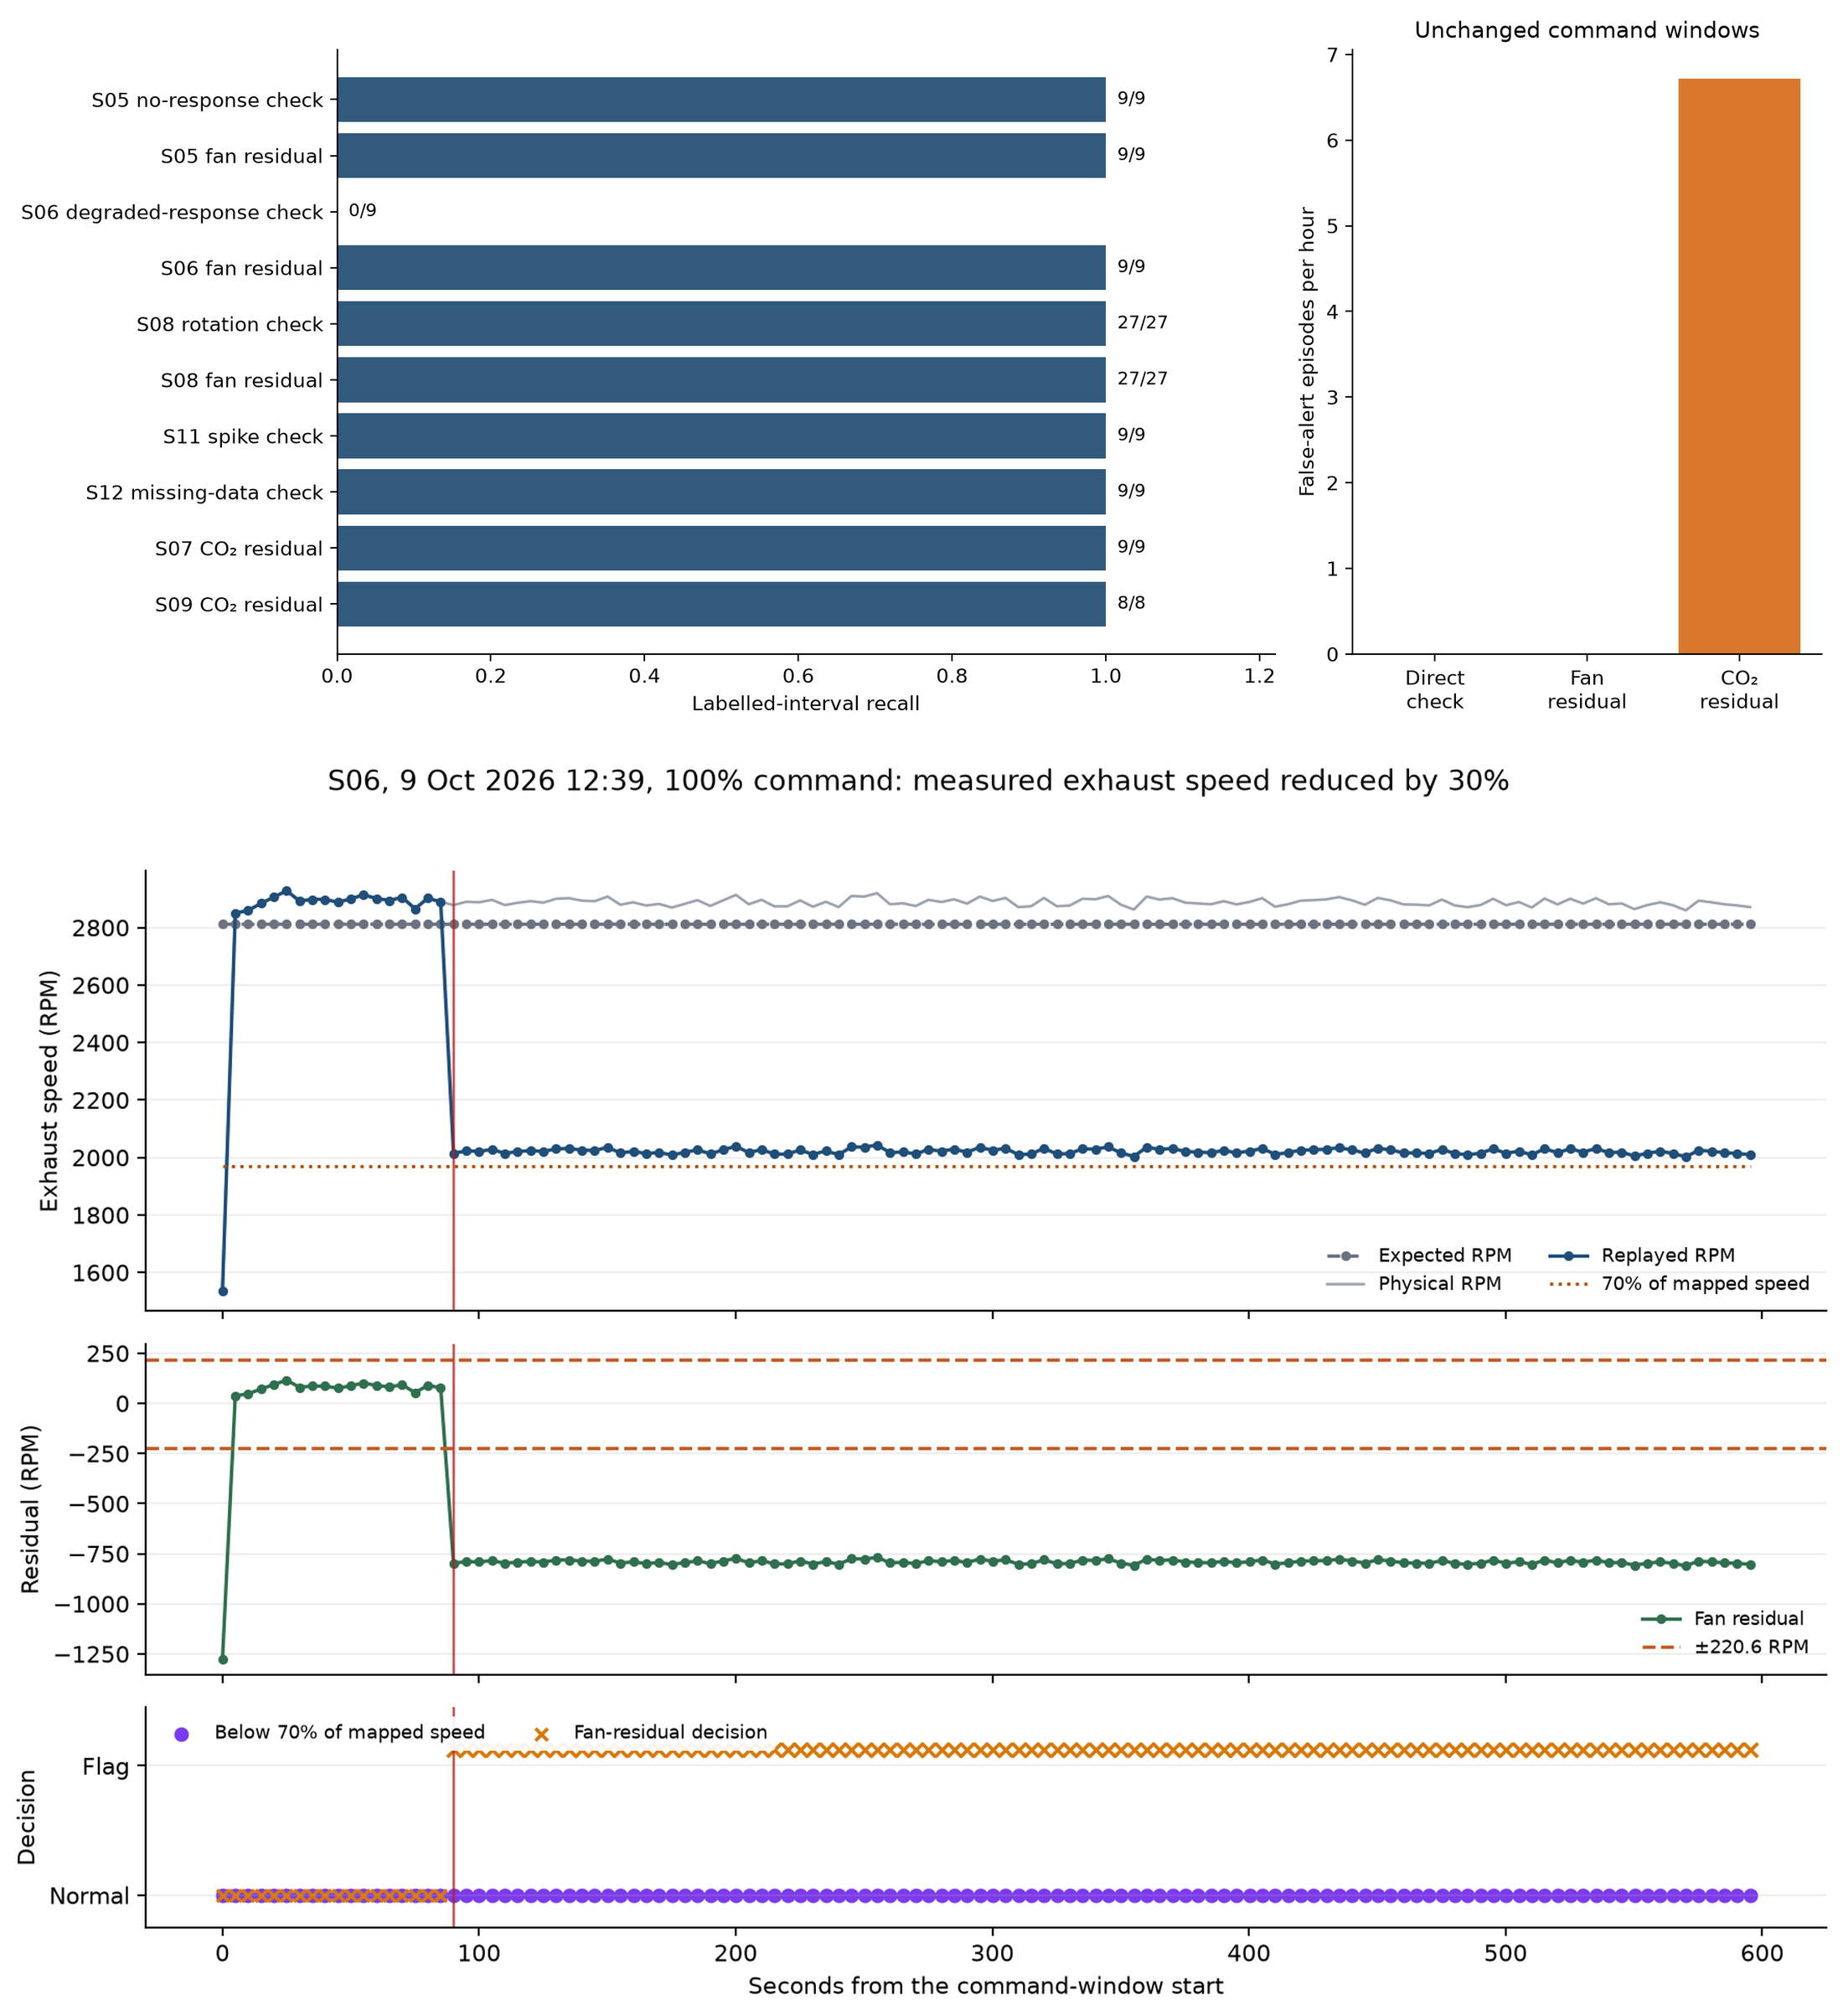

### Anomaly precision recall and F1

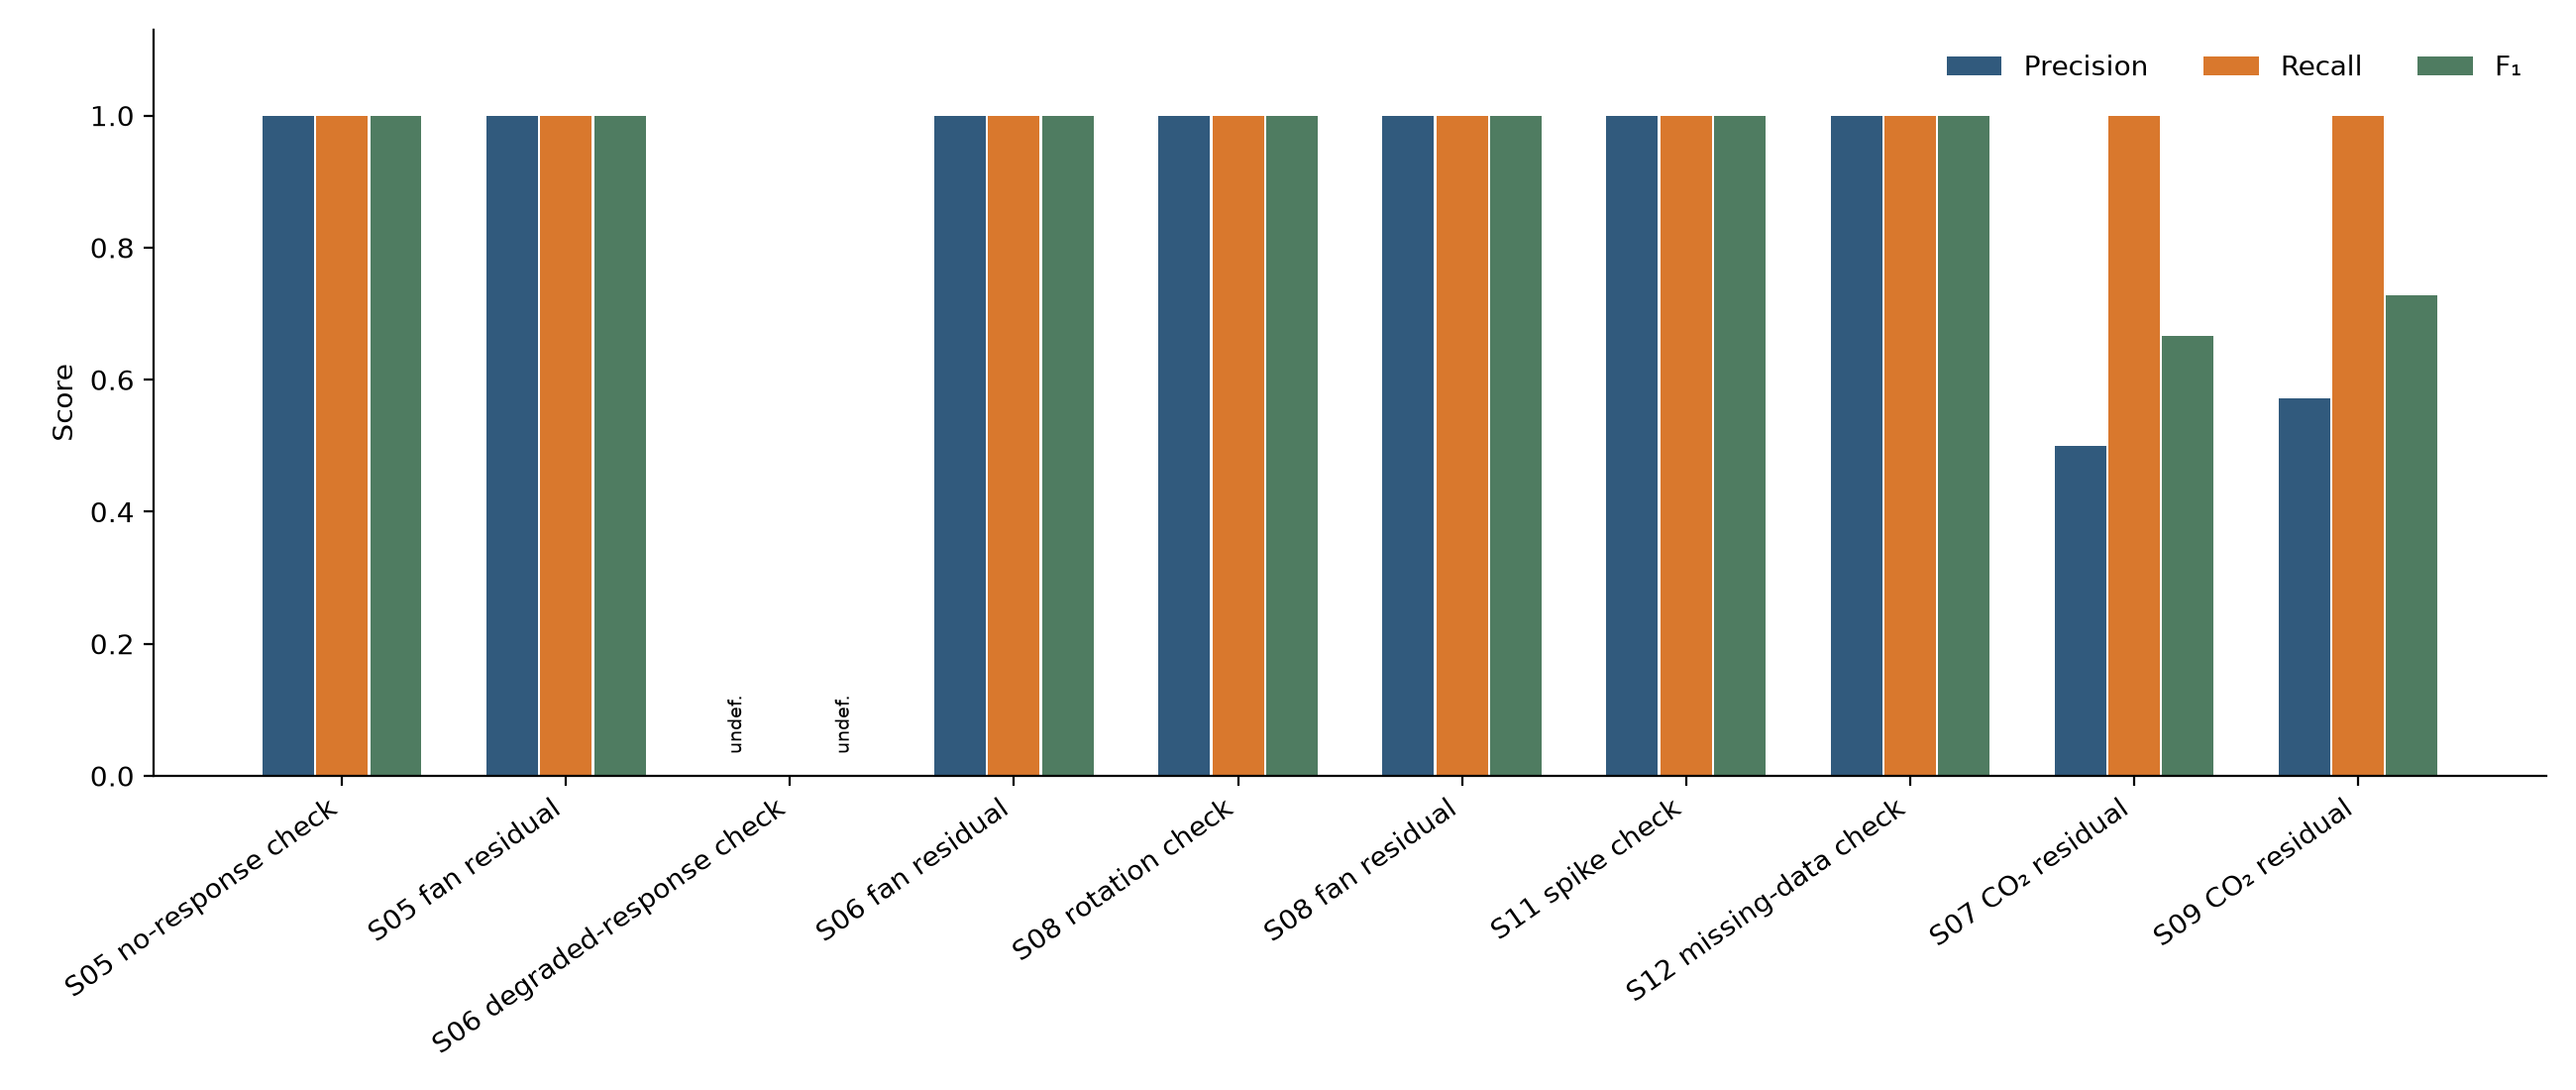

### S07 residual trace

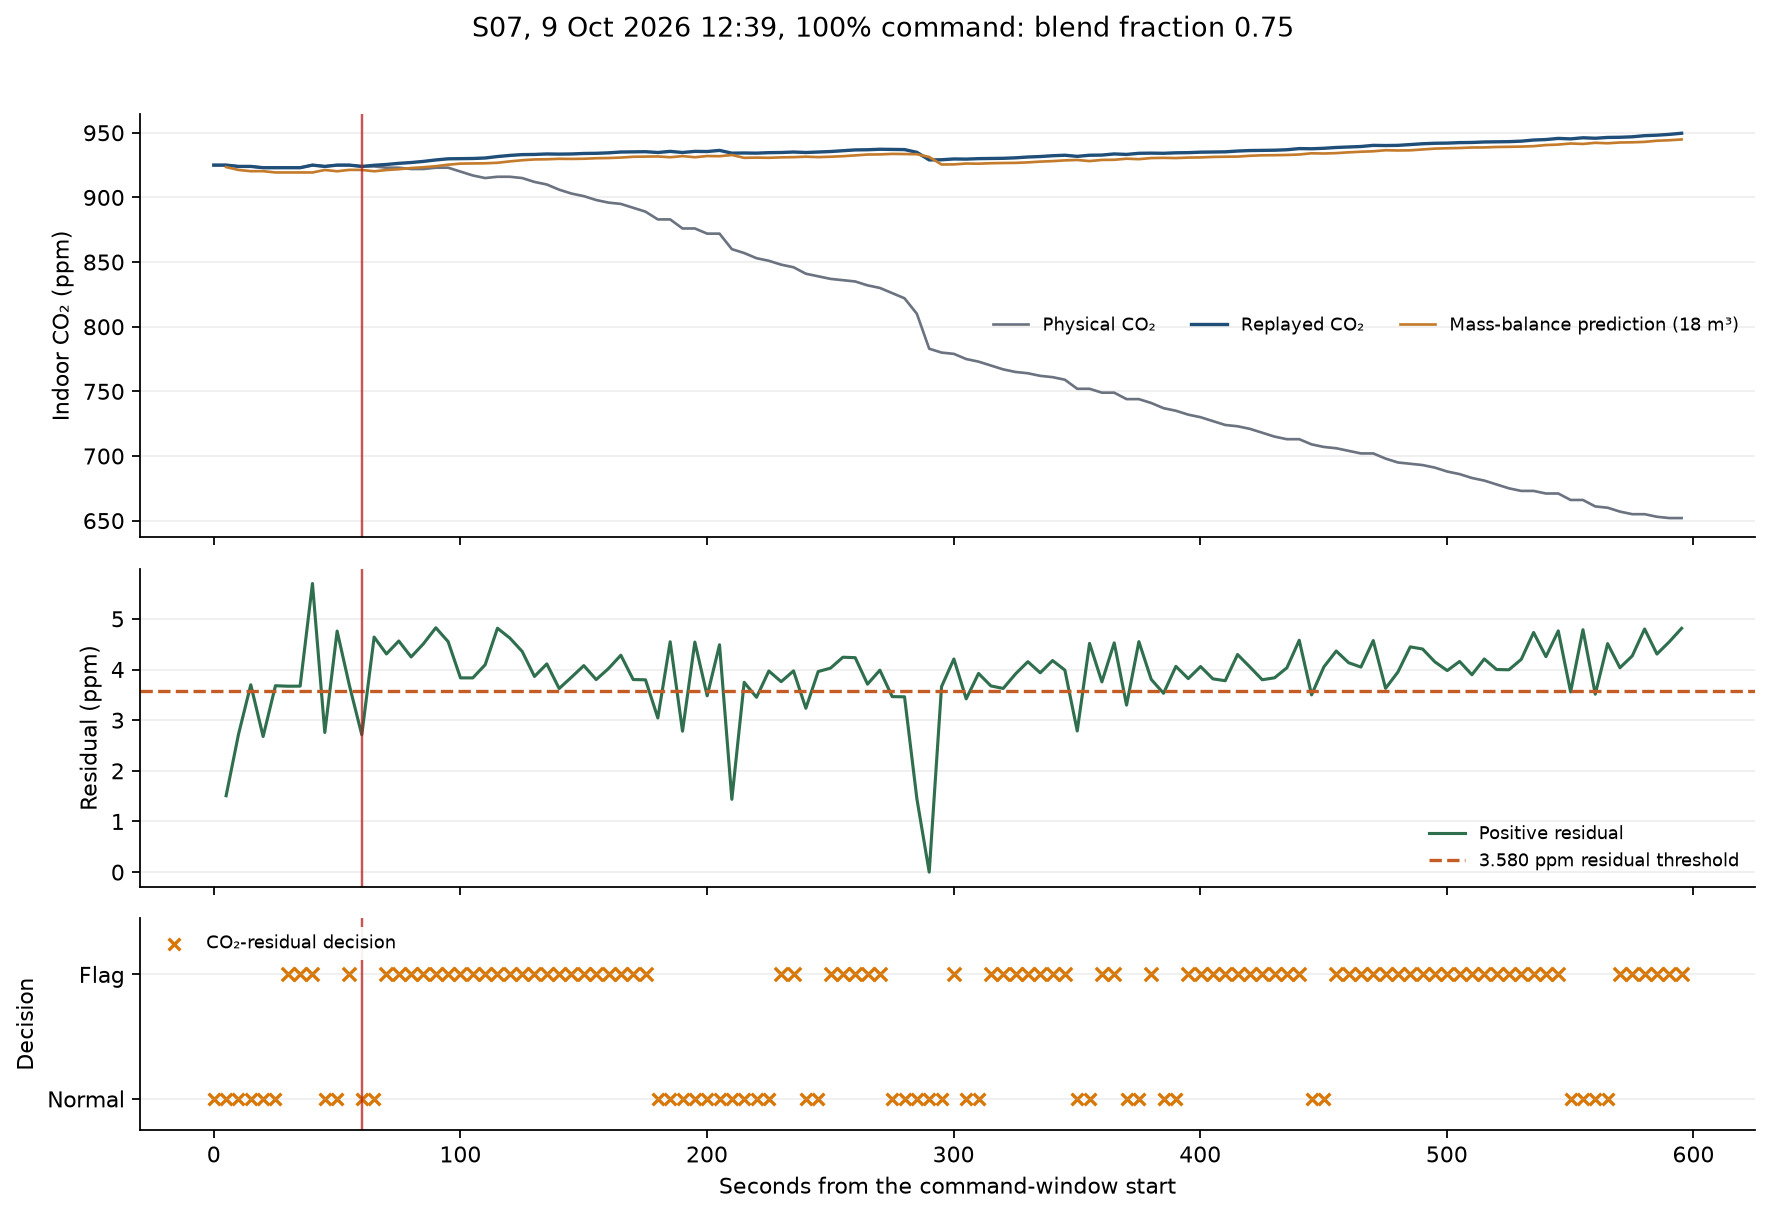

### CO2 coverage and overlap recall

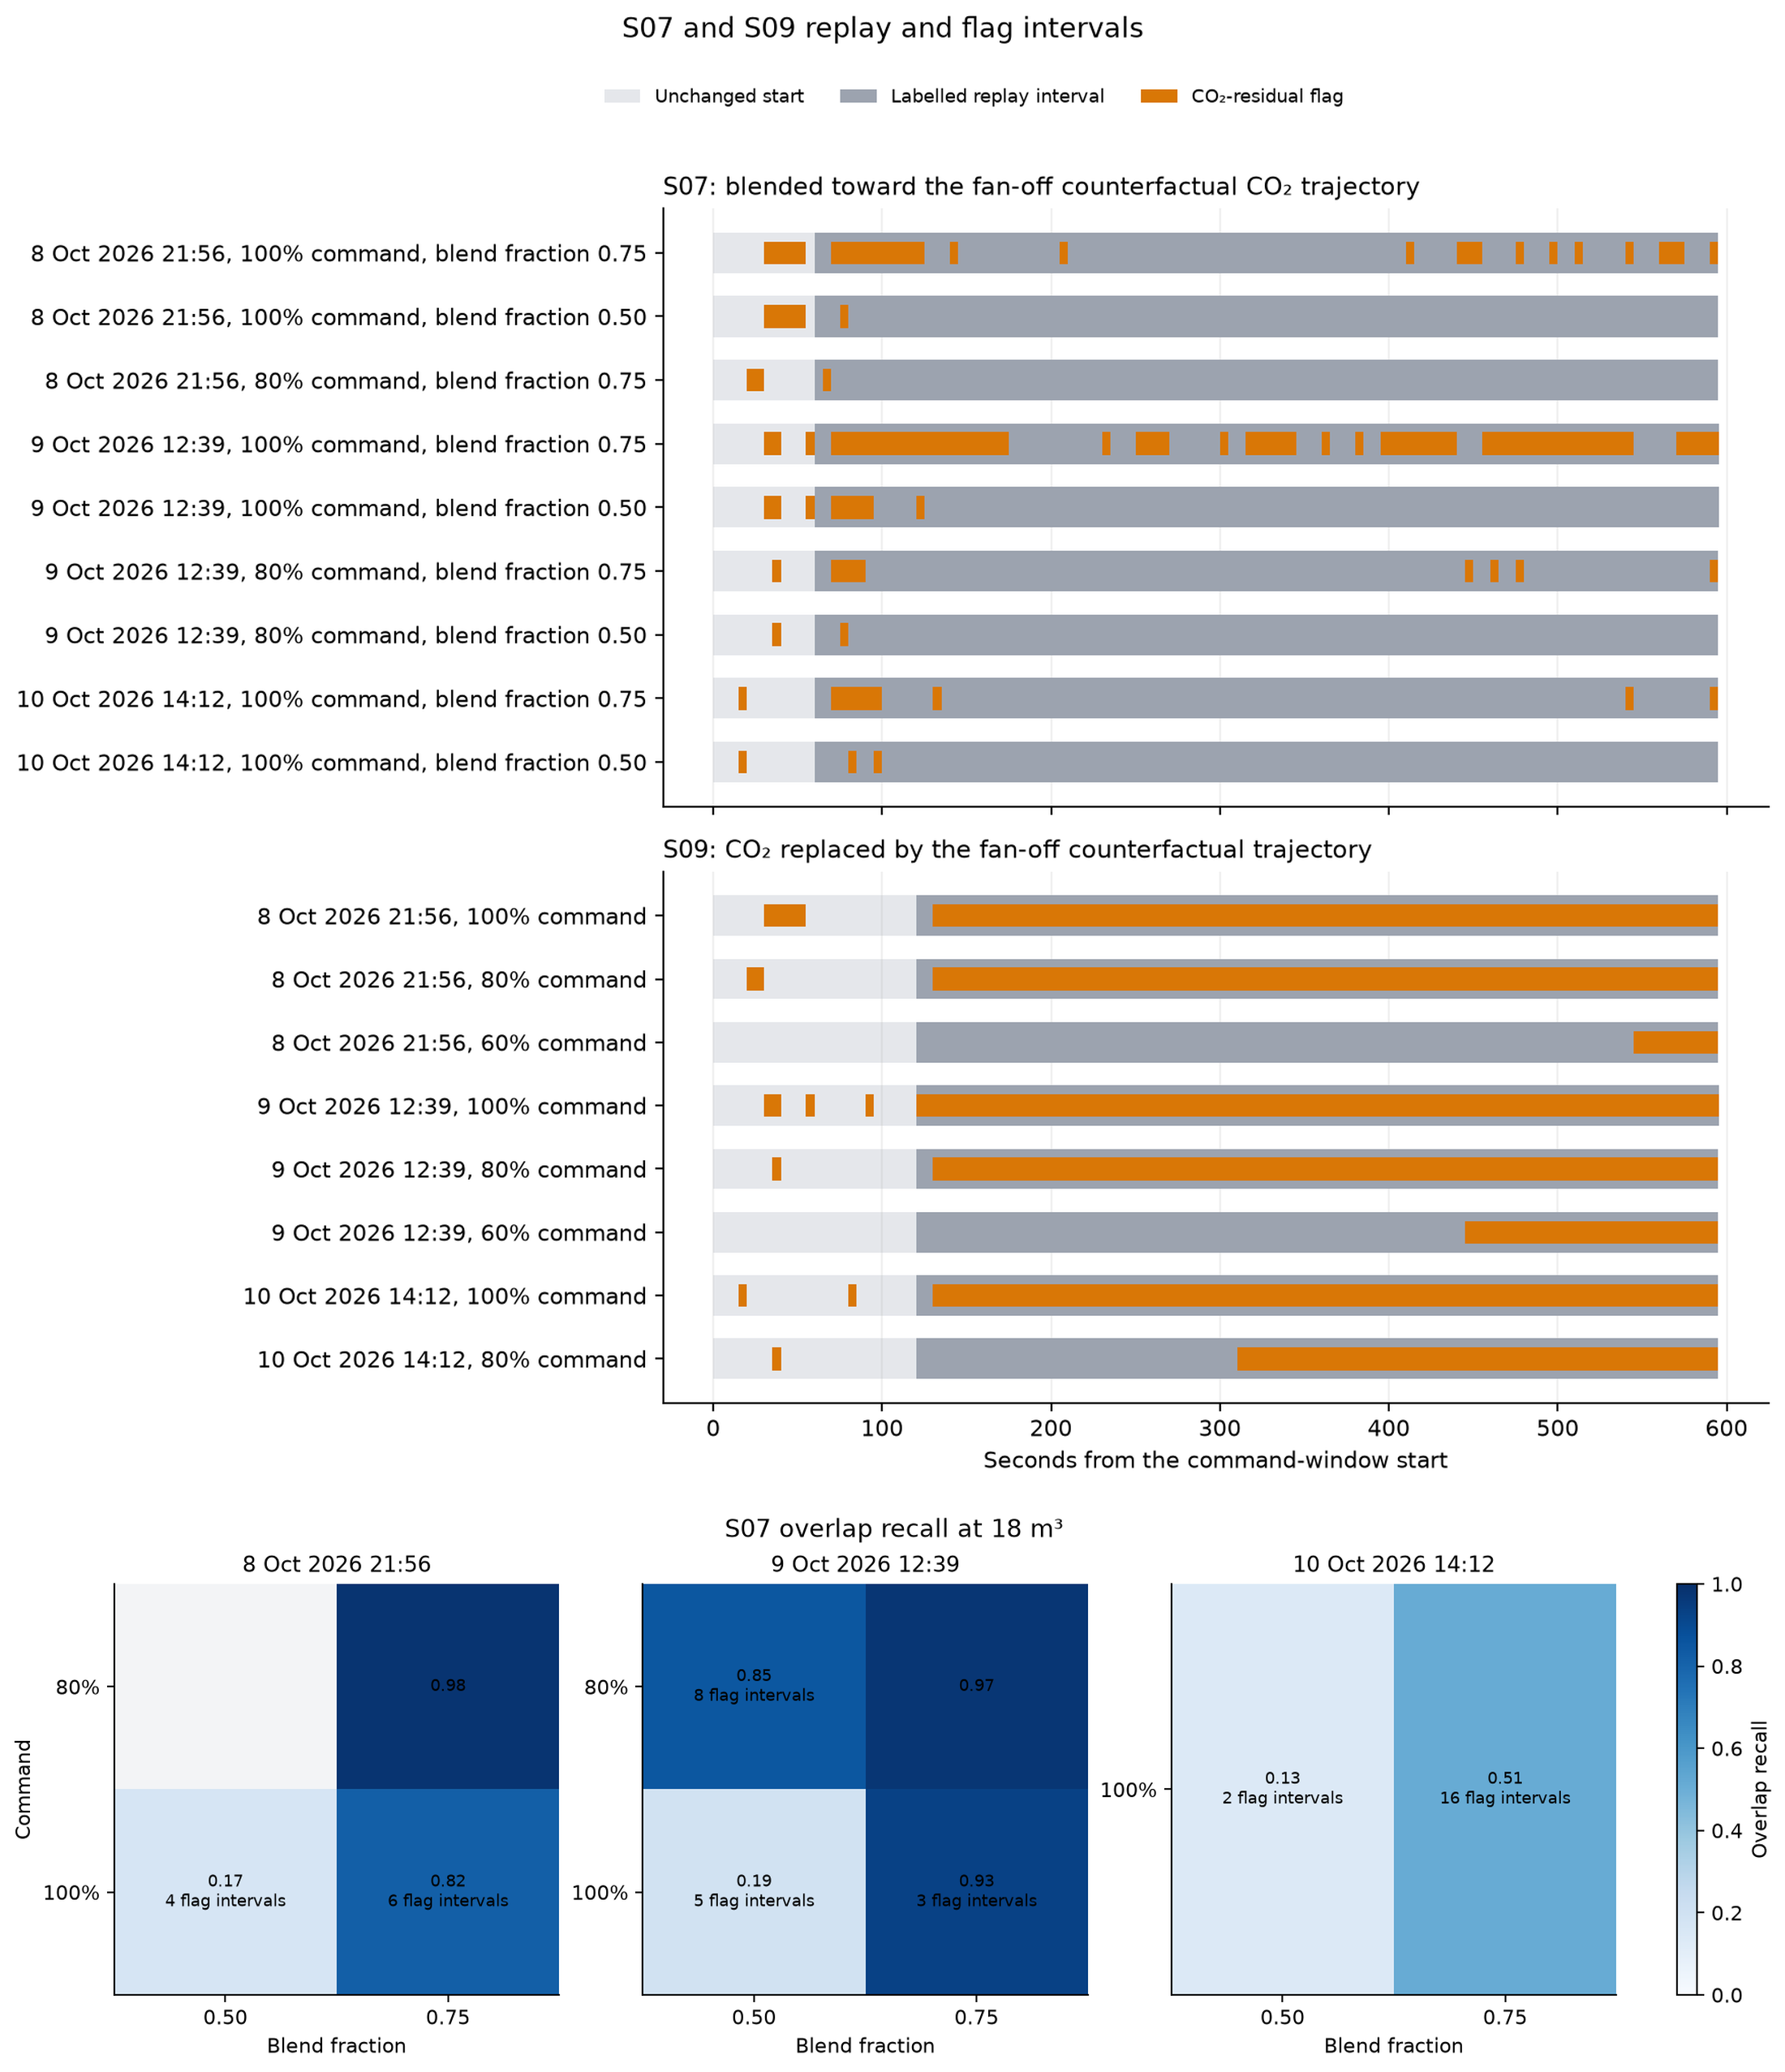

In [34]:
from indoortwin.evidence import display_plots
display_plots("06")
